**Beyond Wafer Shape and Failure Count: A Controlled Spatial-Information Audit of WM-811K**



In [ ]:
# ============================================================
# CELL 1 — Environment setup and reproducibility
# ============================================================
#
# Project:
# Beyond Wafer Shape and Failure Count:
# A Controlled Spatial-Information Audit of WM-811K
#
# Goal of the project:
# We want to investigate how much information about the defect
# class comes from:
#
#   1. the wafer's shape/layout,
#   2. the total number of failed dies,
#   3. the rough radial location of the failed dies, and
#   4. the detailed spatial arrangement of the failed dies.
#
# We will later compare original wafer maps with carefully
# controlled versions in which some spatial information has
# been removed while other properties are kept unchanged.
#
# IMPORTANT:
# We are NOT trying to build the biggest or most accurate CNN.
# The main contribution of this project is the controlled
# experiment and evaluation methodology.
# ============================================================


# ------------------------------------------------------------
# 1. Install a few packages that we will need.
#
# TensorFlow, NumPy, pandas, and matplotlib are normally already
# available in Google Colab, so we do not reinstall them here.
# ------------------------------------------------------------

!pip -q install kaggle opencv-python-headless tqdm


# ------------------------------------------------------------
# 2. Import the basic libraries.
# ------------------------------------------------------------

import os
import sys
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import sklearn

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 3. Fix a random seed.
#
# Machine-learning experiments contain randomness:
# - train/test splitting
# - data shuffling
# - model initialization
# - random perturbations
#
# Using the same seed makes our experiments much easier
# to reproduce.
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)


# ------------------------------------------------------------
# 4. Create folders for the project.
#
# Keeping raw data, cached/preprocessed data, and experiment
# results separate will save us a lot of confusion later.
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/wm811k_spatial_audit")

DATA_DIR = PROJECT_DIR / "data"
CACHE_DIR = PROJECT_DIR / "cache"
OUTPUT_DIR = PROJECT_DIR / "outputs"

for folder in [PROJECT_DIR, DATA_DIR, CACHE_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 5. Print information about the current Colab runtime.
#
# We will save this kind of information because reproducibility
# matters in a research paper. If somebody repeats our work,
# it helps to know which software versions we used.
# ------------------------------------------------------------

print("Project directory :", PROJECT_DIR)
print()
print("Python version    :", sys.version.split()[0])
print("Platform          :", platform.platform())
print("NumPy version     :", np.__version__)
print("pandas version    :", pd.__version__)
print("scikit-learn      :", sklearn.__version__)
print("OpenCV version    :", cv2.__version__)


# ------------------------------------------------------------
# 6. Check whether Colab has given us a GPU.
#
# We do not actually need the GPU yet. Most of the early data
# auditing will run perfectly well on the CPU.
# ------------------------------------------------------------

try:
    import tensorflow as tf

    print("TensorFlow version:", tf.__version__)

    gpus = tf.config.list_physical_devices("GPU")

    if gpus:
        print("GPU detected      :", gpus[0])
    else:
        print("GPU detected      : No GPU currently available")

except Exception as e:
    print("TensorFlow check failed:", e)


# ------------------------------------------------------------
# 7. Final sanity check.
# ------------------------------------------------------------

print()
print("Setup complete.")
print("Next step: obtain and inspect the ORIGINAL WM-811K dataset.")

Project directory : /content/wm811k_spatial_audit

Python version    : 3.13.15
Platform          : Linux-6.6.122+-x86_64-with-glibc2.39
NumPy version     : 2.1.3
pandas version    : 2.2.3
scikit-learn      : 1.6.1
OpenCV version    : 5.0.0
TensorFlow version: 2.20.0
GPU detected      : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Setup complete.
Next step: obtain and inspect the ORIGINAL WM-811K dataset.


In [ ]:
# ============================================================
# CELL 2 — Download and verify the original WM-811K dataset
# ============================================================
#
# In this cell we will:
#
#   1. Read our Kaggle credentials securely from Colab Secrets.
#   2. Download the WM-811K / LSWMD dataset.
#   3. Confirm that LSWMD.pkl exists.
#   4. Record its file size and SHA-256 checksum.
#
# IMPORTANT:
# We are NOT filtering, resizing, shuffling, or changing the
# dataset in this cell.
#
# We first want a reproducible copy of the source data.
# ============================================================


import os
import hashlib
import subprocess
from pathlib import Path


# ------------------------------------------------------------
# 1. Location where the dataset will be stored.
#
# DATA_DIR was created in Cell 1:
#
# /content/wm811k_spatial_audit/data
# ------------------------------------------------------------

DATASET_FILE = DATA_DIR / "LSWMD.pkl"


# ------------------------------------------------------------
# 2. Read Kaggle credentials from Colab Secrets.
#
# Do NOT type your Kaggle key directly into the notebook.
# Keeping it in Colab Secrets prevents it from accidentally
# appearing in a shared notebook.
# ------------------------------------------------------------

from google.colab import userdata

try:
    KAGGLE_USERNAME = userdata.get("KAGGLE_USERNAME")
    KAGGLE_KEY = userdata.get("KAGGLE_KEY")

    if not KAGGLE_USERNAME or not KAGGLE_KEY:
        raise ValueError("One or both Kaggle secrets are empty.")

    os.environ["KAGGLE_USERNAME"] = KAGGLE_USERNAME
    os.environ["KAGGLE_KEY"] = KAGGLE_KEY

    print("Kaggle credentials found.")

except Exception as e:
    raise RuntimeError(
        "Could not read Kaggle credentials.\n"
        "Open the Colab Secrets panel and create:\n"
        "  KAGGLE_USERNAME\n"
        "  KAGGLE_KEY\n"
        "Then allow notebook access to both."
    ) from e


# ------------------------------------------------------------
# 3. Download the dataset.
#
# We use the Kaggle WM-811K mirror:
#
#     qingyi/wm811k-wafer-map
#
# If LSWMD.pkl already exists, we do not download it again.
# ------------------------------------------------------------

if DATASET_FILE.exists():

    print()
    print("Dataset already exists.")
    print("Skipping download.")

else:

    print()
    print("Downloading WM-811K...")
    print("This may take several minutes.")

    command = [
        "kaggle",
        "datasets",
        "download",
        "-d",
        "qingyi/wm811k-wafer-map",
        "-p",
        str(DATA_DIR),
        "--unzip"
    ]

    subprocess.run(command, check=True)

    print()
    print("Download finished.")


# ------------------------------------------------------------
# 4. Make sure the expected file really exists.
# ------------------------------------------------------------

if not DATASET_FILE.exists():

    print("\nFiles found in the data directory:")

    for file in DATA_DIR.iterdir():
        print("  ", file.name)

    raise FileNotFoundError(
        f"Expected file was not found: {DATASET_FILE}"
    )


# ------------------------------------------------------------
# 5. Record the file size.
# ------------------------------------------------------------

size_bytes = DATASET_FILE.stat().st_size
size_mb = size_bytes / (1024 ** 2)
size_gb = size_bytes / (1024 ** 3)

print()
print("Dataset file      :", DATASET_FILE)
print(f"File size         : {size_mb:,.1f} MiB")
print(f"File size         : {size_gb:,.3f} GiB")


# ------------------------------------------------------------
# 6. Compute a SHA-256 checksum.
#
# A checksum is like a fingerprint for a file.
#
# If someone later has exactly the same LSWMD.pkl file,
# they should obtain exactly the same SHA-256 value.
#
# We read the file in chunks so we do not load the entire
# multi-gigabyte pickle into RAM just to calculate the hash.
# ------------------------------------------------------------

def sha256_file(path, chunk_size=8 * 1024 * 1024):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


print()
print("Calculating SHA-256 checksum...")
print("This can take a little while for a large file.")

dataset_sha256 = sha256_file(DATASET_FILE)

print("SHA-256           :", dataset_sha256)


# ------------------------------------------------------------
# 7. Save basic source-data information.
#
# Later, this gives us a permanent record of exactly which
# input file our experiments used.
# ------------------------------------------------------------

dataset_info = {
    "kaggle_dataset": "qingyi/wm811k-wafer-map",
    "filename": DATASET_FILE.name,
    "size_bytes": size_bytes,
    "sha256": dataset_sha256,
}

import json

info_file = OUTPUT_DIR / "dataset_source_info.json"

with open(info_file, "w") as f:
    json.dump(dataset_info, f, indent=2)


# ------------------------------------------------------------
# 8. Final sanity check.
# ------------------------------------------------------------

print()
print("Dataset verification complete.")
print("Source information saved to:")
print(info_file)

print()
print("IMPORTANT: We have not modified the wafer data yet.")
print("Next step: inspect the structure of LSWMD.pkl carefully.")

Kaggle credentials found.

This may take several minutes.

Download finished.

Dataset file      : /content/wm811k_spatial_audit/data/LSWMD.pkl
File size         : 1,998.4 MiB
File size         : 1.952 GiB

Calculating SHA-256 checksum...
This can take a little while for a large file.
SHA-256           : 1d04fccb3dd3176b276878b926b20fead7e077c5751e4d353ea9741a5e7b5c65

Dataset verification complete.
Source information saved to:
/content/wm811k_spatial_audit/outputs/dataset_source_info.json

IMPORTANT: We have not modified the wafer data yet.
Next step: inspect the structure of LSWMD.pkl carefully.


In [ ]:
# ============================================================
# CELL 3 — Audit the untouched WM-811K / LSWMD dataset
# ============================================================
#
# In this cell we will inspect:
#
#   - Number of rows and columns
#   - Column names and data types
#   - Raw label format
#   - Actual defect-label counts
#   - Dataset-provided Training/Test labels
#   - Number of production lots
#   - Wafer-map dimensions
#   - dieSize and waferIndex fields
#   - Missing or malformed values
#
# IMPORTANT:
# We are still NOT changing the dataset.
#
# The goal is to understand the source data before deciding
# which rows belong in our experiment.
# ============================================================


import gc
from collections import Counter

import numpy as np
import pandas as pd
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. Helper for showing RAM usage.
#
# LSWMD.pkl is about 2 GB on disk, but a pickle can use much
# more memory after Python loads all of its objects.
# ------------------------------------------------------------

try:
    import psutil

    def show_memory():
        process = psutil.Process()
        used_gb = process.memory_info().rss / (1024 ** 3)
        available_gb = psutil.virtual_memory().available / (1024 ** 3)

        print(f"Python process RAM : {used_gb:,.2f} GiB")
        print(f"Available system RAM: {available_gb:,.2f} GiB")

except ImportError:

    def show_memory():
        print("psutil is unavailable; skipping RAM report.")


print("Memory before loading dataset:")
show_memory()


# ------------------------------------------------------------
# 2. Load the ORIGINAL pickle.
#
# This can take a while because the dataset contains more than
# 800,000 wafer maps.
# ------------------------------------------------------------

print()
print("Loading LSWMD.pkl...")
print("Please wait — this is the largest object we will load.")

df_raw = pd.read_pickle(DATASET_FILE)

print()
print("Dataset loaded successfully.")

print()
print("Memory after loading dataset:")
show_memory()


# ------------------------------------------------------------
# 3. Basic structure.
# ------------------------------------------------------------

print()
print("=" * 60)
print("BASIC DATASET STRUCTURE")
print("=" * 60)

print("Shape:", df_raw.shape)

print()
print("Columns:")
for column in df_raw.columns:
    print("  -", column)

print()
print("Data types:")
print(df_raw.dtypes)


# ------------------------------------------------------------
# 4. Display a few rows WITHOUT expanding the wafer maps.
#
# Printing entire waferMap arrays would make the output huge.
# ------------------------------------------------------------

preview_columns = [
    col for col in
    ["dieSize", "lotName", "waferIndex",
     "trianTestLabel", "failureType"]
    if col in df_raw.columns
]

print()
print("First five metadata rows:")

display(df_raw[preview_columns].head())


# ------------------------------------------------------------
# 5. Inspect one waferMap object.
#
# WM-811K maps are expected to be 2-D arrays where:
#
#   0 = background / no die
#   1 = functioning die
#   2 = failed die
#
# For now we inspect this rather than assume it.
# ------------------------------------------------------------

first_map = np.asarray(df_raw.iloc[0]["waferMap"])

print()
print("=" * 60)
print("FIRST WAFER-MAP OBJECT")
print("=" * 60)

print("Python type :", type(df_raw.iloc[0]["waferMap"]))
print("Array shape :", first_map.shape)
print("Array dtype :", first_map.dtype)
print("Pixel values:", np.unique(first_map))


# ------------------------------------------------------------
# 6. WM-811K stores some labels inside nested arrays.
#
# For example, something that visually means "Center" may
# actually be stored like:
#
#     array([['Center']], dtype=object)
#
# We need a safe function that converts these nested objects
# into ordinary strings.
#
# IMPORTANT:
# This does NOT modify df_raw.
# It creates separate temporary Series for our audit.
# ------------------------------------------------------------

def unwrap_nested_scalar(value):
    """
    Convert a nested WM-811K metadata value into a plain string.

    Examples:
        array([['Center']])  -> 'Center'
        [['Training']]       -> 'Training'
        empty array          -> ''
        NaN / None           -> ''
    """

    current = value

    # Peel away nested arrays/lists one layer at a time.
    for _ in range(10):

        if isinstance(current, np.ndarray):

            if current.size == 0:
                return ""

            current = current.reshape(-1)[0]

        elif isinstance(current, (list, tuple)):

            if len(current) == 0:
                return ""

            current = current[0]

        else:
            break

    # Handle missing scalar values.
    if current is None:
        return ""

    try:
        if pd.isna(current):
            return ""
    except (TypeError, ValueError):
        pass

    return str(current).strip()


# ------------------------------------------------------------
# 7. Normalize failureType ONLY for analysis.
#
# We retain the original failureType column untouched.
# ------------------------------------------------------------

print()
print("Reading failureType labels...")

failure_label = df_raw["failureType"].map(unwrap_nested_scalar)


print()
print("=" * 60)
print("FAILURE-TYPE COUNTS")
print("=" * 60)

failure_counts = (
    failure_label
    .replace("", "<UNLABELED>")
    .value_counts(dropna=False)
)

print(failure_counts)

print()
print("Number of distinct normalized values:",
      failure_counts.size)


# ------------------------------------------------------------
# 8. Examine the dataset-provided train/test field.
#
# Notice that the original dataset spells this column:
#
#     trianTestLabel
#
# not:
#
#     trainTestLabel
#
# We preserve the original spelling.
# ------------------------------------------------------------

print()
print("Reading trianTestLabel values...")

provided_split = df_raw["trianTestLabel"].map(
    unwrap_nested_scalar
)


print()
print("=" * 60)
print("DATASET-PROVIDED TRAIN/TEST COUNTS")
print("=" * 60)

provided_split_counts = (
    provided_split
    .replace("", "<UNSPECIFIED>")
    .value_counts(dropna=False)
)

print(provided_split_counts)


# ------------------------------------------------------------
# 9. Cross-tab failure class against the provided split.
#
# This lets us see which classes have Training/Test assignments
# and how many samples occur in each part.
# ------------------------------------------------------------

failure_for_table = failure_label.replace(
    "", "<UNLABELED>"
)

split_for_table = provided_split.replace(
    "", "<UNSPECIFIED>"
)

failure_split_table = pd.crosstab(
    failure_for_table,
    split_for_table
)

print()
print("=" * 60)
print("FAILURE TYPE x PROVIDED SPLIT")
print("=" * 60)

display(failure_split_table)


# ------------------------------------------------------------
# 10. Audit production lots.
#
# lotName is extremely important for this project because
# wafers from the same manufacturing lot may be related.
# ------------------------------------------------------------

print()
print("=" * 60)
print("PRODUCTION-LOT AUDIT")
print("=" * 60)

lot_missing = int(df_raw["lotName"].isna().sum())
lot_unique = int(df_raw["lotName"].nunique(dropna=True))

print("Unique non-missing lots :", f"{lot_unique:,}")
print("Rows with missing lotName:", f"{lot_missing:,}")


lot_sizes = df_raw["lotName"].value_counts(dropna=False)

print()
print("Number of wafers per lot:")
display(
    lot_sizes.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("wafer_count_per_lot")
)


# ------------------------------------------------------------
# 11. Audit wafer-map dimensions.
#
# We intentionally DO NOT resize anything.
#
# We walk through the maps and count their original
# (height, width) dimensions.
# ------------------------------------------------------------

print()
print("=" * 60)
print("ORIGINAL WAFER-MAP DIMENSIONS")
print("=" * 60)

shape_counter = Counter()

invalid_map_count = 0

min_height = None
max_height = None
min_width = None
max_width = None


for wafer in tqdm(
    df_raw["waferMap"],
    total=len(df_raw),
    desc="Checking original map dimensions"
):

    arr = np.asarray(wafer)

    # A valid wafer map should be a non-empty 2-D array.
    if arr.ndim != 2 or arr.size == 0:
        invalid_map_count += 1
        continue

    height, width = arr.shape

    shape_counter[(height, width)] += 1

    if min_height is None:
        min_height = max_height = height
        min_width = max_width = width
    else:
        min_height = min(min_height, height)
        max_height = max(max_height, height)

        min_width = min(min_width, width)
        max_width = max(max_width, width)


shape_table = pd.DataFrame(
    [
        {
            "height": h,
            "width": w,
            "count": count
        }
        for (h, w), count in shape_counter.items()
    ]
).sort_values(
    "count",
    ascending=False
).reset_index(drop=True)


print()
print("Valid 2-D maps       :",
      f"{len(df_raw) - invalid_map_count:,}")

print("Invalid/empty maps   :",
      f"{invalid_map_count:,}")

print("Unique map dimensions:",
      f"{len(shape_counter):,}")

print()
print("Height range:",
      min_height, "to", max_height)

print("Width range :",
      min_width, "to", max_width)


print()
print("20 most common original dimensions:")

display(shape_table.head(20))


# ------------------------------------------------------------
# 12. Audit dieSize.
#
# We do not assume every value is numeric.
# ------------------------------------------------------------

die_size_numeric = pd.to_numeric(
    df_raw["dieSize"],
    errors="coerce"
)

print()
print("=" * 60)
print("dieSize AUDIT")
print("=" * 60)

print(
    die_size_numeric.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print()
print(
    "Non-numeric/missing dieSize:",
    f"{die_size_numeric.isna().sum():,}"
)


# ------------------------------------------------------------
# 13. Audit waferIndex.
# ------------------------------------------------------------

wafer_index_numeric = pd.to_numeric(
    df_raw["waferIndex"],
    errors="coerce"
)

print()
print("=" * 60)
print("waferIndex AUDIT")
print("=" * 60)

print(
    wafer_index_numeric.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print()
print(
    "Non-numeric/missing waferIndex:",
    f"{wafer_index_numeric.isna().sum():,}"
)


# ------------------------------------------------------------
# 14. Produce a compact summary.
#
# These are observations about the untouched dataset.
# ------------------------------------------------------------

raw_audit_summary = {
    "rows": int(df_raw.shape[0]),
    "columns": int(df_raw.shape[1]),

    "column_names": list(df_raw.columns),

    "unique_normalized_failure_values":
        int(failure_counts.size),

    "unlabeled_rows":
        int((failure_label == "").sum()),

    "unique_non_missing_lots":
        lot_unique,

    "missing_lot_rows":
        lot_missing,

    "valid_2d_wafer_maps":
        int(len(df_raw) - invalid_map_count),

    "invalid_or_empty_wafer_maps":
        int(invalid_map_count),

    "unique_original_map_shapes":
        int(len(shape_counter)),

    "minimum_height":
        int(min_height) if min_height is not None else None,

    "maximum_height":
        int(max_height) if max_height is not None else None,

    "minimum_width":
        int(min_width) if min_width is not None else None,

    "maximum_width":
        int(max_width) if max_width is not None else None,
}


# ------------------------------------------------------------
# 15. Save the audit results.
#
# These small files are useful later for reproducibility and
# for checking that a future run used the same raw dataset.
# ------------------------------------------------------------

import json

with open(
    OUTPUT_DIR / "raw_dataset_audit.json",
    "w"
) as f:

    json.dump(
        raw_audit_summary,
        f,
        indent=2
    )


failure_counts.rename(
    "count"
).to_csv(
    OUTPUT_DIR / "raw_failure_type_counts.csv"
)


provided_split_counts.rename(
    "count"
).to_csv(
    OUTPUT_DIR / "raw_provided_split_counts.csv"
)


failure_split_table.to_csv(
    OUTPUT_DIR / "raw_failure_by_provided_split.csv"
)


shape_table.to_csv(
    OUTPUT_DIR / "raw_map_shape_counts.csv",
    index=False
)


# ------------------------------------------------------------
# 16. Clean up temporary numeric Series.
#
# We KEEP:
#
#   df_raw
#   failure_label
#   provided_split
#
# because we will use them in the next cell.
#
# The large wafer maps themselves have still not been copied
# or changed.
# ------------------------------------------------------------

del die_size_numeric
del wafer_index_numeric

gc.collect()


# ------------------------------------------------------------
# 17. Final summary.
# ------------------------------------------------------------

print()
print("=" * 60)
print("RAW DATASET AUDIT COMPLETE")
print("=" * 60)

for key, value in raw_audit_summary.items():

    if key != "column_names":
        print(f"{key:35s}: {value}")

print()
print("Audit files saved in:")
print(OUTPUT_DIR)

print()
print("No wafer maps have been filtered, resized,")
print("balanced, augmented, or split by us yet.")

Memory before loading dataset:
Python process RAM : 1.01 GiB
Available system RAM: 10.95 GiB

Loading LSWMD.pkl...
Please wait — this is the largest object we will load.

Dataset loaded successfully.

Memory after loading dataset:
Python process RAM : 3.58 GiB
Available system RAM: 8.32 GiB

BASIC DATASET STRUCTURE
Shape: (811457, 6)

Columns:
  - waferMap
  - dieSize
  - lotName
  - waferIndex
  - trianTestLabel
  - failureType

Data types:
waferMap           object
dieSize           float64
lotName            object
waferIndex        float64
trianTestLabel     object
failureType        object
dtype: object

First five metadata rows:


,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,1683.0,lot1,1.0,[[Training]],[[none]]
1,1683.0,lot1,2.0,[[Training]],[[none]]
2,1683.0,lot1,3.0,[[Training]],[[none]]
3,1683.0,lot1,4.0,[[Training]],[[none]]
4,1683.0,lot1,5.0,[[Training]],[[none]]



FIRST WAFER-MAP OBJECT
Python type : <class 'numpy.ndarray'>
Array shape : (45, 48)
Array dtype : uint8
Pixel values: [0 1 2]

Reading failureType labels...

FAILURE-TYPE COUNTS
failureType
<UNLABELED>    638507
none           147431
Edge-Ring        9680
Edge-Loc         5189
Center           4294
Loc              3593
Scratch          1193
Random            866
Donut             555
Near-full         149
Name: count, dtype: int64

Number of distinct normalized values: 10

Reading trianTestLabel values...

DATASET-PROVIDED TRAIN/TEST COUNTS
trianTestLabel
<UNSPECIFIED>    638507
Test             118595
Training          54355
Name: count, dtype: int64

FAILURE TYPE x PROVIDED SPLIT


trianTestLabel,<UNSPECIFIED>,Test,Training
failureType,,,
<UNLABELED>,638507,0,0
Center,0,832,3462
Donut,0,146,409
Edge-Loc,0,2772,2417
Edge-Ring,0,1126,8554
Loc,0,1973,1620
Near-full,0,95,54
Random,0,257,609
Scratch,0,693,500



PRODUCTION-LOT AUDIT
Unique non-missing lots : 46,293
Rows with missing lotName: 0

Number of wafers per lot:


,wafer_count_per_lot
count,46293.000000
mean,17.528719
std,8.964477
min,1.000000
25%,10.000000
50%,24.000000
75%,25.000000
90%,25.000000
95%,25.000000
99%,25.000000



ORIGINAL WAFER-MAP DIMENSIONS


Checking original map dimensions:   0%|          | 0/811457 [00:00<?, ?it/s]


Valid 2-D maps       : 811,457
Invalid/empty maps   : 0
Unique map dimensions: 632

Height range: 6 to 300
Width range : 3 to 205

20 most common original dimensions:


,height,width,count
0,32,29,108687
1,25,27,64083
2,49,39,39323
3,26,26,30078
4,30,34,29513
5,33,33,23886
6,33,29,20276
7,39,37,15327
8,52,59,14812
9,31,31,14569



dieSize AUDIT
count    811457.000000
mean       1840.998585
std        2254.987374
min           3.000000
25%         710.000000
50%         953.000000
75%        1902.000000
90%        4096.000000
95%        5633.000000
99%       14116.000000
max       48099.000000
Name: dieSize, dtype: float64

Non-numeric/missing dieSize: 0

waferIndex AUDIT
count    811457.000000
mean         12.961207
std           7.207489
min           1.000000
25%           7.000000
50%          13.000000
75%          19.000000
90%          23.000000
95%          24.000000
99%          25.000000
max          25.000000
Name: waferIndex, dtype: float64

Non-numeric/missing waferIndex: 0

RAW DATASET AUDIT COMPLETE
rows                               : 811457
columns                            : 6
unique_normalized_failure_values   : 10
unlabeled_rows                     : 638507
unique_non_missing_lots            : 46293
missing_lot_rows                   : 0
valid_2d_wafer_maps                : 811457
invalid_or

In [ ]:
# ============================================================
# CELL 4 — Defect subset, production-lot, and layout audit
# ============================================================
#
# In Cell 3 we examined all 811,457 wafer maps.
#
# Our PRIMARY research task will use only the eight actual
# defect-pattern classes:
#
#   Center
#   Donut
#   Edge-Loc
#   Edge-Ring
#   Loc
#   Near-full
#   Random
#   Scratch
#
# We intentionally exclude:
#
#   1. unlabeled wafers
#   2. wafers labeled "none"
#
# Why?
#
# Because our primary question is:
#
#   "Given that a wafer has a recognized defect pattern,
#    what information is needed to distinguish the type?"
#
# That makes this an 8-class DEFECT-TYPE CLASSIFICATION task.
#
# ------------------------------------------------------------
#
# This cell answers:
#
#   1. How many production lots contain defect wafers?
#
#   2. How many defect wafers occur in each lot?
#
#   3. Can multiple defect classes occur in the same lot?
#
#   4. How "pure" are lots with respect to defect class?
#
#   5. Does the ORIGINAL Training/Test assignment put the
#      same lot on both sides?
#
#   6. How many test wafers come from lots seen in training?
#
#   7. How many different native wafer layouts occur?
#
#   8. Are layouts reused across different defect classes?
#
#   9. How strongly do classes differ in their number and
#      fraction of failed dies?
#
# IMPORTANT:
#
# No wafer is resized, augmented, shuffled, balanced,
# normalized, or assigned to one of OUR train/test splits here.
#
# ============================================================


import gc
import hashlib
import json

import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. Define the eight defect classes used in our primary study.
# ------------------------------------------------------------

DEFECT_CLASSES = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]


# ------------------------------------------------------------
# 2. First create a SMALL metadata table for ALL labeled wafers.
#
# This includes "none" as well as the eight defect classes.
#
# It does NOT contain waferMap, so it occupies much less RAM
# than the original 811,457-row DataFrame.
#
# We keep this because we may later want to compare the
# original labeled-dataset split with the defect-only subset.
# ------------------------------------------------------------

labeled_mask = failure_label != ""

labeled_metadata = df_raw.loc[
    labeled_mask,
    [
        "dieSize",
        "lotName",
        "waferIndex"
    ]
].copy()

labeled_metadata["orig_index"] = df_raw.index[labeled_mask]
labeled_metadata["label"] = failure_label.loc[labeled_mask].to_numpy()
labeled_metadata["provided_split"] = (
    provided_split.loc[labeled_mask].to_numpy()
)

labeled_metadata.reset_index(drop=True, inplace=True)


print("=" * 65)
print("LABELED DATASET")
print("=" * 65)

print("Labeled wafers :", f"{len(labeled_metadata):,}")
print(
    "Unique lots    :",
    f"{labeled_metadata['lotName'].nunique():,}"
)

print()


# ------------------------------------------------------------
# 3. Create our PRIMARY eight-defect subset.
#
# Unlike labeled_metadata, this table DOES keep waferMap,
# because these are the maps we will actually analyze.
#
# Object columns hold references to the selected arrays, so
# this is much smaller than retaining all 811,457 wafer maps.
# ------------------------------------------------------------

defect_mask = failure_label.isin(DEFECT_CLASSES)

defects = df_raw.loc[
    defect_mask,
    [
        "waferMap",
        "dieSize",
        "lotName",
        "waferIndex"
    ]
].copy()

defects["orig_index"] = df_raw.index[defect_mask]

defects["label"] = (
    failure_label.loc[defect_mask].to_numpy()
)

defects["provided_split"] = (
    provided_split.loc[defect_mask].to_numpy()
)

defects.reset_index(drop=True, inplace=True)


print("=" * 65)
print("PRIMARY EIGHT-DEFECT SUBSET")
print("=" * 65)

print("Defect wafers :", f"{len(defects):,}")
print(
    "Unique lots   :",
    f"{defects['lotName'].nunique():,}"
)

print()


# Because we already verified this exact Kaggle file by SHA-256,
# 25,519 is an expected sanity check.
#
# If this fails, STOP rather than silently continuing.

assert len(defects) == 25_519, (
    "Expected 25,519 labeled defect wafers, "
    f"but found {len(defects):,}."
)


# ------------------------------------------------------------
# 4. Calculate native properties of every defect wafer.
#
# We do this BEFORE any resizing.
#
# For each map:
#
#   active_dies = number of grid cells containing an actual die
#                 i.e. values 1 or 2
#
#   failed_dies = number of cells whose value is 2
#
#   failure_fraction = failed_dies / active_dies
#
# These quantities are very important to our research question.
# ------------------------------------------------------------

native_heights = []
native_widths = []
active_die_counts = []
failed_die_counts = []


print("Calculating native wafer statistics...")


for wafer in tqdm(
    defects["waferMap"],
    total=len(defects),
    desc="Native wafer statistics"
):

    arr = np.asarray(wafer)

    height, width = arr.shape

    native_heights.append(height)
    native_widths.append(width)

    active_die_counts.append(
        int(np.count_nonzero(arr > 0))
    )

    failed_die_counts.append(
        int(np.count_nonzero(arr == 2))
    )


defects["height"] = np.asarray(
    native_heights,
    dtype=np.int16
)

defects["width"] = np.asarray(
    native_widths,
    dtype=np.int16
)

defects["aspect_ratio"] = (
    defects["width"] / defects["height"]
)

defects["active_dies"] = np.asarray(
    active_die_counts,
    dtype=np.int32
)

defects["failed_dies"] = np.asarray(
    failed_die_counts,
    dtype=np.int32
)

defects["failure_fraction"] = (
    defects["failed_dies"] /
    defects["active_dies"]
)


# ------------------------------------------------------------
# 5. Check what dieSize appears to mean.
#
# The dataset already contains a dieSize column.
#
# Rather than assume that dieSize means "number of active dies",
# we compare it to what we independently counted from waferMap.
# ------------------------------------------------------------

die_size_matches = (
    defects["dieSize"].astype(np.int64)
    ==
    defects["active_dies"].astype(np.int64)
)

print()
print("=" * 65)
print("dieSize CONSISTENCY CHECK")
print("=" * 65)

print(
    "Exact matches between dieSize and counted active dies:",
    f"{die_size_matches.sum():,}",
    "/",
    f"{len(defects):,}"
)

print(
    "Match percentage:",
    f"{100 * die_size_matches.mean():.3f}%"
)

print()


# ------------------------------------------------------------
# 6. Defect samples and production lots by class.
#
# This tells us whether some classes occur across many lots
# while others are concentrated within relatively few lots.
# ------------------------------------------------------------

class_lot_summary = (
    defects
    .groupby("label", observed=True)
    .agg(
        wafers=("label", "size"),
        unique_lots=("lotName", "nunique"),
        unique_shapes=("height", "size")
    )
)


# The previous unique_shapes column above is temporarily just
# the number of samples. We replace it below with the actual
# number of distinct (height, width) combinations.

shape_strings = (
    defects["height"].astype(str)
    + "x"
    + defects["width"].astype(str)
)

defects["native_shape"] = shape_strings

actual_shape_counts = (
    defects
    .groupby("label", observed=True)["native_shape"]
    .nunique()
)

class_lot_summary["unique_shapes"] = actual_shape_counts


# Reorder classes in the scientifically meaningful order.

class_lot_summary = class_lot_summary.reindex(
    DEFECT_CLASSES
)


print("=" * 65)
print("CLASS AND LOT SUMMARY")
print("=" * 65)

display(class_lot_summary)

print()


# ------------------------------------------------------------
# 7. How many defect wafers occur in each relevant lot?
# ------------------------------------------------------------

defect_wafers_per_lot = (
    defects["lotName"]
    .value_counts()
)


print("=" * 65)
print("DEFECT WAFERS PER RELEVANT LOT")
print("=" * 65)

display(
    defect_wafers_per_lot
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .to_frame("defect_wafers_per_lot")
)

print()


# ------------------------------------------------------------
# 8. Determine whether individual lots contain multiple
#    different DEFECT classes.
#
# Note:
# We are examining the eight defect classes here.
# "none" wafers are not included in this calculation.
# ------------------------------------------------------------

lot_class_counts = pd.crosstab(
    defects["lotName"],
    defects["label"]
).reindex(
    columns=DEFECT_CLASSES,
    fill_value=0
)


number_of_defect_classes_per_lot = (
    (lot_class_counts > 0)
    .sum(axis=1)
)


mixed_defect_lots = (
    number_of_defect_classes_per_lot > 1
)


print("=" * 65)
print("MULTIPLE DEFECT CLASSES WITHIN THE SAME LOT")
print("=" * 65)

print(
    "Lots containing defect wafers:",
    f"{len(lot_class_counts):,}"
)

print(
    "Lots containing exactly one defect class:",
    f"{(~mixed_defect_lots).sum():,}"
)

print(
    "Lots containing multiple defect classes:",
    f"{mixed_defect_lots.sum():,}"
)

print(
    "Percentage of defect-containing lots that are mixed:",
    f"{100 * mixed_defect_lots.mean():.2f}%"
)

print()


print("Number of defect classes occurring in each lot:")

display(
    number_of_defect_classes_per_lot
    .value_counts()
    .sort_index()
    .rename("number_of_lots")
    .to_frame()
)

print()


# ------------------------------------------------------------
# 9. Calculate LOT PURITY.
#
# Example:
#
# Suppose a lot contains:
#
#   8 Center wafers
#   2 Scratch wafers
#
# Its dominant-class fraction is:
#
#       8 / 10 = 0.80
#
# A value of 1.0 means all defect wafers in that lot have the
# same defect label.
#
# Again, this calculation considers only the eight defects.
# ------------------------------------------------------------

lot_defect_totals = lot_class_counts.sum(axis=1)

lot_purity = (
    lot_class_counts.max(axis=1)
    /
    lot_defect_totals
)


print("=" * 65)
print("LOT PURITY AMONG THE EIGHT DEFECT CLASSES")
print("=" * 65)

display(
    lot_purity
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .to_frame("dominant_class_fraction")
)

print()


# ------------------------------------------------------------
# 10. Function for auditing original Training/Test overlap
#     by production lot.
#
# We use this twice:
#
#   A. all 172,950 labeled wafers
#   B. our 25,519 eight-defect subset
# ------------------------------------------------------------

def audit_provided_lot_overlap(frame, name):

    train = frame[
        frame["provided_split"] == "Training"
    ]

    test = frame[
        frame["provided_split"] == "Test"
    ]

    train_lots = set(train["lotName"])
    test_lots = set(test["lotName"])

    overlap_lots = train_lots.intersection(
        test_lots
    )

    test_from_seen_lot = (
        test["lotName"].isin(train_lots)
    )

    train_from_overlap_lot = (
        train["lotName"].isin(overlap_lots)
    )

    all_from_overlap_lot = (
        frame["lotName"].isin(overlap_lots)
    )

    result = {
        "dataset": name,

        "training_wafers":
            int(len(train)),

        "test_wafers":
            int(len(test)),

        "training_lots":
            int(len(train_lots)),

        "test_lots":
            int(len(test_lots)),

        "lots_present_in_both_training_and_test":
            int(len(overlap_lots)),

        "test_wafers_from_lots_seen_in_training":
            int(test_from_seen_lot.sum()),

        "percent_test_wafers_from_seen_lots":
            float(
                100 *
                test_from_seen_lot.mean()
            ),

        "training_wafers_in_overlapping_lots":
            int(train_from_overlap_lot.sum()),

        "all_wafers_in_overlapping_lots":
            int(all_from_overlap_lot.sum())
    }

    return result, overlap_lots


# ------------------------------------------------------------
# 11. Audit provided-split lot overlap for ALL labeled wafers.
# ------------------------------------------------------------

all_labeled_overlap, all_labeled_overlap_lots = (
    audit_provided_lot_overlap(
        labeled_metadata,
        "all_labeled_9_classes"
    )
)


# ------------------------------------------------------------
# 12. Audit provided-split lot overlap for our eight defects.
# ------------------------------------------------------------

defect_overlap, defect_overlap_lots = (
    audit_provided_lot_overlap(
        defects,
        "eight_defect_classes"
    )
)


overlap_summary = pd.DataFrame(
    [
        all_labeled_overlap,
        defect_overlap
    ]
)


print("=" * 65)
print("ORIGINAL Training/Test LOT OVERLAP")
print("=" * 65)

display(overlap_summary)

print()


# ------------------------------------------------------------
# 13. Save detailed information about overlapping defect lots.
#
# We do NOT print all of these rows because there could be many.
# ------------------------------------------------------------

overlap_defect_rows = (
    defects[
        defects["lotName"].isin(
            defect_overlap_lots
        )
    ][
        [
            "orig_index",
            "lotName",
            "waferIndex",
            "label",
            "provided_split"
        ]
    ]
    .sort_values(
        [
            "lotName",
            "provided_split",
            "waferIndex"
        ]
    )
)


print(
    "Defect-wafer rows belonging to overlapping lots:",
    f"{len(overlap_defect_rows):,}"
)

print()


# ------------------------------------------------------------
# 14. Hash the NATIVE wafer layout.
#
# Here "layout" means:
#
#       which coordinates contain physical dies?
#
# We completely ignore whether a die passed or failed.
#
# Thus:
#
#       wafer > 0
#
# produces the valid-die mask.
#
# Two wafers get the same layout hash only when:
#
#   - their original dimensions match, AND
#   - every die/no-die location matches exactly.
#
# No resizing has occurred.
# ------------------------------------------------------------

def native_layout_hash(wafer):

    arr = np.asarray(
        wafer,
        dtype=np.uint8
    )

    valid_die_mask = (
        arr > 0
    )

    # Pack Boolean values into bits to make hashing faster
    # and more compact.
    packed_mask = np.packbits(
        valid_die_mask,
        bitorder="little"
    )

    digest = hashlib.blake2b(
        digest_size=16
    )

    # Include the original array shape.
    #
    # Otherwise a 20x30 map and 30x20 map could theoretically
    # have the same flattened bit sequence.

    digest.update(
        np.asarray(
            arr.shape,
            dtype=np.int32
        ).tobytes()
    )

    digest.update(
        packed_mask.tobytes()
    )

    return digest.hexdigest()


print("=" * 65)
print("HASHING EXACT NATIVE WAFER LAYOUTS")
print("=" * 65)

print(
    "This hashes only the physical die layout,"
    " not the defect pattern."
)


defects["layout_hash"] = [
    native_layout_hash(wafer)

    for wafer in tqdm(
        defects["waferMap"],
        total=len(defects),
        desc="Native layout hashes"
    )
]


# ------------------------------------------------------------
# 15. Basic layout statistics.
# ------------------------------------------------------------

layout_sizes = (
    defects["layout_hash"]
    .value_counts()
)


layout_class_counts = pd.crosstab(
    defects["layout_hash"],
    defects["label"]
).reindex(
    columns=DEFECT_CLASSES,
    fill_value=0
)


layout_number_of_classes = (
    (layout_class_counts > 0)
    .sum(axis=1)
)


layouts_shared_across_classes = (
    layout_number_of_classes > 1
)


layout_totals = (
    layout_class_counts.sum(axis=1)
)


layout_purity = (
    layout_class_counts.max(axis=1)
    /
    layout_totals
)


print()
print("=" * 65)
print("NATIVE LAYOUT SUMMARY")
print("=" * 65)

print(
    "Defect wafers:",
    f"{len(defects):,}"
)

print(
    "Unique exact native layouts:",
    f"{defects['layout_hash'].nunique():,}"
)

print(
    "Layouts appearing more than once:",
    f"{(layout_sizes > 1).sum():,}"
)

print(
    "Layouts used by more than one defect class:",
    f"{layouts_shared_across_classes.sum():,}"
)

print(
    "Largest number of defect wafers sharing one layout:",
    f"{layout_sizes.max():,}"
)

print()


print("Layout purity:")

display(
    layout_purity
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .to_frame("dominant_class_fraction")
)

print()


# ------------------------------------------------------------
# 16. Does the PROVIDED Training/Test split reuse layouts?
#
# This is analogous to our lot-overlap test, but now the group
# is the exact native valid-die layout.
# ------------------------------------------------------------

provided_train = defects[
    defects["provided_split"] == "Training"
]

provided_test = defects[
    defects["provided_split"] == "Test"
]


training_layouts = set(
    provided_train["layout_hash"]
)

test_layouts = set(
    provided_test["layout_hash"]
)

overlapping_layouts = (
    training_layouts.intersection(
        test_layouts
    )
)


test_seen_layout = (
    provided_test["layout_hash"]
    .isin(training_layouts)
)


print("=" * 65)
print("PROVIDED SPLIT — NATIVE LAYOUT OVERLAP")
print("=" * 65)

print(
    "Unique layouts in Training:",
    f"{len(training_layouts):,}"
)

print(
    "Unique layouts in Test:",
    f"{len(test_layouts):,}"
)

print(
    "Layouts appearing in BOTH:",
    f"{len(overlapping_layouts):,}"
)

print(
    "Test defect wafers whose exact layout was seen in Training:",
    f"{test_seen_layout.sum():,}"
)

print(
    "Percentage of test defect wafers with a seen layout:",
    f"{100 * test_seen_layout.mean():.2f}%"
)

print()


# ------------------------------------------------------------
# 17. Summarize native failure count and failure fraction
#     BY CLASS.
#
# This is especially important for our project.
#
# If some labels can already be distinguished largely from the
# percentage of failed dies, we need to measure how much extra
# information spatial arrangement contributes.
# ------------------------------------------------------------

failure_stat_summary = (
    defects
    .groupby(
        "label",
        observed=True
    )
    .agg(

        wafers=(
            "label",
            "size"
        ),

        median_active_dies=(
            "active_dies",
            "median"
        ),

        median_failed_dies=(
            "failed_dies",
            "median"
        ),

        mean_failed_dies=(
            "failed_dies",
            "mean"
        ),

        median_failure_fraction=(
            "failure_fraction",
            "median"
        ),

        mean_failure_fraction=(
            "failure_fraction",
            "mean"
        ),

        min_failure_fraction=(
            "failure_fraction",
            "min"
        ),

        max_failure_fraction=(
            "failure_fraction",
            "max"
        )
    )
    .reindex(
        DEFECT_CLASSES
    )
)


print("=" * 65)
print("NATIVE FAILURE COUNT / FRACTION BY CLASS")
print("=" * 65)

display(failure_stat_summary)

print()


# ------------------------------------------------------------
# 18. Count native layouts per defect class.
# ------------------------------------------------------------

unique_layouts_per_class = (
    defects
    .groupby(
        "label",
        observed=True
    )["layout_hash"]
    .nunique()
    .reindex(
        DEFECT_CLASSES
    )
)


class_lot_summary[
    "unique_native_layouts"
] = unique_layouts_per_class


print("=" * 65)
print("FINAL CLASS STRUCTURE SUMMARY")
print("=" * 65)

display(class_lot_summary)

print()


# ------------------------------------------------------------
# 19. Save all audit tables.
# ------------------------------------------------------------

class_lot_summary.to_csv(
    OUTPUT_DIR /
    "defect_class_lot_layout_summary.csv"
)


lot_class_counts.to_csv(
    OUTPUT_DIR /
    "defect_lot_class_counts.csv"
)


overlap_summary.to_csv(
    OUTPUT_DIR /
    "provided_split_lot_overlap_summary.csv",
    index=False
)


overlap_defect_rows.to_csv(
    OUTPUT_DIR /
    "provided_split_overlapping_defect_lots.csv",
    index=False
)


failure_stat_summary.to_csv(
    OUTPUT_DIR /
    "native_failure_statistics_by_class.csv"
)


# We save metadata but NOT the waferMap arrays to CSV.

defects[
    [
        "orig_index",
        "lotName",
        "waferIndex",
        "label",
        "provided_split",
        "dieSize",
        "height",
        "width",
        "native_shape",
        "active_dies",
        "failed_dies",
        "failure_fraction",
        "layout_hash"
    ]
].to_csv(
    OUTPUT_DIR /
    "defect_subset_metadata.csv",
    index=False
)


# ------------------------------------------------------------
# 20. Save a compact JSON summary.
# ------------------------------------------------------------

cell4_summary = {

    "n_defect_wafers":
        int(len(defects)),

    "n_defect_lots":
        int(
            defects["lotName"].nunique()
        ),

    "n_mixed_defect_lots":
        int(
            mixed_defect_lots.sum()
        ),

    "n_unique_native_layouts":
        int(
            defects["layout_hash"].nunique()
        ),

    "n_layouts_shared_across_classes":
        int(
            layouts_shared_across_classes.sum()
        ),

    "provided_split_overlapping_defect_lots":
        int(
            len(defect_overlap_lots)
        ),

    "provided_test_defect_wafers_from_seen_lots":
        int(
            defect_overlap[
                "test_wafers_from_lots_seen_in_training"
            ]
        ),

    "provided_percent_test_defect_wafers_from_seen_lots":
        float(
            defect_overlap[
                "percent_test_wafers_from_seen_lots"
            ]
        ),

    "provided_overlapping_native_layouts":
        int(
            len(overlapping_layouts)
        ),

    "provided_percent_test_defect_wafers_with_seen_layout":
        float(
            100 *
            test_seen_layout.mean()
        )
}


with open(
    OUTPUT_DIR /
    "cell4_defect_structure_summary.json",
    "w"
) as f:

    json.dump(
        cell4_summary,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 21. IMPORTANT MEMORY CLEANUP
#
# We now have everything needed for our primary study inside:
#
#       defects
#
# which contains only 25,519 wafer maps.
#
# Therefore we can release the enormous 811,457-row DataFrame.
#
# The original LSWMD.pkl file remains untouched on disk.
# ------------------------------------------------------------

print("=" * 65)
print("MEMORY BEFORE RELEASING FULL DATASET")
print("=" * 65)

show_memory()


del df_raw
del failure_label
del provided_split

# Some temporary variables from Cell 3 may still exist.
# Remove them if they are present.

for variable_name in [
    "failure_for_table",
    "split_for_table"
]:

    if variable_name in globals():
        del globals()[variable_name]


gc.collect()


print()
print("=" * 65)
print("MEMORY AFTER RELEASING FULL DATASET")
print("=" * 65)

show_memory()


# ------------------------------------------------------------
# 22. Final summary.
# ------------------------------------------------------------

print()
print("=" * 65)
print("CELL 4 COMPLETE")
print("=" * 65)

for key, value in cell4_summary.items():
    print(f"{key:55s}: {value}")

print()
print("The variable 'defects' now contains our")
print("25,519 ORIGINAL defect wafer maps.")
print()
print("No wafer has been resized, shuffled, augmented,")
print("balanced, or placed into one of OUR experimental splits.")

LABELED DATASET
Labeled wafers : 172,950
Unique lots    : 10,762

PRIMARY EIGHT-DEFECT SUBSET
Defect wafers : 25,519
Unique lots   : 8,047

Calculating native wafer statistics...


Native wafer statistics:   0%|          | 0/25519 [00:00<?, ?it/s]


dieSize CONSISTENCY CHECK
Exact matches between dieSize and counted active dies: 25,519 / 25,519
Match percentage: 100.000%

CLASS AND LOT SUMMARY


,wafers,unique_lots,unique_shapes
label,,,
Center,4294,1648,109
Donut,555,233,44
Edge-Loc,5189,3211,196
Edge-Ring,9680,1075,110
Loc,3593,2472,198
Near-full,149,137,30
Random,866,449,76
Scratch,1193,1059,157



DEFECT WAFERS PER RELEVANT LOT


,defect_wafers_per_lot
count,8047.000000
mean,3.171244
std,5.027664
min,1.000000
25%,1.000000
50%,1.000000
75%,3.000000
90%,6.000000
95%,14.000000
99%,25.000000


... (11 outputs left out)

,wafers,median_active_dies,median_failed_dies,mean_failed_dies,median_failure_fraction,mean_failure_fraction,min_failure_fraction,max_failure_fraction
label,,,,,,,,
Center,4294,515.0,144.0,170.516535,0.250485,0.232497,0.009023,0.727142
Donut,555,1334.0,306.0,396.751351,0.257562,0.276837,0.053597,0.678411
Edge-Loc,5189,939.0,145.0,187.108691,0.155722,0.182849,0.010891,0.746124
Edge-Ring,9680,2085.0,261.0,303.119215,0.140316,0.151307,0.016907,0.451005
Loc,3593,938.0,125.0,147.691623,0.142471,0.149954,0.005150,0.697624
Near-full,149,741.0,615.0,719.791946,0.877907,0.876908,0.722326,1.000000
Random,866,1080.0,465.0,549.601617,0.476781,0.480617,0.158186,0.770533
Scratch,1193,1167.0,106.0,129.411567,0.091667,0.100583,0.007067,0.392958



FINAL CLASS STRUCTURE SUMMARY


,wafers,unique_lots,unique_shapes,unique_native_layouts
label,,,,
Center,4294,1648,109,168
Donut,555,233,44,106
Edge-Loc,5189,3211,196,423
Edge-Ring,9680,1075,110,230
Loc,3593,2472,198,404
Near-full,149,137,30,33
Random,866,449,76,101
Scratch,1193,1059,157,213



MEMORY BEFORE RELEASING FULL DATASET
Python process RAM : 3.72 GiB
Available system RAM: 8.21 GiB

MEMORY AFTER RELEASING FULL DATASET
Python process RAM : 3.55 GiB
Available system RAM: 8.38 GiB

CELL 4 COMPLETE
n_defect_wafers                                        : 25519
n_defect_lots                                          : 8047
n_mixed_defect_lots                                    : 1780
n_unique_native_layouts                                : 1047
n_layouts_shared_across_classes                        : 261
provided_split_overlapping_defect_lots                 : 0
provided_test_defect_wafers_from_seen_lots             : 0
provided_percent_test_defect_wafers_from_seen_lots     : 0.0
provided_overlapping_native_layouts                    : 45
provided_percent_test_defect_wafers_with_seen_layout   : 79.66810235621992

The variable 'defects' now contains our
25,519 ORIGINAL defect wafer maps.

No wafer has been resized, shuffled, augmented,
balanced, or placed into one of OUR e

So there is no lot leakage but very high layout leakage.
Even though only 45 layouts are common in train and test, those 45 layouts account for 80% of test wafers since some layouts are very common.

In [ ]:
# ============================================================
# CELL 5 — Exact-map duplicate audit and strict grouping
# ============================================================
#
# Cell 4 showed that:
#
#   - the dataset-provided Training/Test split is already
#     completely lot-disjoint;
#
#   - however, many test wafers reuse layouts that also occur
#     in training.
#
# Before building OUR experimental splits, there is another
# possible source of overlap that we must check:
#
#                 EXACT DUPLICATE WAFER MAPS
#
# Two maps are exact duplicates only if:
#
#   1. their native dimensions are identical, AND
#   2. every cell (0, 1, or 2) is identical.
#
# This is much stricter than the layout hash from Cell 4.
#
#
# We will answer:
#
#   1. How many exact duplicate maps exist?
#   2. How large are duplicate clusters?
#   3. Do identical maps occur in different production lots?
#   4. Do identical maps occur in both provided Training
#      and Test partitions?
#   5. Do identical maps ever have DIFFERENT defect labels?
#   6. Can duplicate maps link otherwise separate lots?
#
#
# Finally, we create a "strict_group" variable.
#
# A strict group guarantees that:
#
#   - wafers from the same production lot stay together;
#   - production lots connected by an exact duplicate map
#     also stay together.
#
# We are NOT creating train/test splits yet.
#
# ============================================================


import hashlib
import json
import gc

import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 0. Safety checks.
#
# These variables should exist from the previous cells.
# ------------------------------------------------------------

required_variables = [
    "defects",
    "DEFECT_CLASSES",
    "OUTPUT_DIR"
]

for variable_name in required_variables:

    if variable_name not in globals():
        raise RuntimeError(
            f"Missing variable: {variable_name}\n"
            "Please run the earlier cells in order."
        )


assert len(defects) == 25_519

print("Starting with:", f"{len(defects):,}", "defect wafers")
print()


# ------------------------------------------------------------
# 1. Function for hashing an EXACT wafer map.
#
# This differs from native_layout_hash().
#
# native_layout_hash:
#
#       only remembers whether each location contains a die
#
# exact_map_hash:
#
#       remembers the complete values 0, 1, and 2
#
#
# We include the native array dimensions in the hash so that
# differently shaped arrays cannot accidentally be treated
# as the same map.
# ------------------------------------------------------------

def exact_native_map_hash(wafer):

    arr = np.asarray(
        wafer,
        dtype=np.uint8
    )

    # Ensure a standard contiguous memory layout before
    # converting to bytes.
    arr = np.ascontiguousarray(arr)

    digest = hashlib.blake2b(
        digest_size=16
    )

    # Include dimensions.
    digest.update(
        np.asarray(
            arr.shape,
            dtype=np.int32
        ).tobytes()
    )

    # Include every 0/1/2 value in the wafer map.
    digest.update(
        arr.tobytes()
    )

    return digest.hexdigest()


# ------------------------------------------------------------
# 2. Compute exact-map hashes.
# ------------------------------------------------------------

print("=" * 70)
print("COMPUTING EXACT NATIVE MAP HASHES")
print("=" * 70)

defects["exact_map_hash"] = [

    exact_native_map_hash(wafer)

    for wafer in tqdm(
        defects["waferMap"],
        total=len(defects),
        desc="Exact map hashes"
    )
]

print()
print(
    "Unique exact wafer maps:",
    f"{defects['exact_map_hash'].nunique():,}"
)

print()


# ------------------------------------------------------------
# 3. Count how often each exact map occurs.
# ------------------------------------------------------------

exact_map_sizes = (
    defects["exact_map_hash"]
    .value_counts()
)


duplicate_hashes = exact_map_sizes[
    exact_map_sizes > 1
]


print("=" * 70)
print("EXACT DUPLICATE SUMMARY")
print("=" * 70)

print(
    "Total defect wafers:",
    f"{len(defects):,}"
)

print(
    "Unique exact wafer maps:",
    f"{len(exact_map_sizes):,}"
)

print(
    "Exact-map clusters appearing more than once:",
    f"{len(duplicate_hashes):,}"
)

print(
    "Wafers belonging to duplicate clusters:",
    f"{exact_map_sizes[exact_map_sizes > 1].sum():,}"
)

print(
    "Largest exact duplicate cluster:",
    f"{exact_map_sizes.max():,}"
)

print()


# ------------------------------------------------------------
# 4. Distribution of duplicate-cluster sizes.
# ------------------------------------------------------------

if len(duplicate_hashes) > 0:

    print("Duplicate-cluster size statistics:")

    display(
        duplicate_hashes
        .describe(
            percentiles=[
                0.25,
                0.50,
                0.75,
                0.90,
                0.95,
                0.99
            ]
        )
        .to_frame("duplicate_cluster_size")
    )

    print()

    print("Most common duplicate-cluster sizes:")

    display(
        duplicate_hashes
        .value_counts()
        .sort_index()
        .rename("number_of_clusters")
        .to_frame()
        .head(30)
    )

    print()


# ------------------------------------------------------------
# 5. Build one row of summary information for each exact map.
#
# For every unique map we calculate:
#
#   - number of wafer rows
#   - number of production lots
#   - number of labels
#   - number of provided split values
#
# ------------------------------------------------------------

exact_group_summary = (
    defects
    .groupby(
        "exact_map_hash",
        observed=True
    )
    .agg(

        n_wafers=(
            "orig_index",
            "size"
        ),

        n_lots=(
            "lotName",
            "nunique"
        ),

        n_labels=(
            "label",
            "nunique"
        ),

        n_provided_splits=(
            "provided_split",
            "nunique"
        )
    )
)


# ------------------------------------------------------------
# 6. Exact duplicate maps occurring in MULTIPLE LOTS.
#
# These are particularly important for future splitting.
#
# Example:
#
#       lotA contains exact map X
#       lotB contains exact map X
#
# If lotA goes to training and lotB goes to test, the model
# would see the exact same wafer map on both sides.
#
# We therefore want future splitting to keep lotA and lotB
# together.
# ------------------------------------------------------------

cross_lot_exact_hashes = exact_group_summary[
    exact_group_summary["n_lots"] > 1
].index


cross_lot_rows = defects[
    defects["exact_map_hash"].isin(
        cross_lot_exact_hashes
    )
][
    [
        "orig_index",
        "lotName",
        "waferIndex",
        "label",
        "provided_split",
        "height",
        "width",
        "layout_hash",
        "exact_map_hash"
    ]
].sort_values(
    [
        "exact_map_hash",
        "lotName",
        "waferIndex"
    ]
)


print("=" * 70)
print("EXACT DUPLICATES ACROSS DIFFERENT PRODUCTION LOTS")
print("=" * 70)

print(
    "Exact-map clusters spanning multiple lots:",
    f"{len(cross_lot_exact_hashes):,}"
)

print(
    "Wafer rows belonging to those clusters:",
    f"{len(cross_lot_rows):,}"
)

print()


# ------------------------------------------------------------
# 7. Check whether an EXACT wafer map occurs in both the
#    dataset-provided Training and Test partitions.
# ------------------------------------------------------------

provided_train_hashes = set(
    defects.loc[
        defects["provided_split"] == "Training",
        "exact_map_hash"
    ]
)

provided_test_hashes = set(
    defects.loc[
        defects["provided_split"] == "Test",
        "exact_map_hash"
    ]
)


provided_exact_overlap = (
    provided_train_hashes
    .intersection(
        provided_test_hashes
    )
)


provided_test = defects[
    defects["provided_split"] == "Test"
].copy()


provided_test["exact_map_seen_in_training"] = (
    provided_test["exact_map_hash"]
    .isin(
        provided_train_hashes
    )
)


print("=" * 70)
print("PROVIDED SPLIT — EXACT MAP OVERLAP")
print("=" * 70)

print(
    "Unique exact maps in Training:",
    f"{len(provided_train_hashes):,}"
)

print(
    "Unique exact maps in Test:",
    f"{len(provided_test_hashes):,}"
)

print(
    "Exact maps appearing in BOTH:",
    f"{len(provided_exact_overlap):,}"
)

print(
    "Test wafers whose exact map was seen in Training:",
    f"{provided_test['exact_map_seen_in_training'].sum():,}"
)

print(
    "Percentage of Test wafers whose exact map was seen:",
    f"{100 * provided_test['exact_map_seen_in_training'].mean():.4f}%"
)

print()


# ------------------------------------------------------------
# 8. Check for identical input maps with DIFFERENT LABELS.
#
# This is a very important data-quality test.
#
# Example:
#
#     exact same 0/1/2 map -> "Loc"
#
# and elsewhere:
#
#     exact same 0/1/2 map -> "Scratch"
#
#
# A classifier cannot distinguish those two examples from the
# waferMap alone, because the inputs are literally identical.
# ------------------------------------------------------------

conflicting_label_hashes = exact_group_summary[
    exact_group_summary["n_labels"] > 1
].index


conflicting_label_rows = defects[
    defects["exact_map_hash"].isin(
        conflicting_label_hashes
    )
][
    [
        "orig_index",
        "lotName",
        "waferIndex",
        "label",
        "provided_split",
        "height",
        "width",
        "failed_dies",
        "failure_fraction",
        "exact_map_hash"
    ]
].sort_values(
    [
        "exact_map_hash",
        "label",
        "lotName"
    ]
)


print("=" * 70)
print("IDENTICAL MAPS WITH CONFLICTING LABELS")
print("=" * 70)

print(
    "Exact-map clusters containing >1 defect label:",
    f"{len(conflicting_label_hashes):,}"
)

print(
    "Wafer rows belonging to conflicting-label clusters:",
    f"{len(conflicting_label_rows):,}"
)

print()


# ------------------------------------------------------------
# 9. If label conflicts exist, summarize which label pairs
#    occur within identical maps.
#
# We do not immediately delete or 'fix' anything.
#
# Data cleaning decisions must come AFTER we know what exists.
# ------------------------------------------------------------

conflicting_cluster_table = None


if len(conflicting_label_hashes) > 0:

    conflicting_cluster_table = (
        conflicting_label_rows
        .groupby(
            "exact_map_hash",
            observed=True
        )
        .agg(

            n_rows=(
                "orig_index",
                "size"
            ),

            n_lots=(
                "lotName",
                "nunique"
            ),

            labels=(
                "label",
                lambda x:
                    " | ".join(
                        sorted(
                            set(x)
                        )
                    )
            )
        )
        .sort_values(
            [
                "n_rows",
                "n_lots"
            ],
            ascending=False
        )
    )

    print("Conflicting-label exact-map clusters:")

    display(
        conflicting_cluster_table.head(30)
    )

    print()


# ------------------------------------------------------------
# 10. Build STRICT GROUPS using Union-Find.
#
# Why?
#
# We already know:
#
#     all wafers from one production lot must remain together.
#
# But suppose:
#
#       lotA and lotB contain an identical wafer map.
#
# Then those two lots should ALSO remain together.
#
#
# Union-Find is a simple algorithm for joining objects into
# connected groups.
#
# Example:
#
#       lotA <---- duplicate ----> lotB
#
#       lotB <---- duplicate ----> lotC
#
# Then all three become one strict group:
#
#       {lotA, lotB, lotC}
#
# even if lotA and lotC never directly share the same map.
# ------------------------------------------------------------

class UnionFind:

    def __init__(self, items):

        self.parent = {
            item: item
            for item in items
        }

        self.rank = {
            item: 0
            for item in items
        }


    def find(self, item):

        # Path compression.
        if self.parent[item] != item:

            self.parent[item] = self.find(
                self.parent[item]
            )

        return self.parent[item]


    def union(self, a, b):

        root_a = self.find(a)
        root_b = self.find(b)

        if root_a == root_b:
            return

        # Union by rank.
        if self.rank[root_a] < self.rank[root_b]:

            self.parent[root_a] = root_b

        elif self.rank[root_a] > self.rank[root_b]:

            self.parent[root_b] = root_a

        else:

            self.parent[root_b] = root_a
            self.rank[root_a] += 1


# ------------------------------------------------------------
# 11. Initialize every production lot as its own group.
# ------------------------------------------------------------

all_defect_lots = sorted(
    defects["lotName"].unique()
)


uf = UnionFind(
    all_defect_lots
)


# ------------------------------------------------------------
# 12. For every exact map occurring in >1 lot, connect all of
#     those lots.
# ------------------------------------------------------------

print("=" * 70)
print("BUILDING LOT + EXACT-DUPLICATE STRICT GROUPS")
print("=" * 70)


cross_lot_groups = (
    defects[
        defects["exact_map_hash"].isin(
            cross_lot_exact_hashes
        )
    ]
    .groupby(
        "exact_map_hash",
        observed=True
    )["lotName"]
    .unique()
)


for lots in tqdm(
    cross_lot_groups,
    total=len(cross_lot_groups),
    desc="Connecting lots"
):

    lots = list(lots)

    if len(lots) <= 1:
        continue

    first_lot = lots[0]

    for other_lot in lots[1:]:

        uf.union(
            first_lot,
            other_lot
        )


# ------------------------------------------------------------
# 13. Assign every lot its connected-component root.
# ------------------------------------------------------------

lot_to_root = {
    lot: uf.find(lot)
    for lot in all_defect_lots
}


defects["strict_group_root"] = (
    defects["lotName"]
    .map(
        lot_to_root
    )
)


# Convert arbitrary lot-name roots into short deterministic
# integer IDs.
#
# Sorting the root names makes this repeatable.

unique_roots = sorted(
    defects["strict_group_root"].unique()
)


root_to_group_id = {
    root: f"G{index:05d}"

    for index, root in enumerate(
        unique_roots,
        start=1
    )
}


defects["strict_group"] = (
    defects["strict_group_root"]
    .map(
        root_to_group_id
    )
)


# ------------------------------------------------------------
# 14. Summarize the strict groups.
# ------------------------------------------------------------

strict_group_summary = (
    defects
    .groupby(
        "strict_group",
        observed=True
    )
    .agg(

        wafers=(
            "orig_index",
            "size"
        ),

        lots=(
            "lotName",
            "nunique"
        ),

        labels=(
            "label",
            "nunique"
        ),

        exact_maps=(
            "exact_map_hash",
            "nunique"
        ),

        layouts=(
            "layout_hash",
            "nunique"
        )
    )
)


multi_lot_strict_groups = (
    strict_group_summary["lots"] > 1
)


print()
print(
    "Original defect-containing lots:",
    f"{defects['lotName'].nunique():,}"
)

print(
    "Strict connected groups:",
    f"{defects['strict_group'].nunique():,}"
)

print(
    "Strict groups containing multiple lots:",
    f"{multi_lot_strict_groups.sum():,}"
)

print(
    "Largest strict group — wafers:",
    f"{strict_group_summary['wafers'].max():,}"
)

print(
    "Largest strict group — lots:",
    f"{strict_group_summary['lots'].max():,}"
)

print()


print("Strict-group size distribution:")

display(
    strict_group_summary["wafers"]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .to_frame("wafers_per_strict_group")
)

print()


# ------------------------------------------------------------
# 15. SANITY CHECK:
#
# Every lot must belong to exactly one strict group.
# ------------------------------------------------------------

lot_group_count = (
    defects
    .groupby("lotName")["strict_group"]
    .nunique()
)

assert lot_group_count.max() == 1


# ------------------------------------------------------------
# 16. SANITY CHECK:
#
# Every exact wafer map must belong to exactly one strict group.
#
# This is the entire reason we built these groups.
# ------------------------------------------------------------

hash_group_count = (
    defects
    .groupby("exact_map_hash")["strict_group"]
    .nunique()
)

assert hash_group_count.max() == 1


print("=" * 70)
print("STRICT-GROUP SANITY CHECK")
print("=" * 70)

print("Every production lot belongs to exactly one strict group: PASS")
print("Every exact wafer map belongs to exactly one strict group: PASS")

print()


# ------------------------------------------------------------
# 17. Check whether the PROVIDED Training/Test split violates
#     these stricter connected groups.
#
# We already know the provided split does NOT split individual
# lots.
#
# But it is still possible that:
#
#       Training lot A
#           |
#       exact duplicate
#           |
#       Test lot B
#
# In that case, the provided split would be lot-disjoint but
# NOT duplicate-disjoint.
# ------------------------------------------------------------

strict_group_split_counts = (
    defects
    .groupby(
        "strict_group",
        observed=True
    )["provided_split"]
    .nunique()
)


strict_groups_crossing_provided_split = (
    strict_group_split_counts > 1
)


n_crossing_strict_groups = int(
    strict_groups_crossing_provided_split.sum()
)


crossing_group_ids = (
    strict_group_split_counts[
        strict_groups_crossing_provided_split
    ]
    .index
)


crossing_strict_rows = defects[
    defects["strict_group"].isin(
        crossing_group_ids
    )
][
    [
        "orig_index",
        "lotName",
        "waferIndex",
        "label",
        "provided_split",
        "exact_map_hash",
        "strict_group"
    ]
].sort_values(
    [
        "strict_group",
        "provided_split",
        "lotName",
        "waferIndex"
    ]
)


print("=" * 70)
print("PROVIDED SPLIT — STRICT-GROUP OVERLAP")
print("=" * 70)

print(
    "Strict groups represented in both Training and Test:",
    f"{n_crossing_strict_groups:,}"
)

print(
    "Wafer rows belonging to those crossing groups:",
    f"{len(crossing_strict_rows):,}"
)

print()


# ------------------------------------------------------------
# 18. Save detailed audit files.
# ------------------------------------------------------------

exact_group_summary.to_csv(
    OUTPUT_DIR /
    "exact_map_group_summary.csv"
)


cross_lot_rows.to_csv(
    OUTPUT_DIR /
    "exact_duplicates_across_lots.csv",
    index=False
)


conflicting_label_rows.to_csv(
    OUTPUT_DIR /
    "exact_map_conflicting_label_rows.csv",
    index=False
)


if conflicting_cluster_table is not None:

    conflicting_cluster_table.to_csv(
        OUTPUT_DIR /
        "exact_map_conflicting_label_clusters.csv"
    )


strict_group_summary.to_csv(
    OUTPUT_DIR /
    "strict_group_summary.csv"
)


crossing_strict_rows.to_csv(
    OUTPUT_DIR /
    "provided_split_crossing_strict_groups.csv",
    index=False
)


# ------------------------------------------------------------
# 19. Update our compact defect metadata file.
#
# We still do NOT save waferMap itself to CSV.
# ------------------------------------------------------------

defects[
    [
        "orig_index",
        "lotName",
        "waferIndex",
        "label",
        "provided_split",
        "dieSize",
        "height",
        "width",
        "native_shape",
        "active_dies",
        "failed_dies",
        "failure_fraction",
        "layout_hash",
        "exact_map_hash",
        "strict_group"
    ]
].to_csv(
    OUTPUT_DIR /
    "defect_subset_metadata_with_groups.csv",
    index=False
)


# ------------------------------------------------------------
# 20. Save a compact Cell 5 JSON summary.
# ------------------------------------------------------------

cell5_summary = {

    "n_defect_wafers":
        int(len(defects)),

    "n_unique_exact_maps":
        int(
            defects["exact_map_hash"].nunique()
        ),

    "n_duplicate_exact_map_clusters":
        int(
            len(duplicate_hashes)
        ),

    "n_wafers_in_duplicate_clusters":
        int(
            exact_map_sizes[
                exact_map_sizes > 1
            ].sum()
        ),

    "largest_exact_duplicate_cluster":
        int(
            exact_map_sizes.max()
        ),

    "n_exact_map_clusters_spanning_multiple_lots":
        int(
            len(cross_lot_exact_hashes)
        ),

    "n_rows_in_cross_lot_exact_duplicate_clusters":
        int(
            len(cross_lot_rows)
        ),

    "n_exact_maps_in_both_provided_train_and_test":
        int(
            len(provided_exact_overlap)
        ),

    "n_provided_test_wafers_exactly_seen_in_training":
        int(
            provided_test[
                "exact_map_seen_in_training"
            ].sum()
        ),

    "percent_provided_test_wafers_exactly_seen_in_training":
        float(
            100 *
            provided_test[
                "exact_map_seen_in_training"
            ].mean()
        ),

    "n_conflicting_label_exact_map_clusters":
        int(
            len(conflicting_label_hashes)
        ),

    "n_rows_in_conflicting_label_clusters":
        int(
            len(conflicting_label_rows)
        ),

    "n_original_defect_lots":
        int(
            defects["lotName"].nunique()
        ),

    "n_strict_groups":
        int(
            defects["strict_group"].nunique()
        ),

    "n_multi_lot_strict_groups":
        int(
            multi_lot_strict_groups.sum()
        ),

    "largest_strict_group_wafers":
        int(
            strict_group_summary[
                "wafers"
            ].max()
        ),

    "largest_strict_group_lots":
        int(
            strict_group_summary[
                "lots"
            ].max()
        ),

    "n_strict_groups_crossing_provided_train_test":
        int(
            n_crossing_strict_groups
        )
}


with open(
    OUTPUT_DIR /
    "cell5_exact_duplicate_summary.json",
    "w"
) as f:

    json.dump(
        cell5_summary,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 21. Clean temporary copies from RAM.
# ------------------------------------------------------------

del provided_test

gc.collect()


# ------------------------------------------------------------
# 22. Final Cell 5 summary.
# ------------------------------------------------------------

print()
print("=" * 70)
print("CELL 5 COMPLETE")
print("=" * 70)

for key, value in cell5_summary.items():

    print(
        f"{key:62s}: {value}"
    )


print()
print("The variable 'defects' now contains two new columns:")
print()
print("    exact_map_hash")
print("    strict_group")
print()
print("No model has been trained.")
print("No wafer has been resized, shuffled, or augmented.")
print()
print(
    "Next step will depend on whether exact duplicates or "
    "conflicting labels were discovered."
)

Starting with: 25,519 defect wafers

COMPUTING EXACT NATIVE MAP HASHES


Exact map hashes:   0%|          | 0/25519 [00:00<?, ?it/s]


Unique exact wafer maps: 25,425

EXACT DUPLICATE SUMMARY
Total defect wafers: 25,519
Unique exact wafer maps: 25,425
Exact-map clusters appearing more than once: 93
Wafers belonging to duplicate clusters: 187
Largest exact duplicate cluster: 3

Duplicate-cluster size statistics:


,duplicate_cluster_size
count,93.000000
mean,2.010753
std,0.103695
min,2.000000
25%,2.000000
50%,2.000000
75%,2.000000
90%,2.000000
95%,2.000000
99%,2.080000



Most common duplicate-cluster sizes:


,number_of_clusters
count,
2,92
3,1


... (3 outputs left out)

Connecting lots:   0%|          | 0/93 [00:00<?, ?it/s]


Original defect-containing lots: 8,047
Strict connected groups: 7,953
Strict groups containing multiple lots: 61
Largest strict group — wafers: 25
Largest strict group — lots: 7

Strict-group size distribution:


,wafers_per_strict_group
count,7953.000000
mean,3.208726
std,5.060766
min,1.000000
25%,1.000000
50%,1.000000
75%,3.000000
90%,6.000000
95%,14.000000
99%,25.000000



STRICT-GROUP SANITY CHECK
Every production lot belongs to exactly one strict group: PASS
Every exact wafer map belongs to exactly one strict group: PASS

PROVIDED SPLIT — STRICT-GROUP OVERLAP
Strict groups represented in both Training and Test: 60
Wafer rows belonging to those crossing groups: 296


CELL 5 COMPLETE
n_defect_wafers                                               : 25519
n_unique_exact_maps                                           : 25425
n_duplicate_exact_map_clusters                                : 93
n_wafers_in_duplicate_clusters                                : 187
largest_exact_duplicate_cluster                               : 3
n_exact_map_clusters_spanning_multiple_lots                   : 93
n_rows_in_cross_lot_exact_duplicate_clusters                  : 187
n_exact_maps_in_both_provided_train_and_test                  : 92
n_provided_test_wafers_exactly_seen_in_training               : 92
percent_provided_test_wafers_exactly_seen_in_training         : 1.165442

So far we have figured out:
1. The original train test split is lot-disjoint.
2. But there are 92 wafer maps appearing in both train and test.
3. 3 maps have conflicting labels.

,orig_index,lotName,waferIndex,label,provided_split,height,width,failed_dies,failure_fraction,exact_map_hash
17253,642913,lot40459,4.0,Edge-Loc,Test,26,26,103,0.193246,365a5bc46eae24e600643fdc61544614
203,6917,lot278,20.0,Edge-Ring,Training,26,26,103,0.193246,365a5bc46eae24e600643fdc61544614
181,5954,lot240,7.0,Center,Training,26,26,107,0.200750,55822646b23db21b8cc46fa3f5b30dc3
17288,643483,lot40481,24.0,Loc,Test,26,26,107,0.200750,55822646b23db21b8cc46fa3f5b30dc3
17390,645298,lot40555,5.0,Edge-Loc,Test,26,26,113,0.212008,7400ec8fdaff805db5d69f3a983d3224
196,6673,lot269,1.0,Edge-Ring,Training,26,26,113,0.212008,7400ec8fdaff805db5d69f3a983d3224


Number of conflicting map clusters: 3
Cluster 1: Edge-Loc vs Edge-Ring | shape=(26, 26) | identical=True | different_pixels=0
Cluster 2: Center vs Loc | shape=(26, 26) | identical=True | different_pixels=0
Cluster 3: Edge-Loc vs Edge-Ring | shape=(26, 26) | identical=True | different_pixels=0


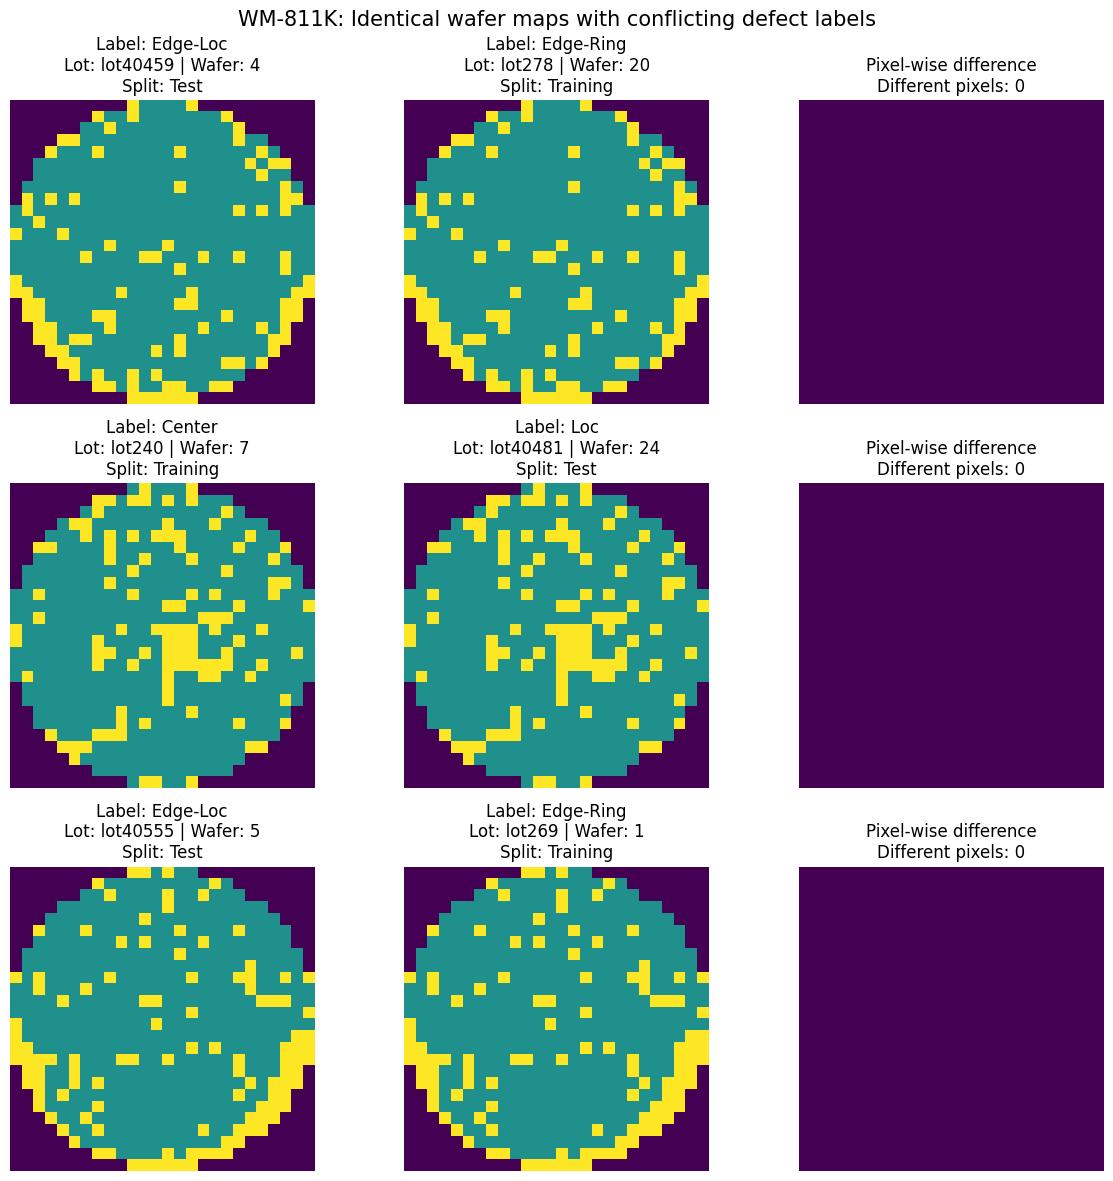

In [ ]:
# ============================================================
# EXTRA INSPECTION CELL — Visualize conflicting-label maps
# ============================================================
#
# Cell 5 found 3 cases where the EXACT SAME wafer map has
# two different defect labels.
#
# This cell displays:
#
#   Column 1: first labeled copy
#   Column 2: second labeled copy
#   Column 3: pixel-by-pixel difference
#
# If the exact-map hashing worked correctly, the difference
# image should contain ONLY zeros.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# ------------------------------------------------------------
# 1. Extract the six rows belonging to the 3 conflicting
#    exact-map clusters.
# ------------------------------------------------------------

conflict_rows = (
    defects[
        defects["exact_map_hash"].isin(
            conflicting_label_hashes
        )
    ]
    .copy()
    .sort_values(
        ["exact_map_hash", "label"]
    )
)


# ------------------------------------------------------------
# 2. Show their metadata first.
#
# This makes it easy to see:
#   - label
#   - lot
#   - wafer index
#   - Training/Test assignment
# ------------------------------------------------------------

display(
    conflict_rows[
        [
            "orig_index",
            "lotName",
            "waferIndex",
            "label",
            "provided_split",
            "height",
            "width",
            "failed_dies",
            "failure_fraction",
            "exact_map_hash"
        ]
    ]
)


# ------------------------------------------------------------
# 3. Get the 3 conflicting exact-map hashes.
# ------------------------------------------------------------

conflict_hashes = sorted(
    conflict_rows["exact_map_hash"].unique()
)

print("Number of conflicting map clusters:", len(conflict_hashes))

assert len(conflict_hashes) == 3


# ------------------------------------------------------------
# 4. Create one row of plots per conflicting map.
#
# We use vmin=0 and vmax=2 so the values have the same visual
# meaning in every subplot:
#
#   0 = background
#   1 = working die
#   2 = failed die
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=len(conflict_hashes),
    ncols=3,
    figsize=(12, 4 * len(conflict_hashes))
)


for row_number, exact_hash in enumerate(conflict_hashes):

    group = (
        conflict_rows[
            conflict_rows["exact_map_hash"] == exact_hash
        ]
        .reset_index(drop=True)
    )

    # Cell 5 told us each conflicting cluster contains 2 rows.
    assert len(group) == 2


    # --------------------------------------------------------
    # Get the two supposedly identical wafer arrays.
    # --------------------------------------------------------

    wafer_a = np.asarray(
        group.iloc[0]["waferMap"]
    )

    wafer_b = np.asarray(
        group.iloc[1]["waferMap"]
    )


    # --------------------------------------------------------
    # Verify mathematically that they really are identical.
    # --------------------------------------------------------

    identical = np.array_equal(
        wafer_a,
        wafer_b
    )

    assert identical


    # Pixel-wise absolute difference.
    difference = np.abs(
        wafer_a.astype(np.int16)
        -
        wafer_b.astype(np.int16)
    )


    # --------------------------------------------------------
    # Plot first copy.
    # --------------------------------------------------------

    ax = axes[row_number, 0]

    ax.imshow(
        wafer_a,
        cmap="viridis",
        vmin=0,
        vmax=2,
        interpolation="nearest"
    )

    ax.set_title(
        f"Label: {group.iloc[0]['label']}\n"
        f"Lot: {group.iloc[0]['lotName']} | "
        f"Wafer: {int(group.iloc[0]['waferIndex'])}\n"
        f"Split: {group.iloc[0]['provided_split']}"
    )

    ax.axis("off")


    # --------------------------------------------------------
    # Plot second copy.
    # --------------------------------------------------------

    ax = axes[row_number, 1]

    ax.imshow(
        wafer_b,
        cmap="viridis",
        vmin=0,
        vmax=2,
        interpolation="nearest"
    )

    ax.set_title(
        f"Label: {group.iloc[1]['label']}\n"
        f"Lot: {group.iloc[1]['lotName']} | "
        f"Wafer: {int(group.iloc[1]['waferIndex'])}\n"
        f"Split: {group.iloc[1]['provided_split']}"
    )

    ax.axis("off")


    # --------------------------------------------------------
    # Plot the difference.
    #
    # An entirely blank/uniform image means difference = 0
    # everywhere.
    # --------------------------------------------------------

    ax = axes[row_number, 2]

    ax.imshow(
        difference,
        cmap="viridis",
        vmin=0,
        vmax=2,
        interpolation="nearest"
    )

    ax.set_title(
        "Pixel-wise difference\n"
        f"Different pixels: {np.count_nonzero(difference)}"
    )

    ax.axis("off")


    # --------------------------------------------------------
    # Print an additional numerical confirmation.
    # --------------------------------------------------------

    print(
        f"Cluster {row_number + 1}: "
        f"{group.iloc[0]['label']} vs "
        f"{group.iloc[1]['label']} | "
        f"shape={wafer_a.shape} | "
        f"identical={identical} | "
        f"different_pixels={np.count_nonzero(difference)}"
    )


plt.suptitle(
    "WM-811K: Identical wafer maps with conflicting defect labels",
    fontsize=15
)

plt.tight_layout()

plt.show()

Total defect wafers: 25,519
Conflicting exact-map clusters: 3

CONFLICTING EXACT-MAP ROWS


,orig_index,lotName,waferIndex,label,provided_split,dieSize,height,width,active_dies,failed_dies,failure_fraction,layout_hash,exact_map_hash,strict_group
17253,642913,lot40459,4.0,Edge-Loc,Test,533.0,26,26,533,103,0.193246,ea5cfadb37e212be37f0f4db8323827a,365a5bc46eae24e600643fdc61544614,G02380
203,6917,lot278,20.0,Edge-Ring,Training,533.0,26,26,533,103,0.193246,ea5cfadb37e212be37f0f4db8323827a,365a5bc46eae24e600643fdc61544614,G02380
181,5954,lot240,7.0,Center,Training,533.0,26,26,533,107,0.200750,ea5cfadb37e212be37f0f4db8323827a,55822646b23db21b8cc46fa3f5b30dc3,G02015
17288,643483,lot40481,24.0,Loc,Test,533.0,26,26,533,107,0.200750,ea5cfadb37e212be37f0f4db8323827a,55822646b23db21b8cc46fa3f5b30dc3,G02015
17390,645298,lot40555,5.0,Edge-Loc,Test,533.0,26,26,533,113,0.212008,ea5cfadb37e212be37f0f4db8323827a,7400ec8fdaff805db5d69f3a983d3224,G02332
196,6673,lot269,1.0,Edge-Ring,Training,533.0,26,26,533,113,0.212008,ea5cfadb37e212be37f0f4db8323827a,7400ec8fdaff805db5d69f3a983d3224,G02332



PIXEL-BY-PIXEL VERIFICATION


,exact_map_hash,n_rows,labels,lots,all_arrays_identical
0,365a5bc46eae24e600643fdc61544614,2,Edge-Loc | Edge-Ring,lot278 | lot40459,True
1,55822646b23db21b8cc46fa3f5b30dc3,2,Center | Loc,lot240 | lot40481,True
2,7400ec8fdaff805db5d69f3a983d3224,2,Edge-Loc | Edge-Ring,lot269 | lot40555,True



PASS: all conflicting-map pairs are genuinely pixel-for-pixel identical.



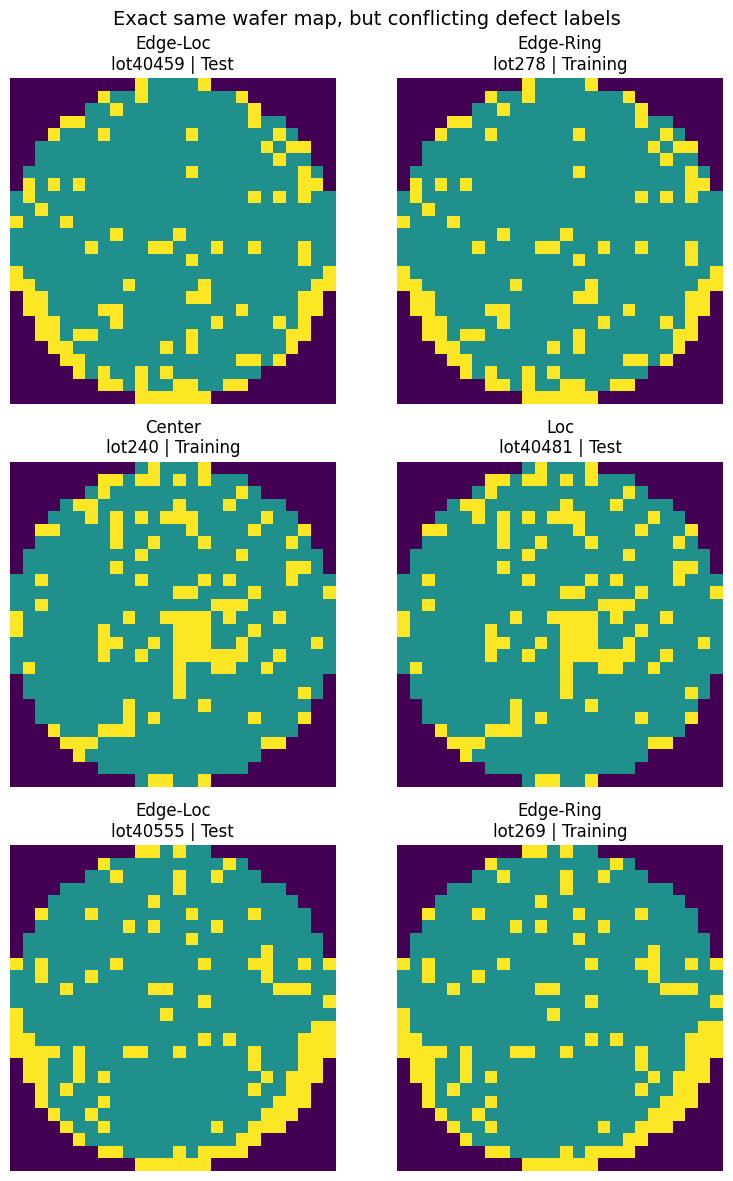

WHERE DO THE CONFLICTING MAPS OCCUR?


,n_rows,labels,provided_splits,n_lots
exact_map_hash,,,,
365a5bc46eae24e600643fdc61544614,2,Edge-Loc | Edge-Ring,Test | Training,2
55822646b23db21b8cc46fa3f5b30dc3,2,Center | Loc,Test | Training,2
7400ec8fdaff805db5d69f3a983d3224,2,Edge-Loc | Edge-Ring,Test | Training,2



defects_all: 25,519 wafers

PRIMARY COHORT
Original defect wafers: 25,519
Excluded ambiguous rows: 6
Primary clean wafers: 25,513
Percentage retained: 99.97649%

PASS: no exact wafer map in defects_clean has more than one label.

CLASS COUNTS BEFORE AND AFTER EXCLUSION


,before,excluded,after
label,,,
Center,4294,1,4293
Donut,555,0,555
Edge-Loc,5189,2,5187
Edge-Ring,9680,2,9678
Loc,3593,1,3592
Near-full,149,0,149
Random,866,0,866
Scratch,1193,0,1193



GROUP COUNTS IN PRIMARY COHORT
Unique lots: 8,045
Unique strict groups: 7,952

Every remaining exact map belongs to one strict group: PASS
Every remaining production lot belongs to one strict group: PASS

CELL 6 COMPLETE
original_defect_wafers                       : 25519
conflicting_exact_map_clusters               : 3
excluded_ambiguous_rows                      : 6
primary_clean_wafers                         : 25513
percent_original_rows_retained               : 99.97648810690075
primary_clean_unique_lots                    : 8045
primary_clean_strict_groups                  : 7952

Primary modeling dataset is now: defects_clean
Full defect dataset is preserved as: defects_all

No train/validation/test split has been created yet.
No wafer has been resized, shuffled, augmented, or used for model training.


In [ ]:
# Cell 6
# ============================================================
# CELL 6 — Inspect conflicting labels and define primary cohort
# ============================================================
#
# Cell 5 found something unusual:
#
# The EXACT SAME waferMap occurs with different defect labels
# in 3 clusters (6 rows total).
#
# Examples:
#
#   Edge-Loc  vs Edge-Ring
#   Center    vs Loc
#
# A classifier that receives only waferMap cannot possibly
# predict both labels correctly for identical inputs.
#
# So before creating train/test splits we will:
#
#   1. inspect these six rows;
#   2. verify programmatically that each pair really is
#      pixel-for-pixel identical;
#   3. visualize the conflicting pairs;
#   4. preserve the complete 25,519-wafer dataset;
#   5. create a primary "clean" cohort excluding only these
#      ambiguous exact-map clusters;
#   6. save a permanent record of the exclusions.
#
#
# IMPORTANT:
#
# We are NOT claiming the labels are "wrong".
#
# They may represent:
#   - genuine human disagreement,
#   - ambiguity between defect categories,
#   - annotation error,
#   - or some metadata issue.
#
# We simply know that the waferMap input alone cannot distinguish
# two different labels when the input arrays are identical.
#
# ============================================================


import gc
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 0. Safety checks.
# ------------------------------------------------------------

required_variables = [
    "defects",
    "conflicting_label_hashes",
    "OUTPUT_DIR"
]

for variable_name in required_variables:

    if variable_name not in globals():
        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Cells 1-5 first."
        )


print("Total defect wafers:", f"{len(defects):,}")
print(
    "Conflicting exact-map clusters:",
    f"{len(conflicting_label_hashes):,}"
)
print()


# ------------------------------------------------------------
# 1. Extract ALL rows belonging to conflicting-map clusters.
# ------------------------------------------------------------

conflict_rows = (
    defects[
        defects["exact_map_hash"].isin(
            conflicting_label_hashes
        )
    ]
    .copy()
)


conflict_metadata_columns = [
    "orig_index",
    "lotName",
    "waferIndex",
    "label",
    "provided_split",
    "dieSize",
    "height",
    "width",
    "active_dies",
    "failed_dies",
    "failure_fraction",
    "layout_hash",
    "exact_map_hash",
    "strict_group"
]


print("=" * 70)
print("CONFLICTING EXACT-MAP ROWS")
print("=" * 70)

display(
    conflict_rows[
        conflict_metadata_columns
    ].sort_values(
        [
            "exact_map_hash",
            "label"
        ]
    )
)

print()


# ------------------------------------------------------------
# 2. Verify that the maps really are identical.
#
# For each conflicting hash, compare every wafer array with
# the first wafer in that cluster.
#
# We should obtain:
#
#       all_arrays_identical = True
#
# for every cluster.
# ------------------------------------------------------------

verification_rows = []


for exact_hash, group in conflict_rows.groupby(
    "exact_map_hash"
):

    arrays = [
        np.asarray(x)
        for x in group["waferMap"]
    ]

    reference = arrays[0]

    all_identical = all(
        np.array_equal(
            reference,
            other
        )
        for other in arrays[1:]
    )


    verification_rows.append(
        {
            "exact_map_hash": exact_hash,
            "n_rows": len(group),

            "labels":
                " | ".join(
                    sorted(
                        group["label"].unique()
                    )
                ),

            "lots":
                " | ".join(
                    sorted(
                        group["lotName"].unique()
                    )
                ),

            "all_arrays_identical":
                all_identical
        }
    )


conflict_verification = pd.DataFrame(
    verification_rows
)


print("=" * 70)
print("PIXEL-BY-PIXEL VERIFICATION")
print("=" * 70)

display(conflict_verification)

print()


assert conflict_verification[
    "all_arrays_identical"
].all(), (
    "Unexpected result: at least one hash group "
    "does not contain identical arrays."
)


print(
    "PASS: all conflicting-map pairs are genuinely "
    "pixel-for-pixel identical."
)

print()


# ------------------------------------------------------------
# 3. Visualize the conflicting clusters.
#
# Color meaning:
#
#   0 = background
#   1 = normal die
#   2 = failed die
#
# Each ROW in the figure is one conflicting exact-map cluster.
#
# Because the two input maps are identical, the images should
# look identical within each row even though their labels differ.
# ------------------------------------------------------------

conflict_hash_list = list(
    conflict_verification["exact_map_hash"]
)


n_clusters = len(conflict_hash_list)


fig, axes = plt.subplots(
    n_clusters,
    2,
    figsize=(8, 4 * n_clusters)
)


# If there is only one row, matplotlib returns a 1-D array.
# np.atleast_2d makes the indexing below work in either case.

axes = np.atleast_2d(axes)


for row_index, exact_hash in enumerate(
    conflict_hash_list
):

    group = (
        conflict_rows[
            conflict_rows["exact_map_hash"]
            == exact_hash
        ]
        .sort_values("label")
        .reset_index(drop=True)
    )


    for column_index in range(2):

        sample = group.iloc[column_index]

        wafer = np.asarray(
            sample["waferMap"]
        )


        ax = axes[
            row_index,
            column_index
        ]


        ax.imshow(
            wafer,
            interpolation="nearest"
        )


        ax.set_title(
            f"{sample['label']}\n"
            f"{sample['lotName']} | "
            f"{sample['provided_split']}"
        )


        ax.axis("off")


fig.suptitle(
    "Exact same wafer map, but conflicting defect labels",
    fontsize=14
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 4. Examine whether the conflicting pairs lie in Training,
#    Test, or cross the provided split.
# ------------------------------------------------------------

conflict_split_summary = (
    conflict_rows
    .groupby(
        "exact_map_hash",
        observed=True
    )
    .agg(

        n_rows=(
            "orig_index",
            "size"
        ),

        labels=(
            "label",
            lambda x:
                " | ".join(
                    sorted(
                        set(x)
                    )
                )
        ),

        provided_splits=(
            "provided_split",
            lambda x:
                " | ".join(
                    sorted(
                        set(x)
                    )
                )
        ),

        n_lots=(
            "lotName",
            "nunique"
        )
    )
)


print("=" * 70)
print("WHERE DO THE CONFLICTING MAPS OCCUR?")
print("=" * 70)

display(conflict_split_summary)

print()


# ------------------------------------------------------------
# 5. Preserve the COMPLETE defect dataset.
#
# We give it a new name so that our later analysis makes the
# distinction explicit.
# ------------------------------------------------------------

defects_all = defects


print(
    "defects_all:",
    f"{len(defects_all):,}",
    "wafers"
)


# ------------------------------------------------------------
# 6. Define the PRIMARY clean cohort.
#
# Primary rule:
#
# Exclude every row belonging to an exact-map cluster that
# contains more than one defect label.
#
# We exclude the ENTIRE ambiguous cluster rather than choosing
# one of the labels ourselves.
#
# This is important:
#
# We do NOT decide that Edge-Loc is correct and Edge-Ring is
# wrong, for example.
#
# We simply say:
#
#   "The input map is identical but the target is ambiguous,
#    therefore this cluster is excluded from the primary
#    classification analysis."
# ------------------------------------------------------------

ambiguous_exact_map_mask = (
    defects_all["exact_map_hash"]
    .isin(
        conflicting_label_hashes
    )
)


defects_clean = (
    defects_all[
        ~ambiguous_exact_map_mask
    ]
    .copy()
    .reset_index(drop=True)
)


print()
print("=" * 70)
print("PRIMARY COHORT")
print("=" * 70)

print(
    "Original defect wafers:",
    f"{len(defects_all):,}"
)

print(
    "Excluded ambiguous rows:",
    f"{ambiguous_exact_map_mask.sum():,}"
)

print(
    "Primary clean wafers:",
    f"{len(defects_clean):,}"
)

print(
    "Percentage retained:",
    f"{100 * len(defects_clean) / len(defects_all):.5f}%"
)

print()


# Expected:
#
#       25,519 - 6 = 25,513

assert len(defects_clean) == 25_513


# ------------------------------------------------------------
# 7. Verify that NO exact map in defects_clean now has
#    conflicting labels.
# ------------------------------------------------------------

clean_label_counts = (
    defects_clean
    .groupby(
        "exact_map_hash",
        observed=True
    )["label"]
    .nunique()
)


assert clean_label_counts.max() == 1


print(
    "PASS: no exact wafer map in defects_clean "
    "has more than one label."
)

print()


# ------------------------------------------------------------
# 8. Check class counts before and after exclusion.
#
# Because only six rows are removed, class counts should change
# only slightly.
# ------------------------------------------------------------

before_counts = (
    defects_all["label"]
    .value_counts()
    .reindex(
        DEFECT_CLASSES
    )
)


after_counts = (
    defects_clean["label"]
    .value_counts()
    .reindex(
        DEFECT_CLASSES
    )
)


class_exclusion_summary = pd.DataFrame(
    {
        "before": before_counts,
        "excluded":
            before_counts - after_counts,
        "after": after_counts
    }
)


print("=" * 70)
print("CLASS COUNTS BEFORE AND AFTER EXCLUSION")
print("=" * 70)

display(class_exclusion_summary)

print()


# ------------------------------------------------------------
# 9. Check how many lots and strict groups remain.
#
# We KEEP the strict_group assignments created in Cell 5.
#
# This is conservative:
#
# If two lots were linked because of one ambiguous duplicate,
# we do not suddenly separate those lots merely because the
# ambiguous rows were excluded.
#
# That prevents our grouping policy from changing after seeing
# labels.
# ------------------------------------------------------------

print("=" * 70)
print("GROUP COUNTS IN PRIMARY COHORT")
print("=" * 70)

print(
    "Unique lots:",
    f"{defects_clean['lotName'].nunique():,}"
)

print(
    "Unique strict groups:",
    f"{defects_clean['strict_group'].nunique():,}"
)

print()


# ------------------------------------------------------------
# 10. Verify exact duplicates remain confined to one
#     strict_group.
# ------------------------------------------------------------

clean_exact_group_check = (
    defects_clean
    .groupby(
        "exact_map_hash",
        observed=True
    )["strict_group"]
    .nunique()
)


clean_lot_group_check = (
    defects_clean
    .groupby(
        "lotName",
        observed=True
    )["strict_group"]
    .nunique()
)


assert clean_exact_group_check.max() == 1
assert clean_lot_group_check.max() == 1


print(
    "Every remaining exact map belongs to one strict group: PASS"
)

print(
    "Every remaining production lot belongs to one strict group: PASS"
)

print()


# ------------------------------------------------------------
# 11. Save a permanent exclusion record.
#
# This is very important for reproducibility.
# ------------------------------------------------------------

excluded_rows = (
    defects_all[
        ambiguous_exact_map_mask
    ][
        conflict_metadata_columns
    ]
    .copy()
    .sort_values(
        [
            "exact_map_hash",
            "label"
        ]
    )
)


excluded_rows.to_csv(
    OUTPUT_DIR /
    "primary_cohort_excluded_ambiguous_exact_maps.csv",
    index=False
)


conflict_verification.to_csv(
    OUTPUT_DIR /
    "conflicting_exact_map_verification.csv",
    index=False
)


class_exclusion_summary.to_csv(
    OUTPUT_DIR /
    "primary_cohort_class_counts.csv"
)


# ------------------------------------------------------------
# 12. Save primary-cohort metadata.
#
# Again, waferMap arrays themselves are NOT written to CSV.
# ------------------------------------------------------------

defects_clean[
    [
        "orig_index",
        "lotName",
        "waferIndex",
        "label",
        "provided_split",
        "dieSize",
        "height",
        "width",
        "native_shape",
        "active_dies",
        "failed_dies",
        "failure_fraction",
        "layout_hash",
        "exact_map_hash",
        "strict_group"
    ]
].to_csv(
    OUTPUT_DIR /
    "primary_clean_defect_cohort_metadata.csv",
    index=False
)


# ------------------------------------------------------------
# 13. Compact Cell 6 summary.
# ------------------------------------------------------------

cell6_summary = {

    "original_defect_wafers":
        int(
            len(defects_all)
        ),

    "conflicting_exact_map_clusters":
        int(
            len(conflicting_label_hashes)
        ),

    "excluded_ambiguous_rows":
        int(
            ambiguous_exact_map_mask.sum()
        ),

    "primary_clean_wafers":
        int(
            len(defects_clean)
        ),

    "percent_original_rows_retained":
        float(
            100 *
            len(defects_clean) /
            len(defects_all)
        ),

    "primary_clean_unique_lots":
        int(
            defects_clean[
                "lotName"
            ].nunique()
        ),

    "primary_clean_strict_groups":
        int(
            defects_clean[
                "strict_group"
            ].nunique()
        )
}


with open(
    OUTPUT_DIR /
    "cell6_primary_cohort_summary.json",
    "w"
) as f:

    json.dump(
        cell6_summary,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 14. Memory cleanup.
# ------------------------------------------------------------

gc.collect()


# ------------------------------------------------------------
# 15. Final summary.
# ------------------------------------------------------------

print("=" * 70)
print("CELL 6 COMPLETE")
print("=" * 70)

for key, value in cell6_summary.items():

    print(
        f"{key:45s}: {value}"
    )


print()
print(
    "Primary modeling dataset is now: defects_clean"
)

print(
    "Full defect dataset is preserved as: defects_all"
)

print()
print(
    "No train/validation/test split has been created yet."
)

print(
    "No wafer has been resized, shuffled, augmented, "
    "or used for model training."
)

In [ ]:
# ============================================================
# CELL 7 — Can our strict groups support grouped CV?
# ============================================================
#
# We now have our primary research cohort:
#
#       defects_clean = 25,513 wafers
#
# Every wafer belongs to a "strict_group".
#
# A strict group keeps together:
#
#   1. all wafers from the same production lot, AND
#   2. lots connected by exact duplicate wafer maps.
#
#
# Before training any model, we must answer:
#
#   Can these groups be divided into useful cross-validation
#   folds while keeping all eight classes reasonably represented?
#
#
# We will compare:
#
#       3-fold StratifiedGroupKFold
#       5-fold StratifiedGroupKFold
#
#
# IMPORTANT:
#
# This cell is a FEASIBILITY AUDIT.
#
# We are NOT yet declaring either one to be the final protocol.
# We will inspect the results first.
#
#
# A good fold design should have:
#
#   - zero strict-group overlap
#   - zero lot overlap
#   - zero exact-map overlap
#   - all 8 classes in every fold
#   - reasonable class balance
#   - enough Near-full examples/groups in every fold
#
#
# Native wafer layouts ARE allowed to repeat across folds here.
#
# Why?
#
# Our primary grouping rule protects against:
#
#   production-lot leakage
#   exact-map duplicate leakage
#
# Layout generalization is a DIFFERENT question that we may
# investigate separately.
#
# Therefore we measure layout overlap rather than silently
# forcing layouts apart.
# ============================================================


import json

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold


# ------------------------------------------------------------
# 0. Safety checks.
# ------------------------------------------------------------

required_variables = [
    "defects_clean",
    "DEFECT_CLASSES",
    "OUTPUT_DIR",
    "SEED"
]

for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run the earlier cells first."
        )


assert len(defects_clean) == 25_513


print(
    "Primary clean wafers :",
    f"{len(defects_clean):,}"
)

print(
    "Production lots      :",
    f"{defects_clean['lotName'].nunique():,}"
)

print(
    "Strict groups        :",
    f"{defects_clean['strict_group'].nunique():,}"
)

print()


# ------------------------------------------------------------
# 1. Convert our class names to fixed integer IDs.
#
# We explicitly define the order rather than letting pandas
# decide alphabetically.
# ------------------------------------------------------------

CLASS_TO_ID = {
    label: class_id
    for class_id, label in enumerate(DEFECT_CLASSES)
}

ID_TO_CLASS = {
    class_id: label
    for label, class_id in CLASS_TO_ID.items()
}


defects_clean["class_id"] = (
    defects_clean["label"]
    .map(CLASS_TO_ID)
    .astype(np.int16)
)


assert defects_clean["class_id"].notna().all()

assert set(
    defects_clean["label"].unique()
) == set(
    DEFECT_CLASSES
)


# ------------------------------------------------------------
# 2. First ask a simpler question:
#
# How many INDEPENDENT strict groups contain each class?
#
#
# Imagine Near-full had 149 wafers but all 149 came from only
# 2 strict groups.
#
# Then 5-fold grouped CV would be impossible for Near-full,
# even though the raw sample count looked large enough.
#
# So group support matters more than raw wafer count.
# ------------------------------------------------------------

class_group_support = (
    defects_clean
    .groupby(
        "label",
        observed=True
    )
    .agg(

        wafers=(
            "orig_index",
            "size"
        ),

        production_lots=(
            "lotName",
            "nunique"
        ),

        strict_groups=(
            "strict_group",
            "nunique"
        ),

        native_layouts=(
            "layout_hash",
            "nunique"
        )
    )
    .reindex(
        DEFECT_CLASSES
    )
)


print("=" * 75)
print("CLASS SUPPORT BY INDEPENDENT STRICT GROUP")
print("=" * 75)

display(class_group_support)

print()


# ------------------------------------------------------------
# 3. Check the composition of strict groups themselves.
#
# A strict group can contain multiple labels.
#
# Why?
#
# A production lot may itself contain several defect classes.
#
# That is NOT an error.
#
# StratifiedGroupKFold must work around this while keeping
# every strict group intact.
# ------------------------------------------------------------

strict_group_class_table = pd.crosstab(
    defects_clean["strict_group"],
    defects_clean["label"]
).reindex(
    columns=DEFECT_CLASSES,
    fill_value=0
)


strict_group_n_classes = (
    (strict_group_class_table > 0)
    .sum(axis=1)
)


strict_group_sizes = (
    strict_group_class_table
    .sum(axis=1)
)


print("=" * 75)
print("STRICT-GROUP COMPOSITION")
print("=" * 75)

print(
    "Strict groups containing exactly one defect class:",
    f"{(strict_group_n_classes == 1).sum():,}"
)

print(
    "Strict groups containing multiple defect classes:",
    f"{(strict_group_n_classes > 1).sum():,}"
)

print()

print("Number of defect classes represented in each strict group:")

display(
    strict_group_n_classes
    .value_counts()
    .sort_index()
    .rename("number_of_strict_groups")
    .to_frame()
)

print()


# ------------------------------------------------------------
# 4. Prepare arrays for grouped cross-validation.
#
# We use POSITIONAL indices for sklearn.
# ------------------------------------------------------------

y = defects_clean[
    "class_id"
].to_numpy()


groups = defects_clean[
    "strict_group"
].astype(str).to_numpy()


all_positions = np.arange(
    len(defects_clean)
)


# sklearn requires an X argument even though the splitter
# does not actually use image values.
#
# So we supply one tiny dummy column.

X_dummy = np.zeros(
    (len(defects_clean), 1),
    dtype=np.uint8
)


# ------------------------------------------------------------
# 5. Overall class proportions.
#
# We will compare each fold against these values.
# ------------------------------------------------------------

overall_class_counts = (
    defects_clean["label"]
    .value_counts()
    .reindex(
        DEFECT_CLASSES
    )
)


overall_class_proportions = (
    overall_class_counts
    /
    len(defects_clean)
)


print("=" * 75)
print("OVERALL CLASS DISTRIBUTION")
print("=" * 75)

overall_distribution_table = pd.DataFrame(
    {
        "wafers":
            overall_class_counts,

        "proportion":
            overall_class_proportions,

        "percent":
            100 *
            overall_class_proportions
    }
)


display(overall_distribution_table)

print()


# ------------------------------------------------------------
# 6. Function to evaluate one candidate grouped-CV design.
# ------------------------------------------------------------

def audit_grouped_cv(
    n_splits,
    random_state=SEED
):

    splitter = StratifiedGroupKFold(

        n_splits=n_splits,

        shuffle=True,

        random_state=random_state
    )


    fold_summary_rows = []

    class_rows = []

    assignment_rows = []


    # --------------------------------------------------------
    # Generate all folds.
    # --------------------------------------------------------

    folds = list(
        splitter.split(
            X_dummy,
            y,
            groups
        )
    )


    # --------------------------------------------------------
    # Every sample must appear in exactly one TEST fold.
    # --------------------------------------------------------

    all_test_positions = np.concatenate(
        [
            test_positions
            for _, test_positions in folds
        ]
    )


    assert len(all_test_positions) == len(
        defects_clean
    )


    assert len(
        np.unique(
            all_test_positions
        )
    ) == len(
        defects_clean
    )


    # --------------------------------------------------------
    # Examine each fold.
    # --------------------------------------------------------

    for fold_number, (
        train_positions,
        test_positions
    ) in enumerate(
        folds,
        start=1
    ):

        train_df = defects_clean.iloc[
            train_positions
        ]

        test_df = defects_clean.iloc[
            test_positions
        ]


        # ----------------------------------------------------
        # Leakage checks.
        # ----------------------------------------------------

        train_strict_groups = set(
            train_df["strict_group"]
        )

        test_strict_groups = set(
            test_df["strict_group"]
        )


        strict_overlap = (
            train_strict_groups
            .intersection(
                test_strict_groups
            )
        )


        train_lots = set(
            train_df["lotName"]
        )

        test_lots = set(
            test_df["lotName"]
        )


        lot_overlap = (
            train_lots
            .intersection(
                test_lots
            )
        )


        train_exact_maps = set(
            train_df["exact_map_hash"]
        )

        test_exact_maps = set(
            test_df["exact_map_hash"]
        )


        exact_map_overlap = (
            train_exact_maps
            .intersection(
                test_exact_maps
            )
        )


        # ----------------------------------------------------
        # Layout overlap is measured, NOT prohibited.
        # ----------------------------------------------------

        train_layouts = set(
            train_df["layout_hash"]
        )


        test_seen_layout = (
            test_df["layout_hash"]
            .isin(
                train_layouts
            )
        )


        layout_overlap_unique = len(
            set(
                test_df["layout_hash"]
            ).intersection(
                train_layouts
            )
        )


        # ----------------------------------------------------
        # Sanity assertions.
        # ----------------------------------------------------

        assert len(strict_overlap) == 0

        assert len(lot_overlap) == 0

        assert len(exact_map_overlap) == 0


        # ----------------------------------------------------
        # Test-fold class counts.
        # ----------------------------------------------------

        test_class_counts = (
            test_df["label"]
            .value_counts()
            .reindex(
                DEFECT_CLASSES,
                fill_value=0
            )
        )


        test_class_proportions = (
            test_class_counts
            /
            len(test_df)
        )


        # Number of strict groups contributing each class.

        test_groups_per_class = (
            test_df
            .groupby(
                "label",
                observed=True
            )["strict_group"]
            .nunique()
            .reindex(
                DEFECT_CLASSES,
                fill_value=0
            )
        )


        # ----------------------------------------------------
        # Record class-level information.
        #
        # "percent_of_class_in_fold" answers:
        #
        # Of ALL Center wafers, what percentage ended up
        # in this fold?
        #
        # For 5 folds the ideal is roughly 20%.
        #
        # For 3 folds the ideal is roughly 33.3%.
        # ----------------------------------------------------

        for label in DEFECT_CLASSES:

            n_class_samples = int(
                test_class_counts[label]
            )


            n_class_groups = int(
                test_groups_per_class[label]
            )


            percent_of_class_in_fold = (
                100
                *
                n_class_samples
                /
                overall_class_counts[label]
            )


            fold_class_percent = (
                100
                *
                test_class_proportions[label]
            )


            overall_class_percent = (
                100
                *
                overall_class_proportions[label]
            )


            class_rows.append(
                {
                    "n_splits":
                        n_splits,

                    "fold":
                        fold_number,

                    "label":
                        label,

                    "test_wafers":
                        n_class_samples,

                    "test_strict_groups":
                        n_class_groups,

                    "percent_of_entire_class_in_fold":
                        percent_of_class_in_fold,

                    "class_percent_within_fold":
                        fold_class_percent,

                    "class_percent_overall":
                        overall_class_percent,

                    "absolute_composition_error_pp":
                        abs(
                            fold_class_percent
                            -
                            overall_class_percent
                        )
                }
            )


        # ----------------------------------------------------
        # Fold-level summary.
        # ----------------------------------------------------

        fold_size_percent = (
            100
            *
            len(test_df)
            /
            len(defects_clean)
        )


        expected_fold_percent = (
            100 /
            n_splits
        )


        fold_summary_rows.append(
            {
                "n_splits":
                    n_splits,

                "fold":
                    fold_number,

                "train_wafers":
                    len(train_df),

                "test_wafers":
                    len(test_df),

                "test_percent":
                    fold_size_percent,

                "expected_test_percent":
                    expected_fold_percent,

                "absolute_size_error_pp":
                    abs(
                        fold_size_percent
                        -
                        expected_fold_percent
                    ),

                "train_strict_groups":
                    len(
                        train_strict_groups
                    ),

                "test_strict_groups":
                    len(
                        test_strict_groups
                    ),

                "train_lots":
                    len(
                        train_lots
                    ),

                "test_lots":
                    len(
                        test_lots
                    ),

                "strict_group_overlap":
                    len(
                        strict_overlap
                    ),

                "lot_overlap":
                    len(
                        lot_overlap
                    ),

                "exact_map_overlap":
                    len(
                        exact_map_overlap
                    ),

                "native_layouts_shared_with_train":
                    layout_overlap_unique,

                "test_wafers_with_layout_seen_in_train":
                    int(
                        test_seen_layout.sum()
                    ),

                "percent_test_wafers_with_layout_seen_in_train":
                    float(
                        100
                        *
                        test_seen_layout.mean()
                    ),

                "classes_present":
                    int(
                        (test_class_counts > 0)
                        .sum()
                    ),

                "minimum_class_wafers":
                    int(
                        test_class_counts.min()
                    ),

                "minimum_class_strict_groups":
                    int(
                        test_groups_per_class.min()
                    )
            }
        )


        # ----------------------------------------------------
        # Save TEST-fold assignment for reproducibility.
        #
        # Each sample occurs exactly once here for each
        # candidate n_splits value.
        # ----------------------------------------------------

        assignment_part = test_df[
            [
                "orig_index",
                "lotName",
                "waferIndex",
                "label",
                "class_id",
                "strict_group",
                "layout_hash",
                "exact_map_hash"
            ]
        ].copy()


        assignment_part.insert(
            0,
            "fold",
            fold_number
        )


        assignment_part.insert(
            0,
            "n_splits",
            n_splits
        )


        assignment_rows.append(
            assignment_part
        )


    # --------------------------------------------------------
    # Convert results to DataFrames.
    # --------------------------------------------------------

    fold_summary_df = pd.DataFrame(
        fold_summary_rows
    )


    class_df = pd.DataFrame(
        class_rows
    )


    assignment_df = pd.concat(
        assignment_rows,
        ignore_index=True
    )


    # --------------------------------------------------------
    # Final candidate sanity checks.
    # --------------------------------------------------------

    assert (
        fold_summary_df[
            "strict_group_overlap"
        ] == 0
    ).all()


    assert (
        fold_summary_df[
            "lot_overlap"
        ] == 0
    ).all()


    assert (
        fold_summary_df[
            "exact_map_overlap"
        ] == 0
    ).all()


    return (
        fold_summary_df,
        class_df,
        assignment_df
    )


# ------------------------------------------------------------
# 7. Evaluate BOTH candidate designs.
#
# We deliberately use the SAME fixed random seed for both.
#
# We are not trying many random seeds until we find a split
# that looks especially attractive.
# ------------------------------------------------------------

candidate_split_counts = [
    3,
    5
]


candidate_fold_tables = []

candidate_class_tables = []

candidate_assignment_tables = []


for n_splits in candidate_split_counts:

    (
        fold_table,
        class_table,
        assignment_table

    ) = audit_grouped_cv(
        n_splits=n_splits,
        random_state=SEED
    )


    candidate_fold_tables.append(
        fold_table
    )

    candidate_class_tables.append(
        class_table
    )

    candidate_assignment_tables.append(
        assignment_table
    )


fold_audit = pd.concat(
    candidate_fold_tables,
    ignore_index=True
)


class_fold_audit = pd.concat(
    candidate_class_tables,
    ignore_index=True
)


candidate_fold_assignments = pd.concat(
    candidate_assignment_tables,
    ignore_index=True
)


# ------------------------------------------------------------
# 8. Display the 3-fold candidate.
# ------------------------------------------------------------

print("=" * 75)
print("CANDIDATE: 3-FOLD STRICT GROUPED CV")
print("=" * 75)

display(
    fold_audit[
        fold_audit["n_splits"] == 3
    ]
)

print()


three_fold_class_counts = (
    class_fold_audit[
        class_fold_audit["n_splits"] == 3
    ]
    .pivot(
        index="label",
        columns="fold",
        values="test_wafers"
    )
    .reindex(
        DEFECT_CLASSES
    )
)


print("Test-wafer counts by class:")

display(
    three_fold_class_counts
)

print()


three_fold_group_counts = (
    class_fold_audit[
        class_fold_audit["n_splits"] == 3
    ]
    .pivot(
        index="label",
        columns="fold",
        values="test_strict_groups"
    )
    .reindex(
        DEFECT_CLASSES
    )
)


print("Independent strict groups per class in each fold:")

display(
    three_fold_group_counts
)

print()


# ------------------------------------------------------------
# 9. Display the 5-fold candidate.
# ------------------------------------------------------------

print("=" * 75)
print("CANDIDATE: 5-FOLD STRICT GROUPED CV")
print("=" * 75)

display(
    fold_audit[
        fold_audit["n_splits"] == 5
    ]
)

print()


five_fold_class_counts = (
    class_fold_audit[
        class_fold_audit["n_splits"] == 5
    ]
    .pivot(
        index="label",
        columns="fold",
        values="test_wafers"
    )
    .reindex(
        DEFECT_CLASSES
    )
)


print("Test-wafer counts by class:")

display(
    five_fold_class_counts
)

print()


five_fold_group_counts = (
    class_fold_audit[
        class_fold_audit["n_splits"] == 5
    ]
    .pivot(
        index="label",
        columns="fold",
        values="test_strict_groups"
    )
    .reindex(
        DEFECT_CLASSES
    )
)


print("Independent strict groups per class in each fold:")

display(
    five_fold_group_counts
)

print()


# ------------------------------------------------------------
# 10. Build one compact comparison between 3-fold and 5-fold.
# ------------------------------------------------------------

candidate_comparison_rows = []


for n_splits in candidate_split_counts:

    folds_part = fold_audit[
        fold_audit["n_splits"] == n_splits
    ]


    classes_part = class_fold_audit[
        class_fold_audit["n_splits"] == n_splits
    ]


    ideal_class_fraction = (
        100 /
        n_splits
    )


    class_allocation_error = abs(
        classes_part[
            "percent_of_entire_class_in_fold"
        ]
        -
        ideal_class_fraction
    )


    candidate_comparison_rows.append(
        {
            "n_splits":
                n_splits,

            "all_folds_have_all_8_classes":
                bool(
                    (
                        folds_part[
                            "classes_present"
                        ]
                        == len(
                            DEFECT_CLASSES
                        )
                    ).all()
                ),

            "minimum_class_wafers_in_any_fold":
                int(
                    folds_part[
                        "minimum_class_wafers"
                    ].min()
                ),

            "minimum_class_strict_groups_in_any_fold":
                int(
                    folds_part[
                        "minimum_class_strict_groups"
                    ].min()
                ),

            "smallest_fold_wafers":
                int(
                    folds_part[
                        "test_wafers"
                    ].min()
                ),

            "largest_fold_wafers":
                int(
                    folds_part[
                        "test_wafers"
                    ].max()
                ),

            "max_fold_size_error_pp":
                float(
                    folds_part[
                        "absolute_size_error_pp"
                    ].max()
                ),

            "mean_absolute_class_composition_error_pp":
                float(
                    classes_part[
                        "absolute_composition_error_pp"
                    ].mean()
                ),

            "max_absolute_class_composition_error_pp":
                float(
                    classes_part[
                        "absolute_composition_error_pp"
                    ].max()
                ),

            "max_class_allocation_error_from_ideal_pp":
                float(
                    class_allocation_error.max()
                ),

            "mean_percent_test_layout_seen_in_train":
                float(
                    folds_part[
                        "percent_test_wafers_with_layout_seen_in_train"
                    ].mean()
                ),

            "minimum_percent_test_layout_seen_in_train":
                float(
                    folds_part[
                        "percent_test_wafers_with_layout_seen_in_train"
                    ].min()
                ),

            "maximum_percent_test_layout_seen_in_train":
                float(
                    folds_part[
                        "percent_test_wafers_with_layout_seen_in_train"
                    ].max()
                )
        }
    )


candidate_comparison = pd.DataFrame(
    candidate_comparison_rows
)


print("=" * 75)
print("3-FOLD vs 5-FOLD FEASIBILITY COMPARISON")
print("=" * 75)

display(candidate_comparison)

print()


# ------------------------------------------------------------
# 11. Specifically inspect Near-full.
#
# This is our rarest class, so it is the first place where an
# overly ambitious fold count would usually fail.
# ------------------------------------------------------------

near_full_audit = (
    class_fold_audit[
        class_fold_audit["label"]
        == "Near-full"
    ]
    .copy()
)


print("=" * 75)
print("NEAR-FULL FOLD SUPPORT")
print("=" * 75)

display(
    near_full_audit[
        [
            "n_splits",
            "fold",
            "test_wafers",
            "test_strict_groups",
            "percent_of_entire_class_in_fold"
        ]
    ]
)

print()


# ------------------------------------------------------------
# 12. Verify that each candidate assignment covers every
#     primary-cohort wafer exactly once.
# ------------------------------------------------------------

for n_splits in candidate_split_counts:

    candidate = (
        candidate_fold_assignments[
            candidate_fold_assignments[
                "n_splits"
            ] == n_splits
        ]
    )


    assert len(candidate) == len(
        defects_clean
    )


    assert candidate[
        "orig_index"
    ].nunique() == len(
        defects_clean
    )


print(
    "PASS: each wafer appears in exactly one test fold "
    "for each candidate CV design."
)

print()


# ------------------------------------------------------------
# 13. Save all candidate diagnostics.
#
# These are NOT yet the frozen final experimental splits.
# ------------------------------------------------------------

class_group_support.to_csv(
    OUTPUT_DIR /
    "cell7_class_group_support.csv"
)


fold_audit.to_csv(
    OUTPUT_DIR /
    "cell7_candidate_fold_audit.csv",
    index=False
)


class_fold_audit.to_csv(
    OUTPUT_DIR /
    "cell7_candidate_class_fold_audit.csv",
    index=False
)


candidate_comparison.to_csv(
    OUTPUT_DIR /
    "cell7_3fold_vs_5fold_comparison.csv",
    index=False
)


candidate_fold_assignments.to_csv(
    OUTPUT_DIR /
    "cell7_candidate_fold_assignments.csv",
    index=False
)


# ------------------------------------------------------------
# 14. Save compact JSON information.
# ------------------------------------------------------------

cell7_summary = {

    "primary_clean_wafers":
        int(
            len(defects_clean)
        ),

    "production_lots":
        int(
            defects_clean[
                "lotName"
            ].nunique()
        ),

    "strict_groups":
        int(
            defects_clean[
                "strict_group"
            ].nunique()
        ),

    "rarest_class":
        str(
            overall_class_counts.idxmin()
        ),

    "rarest_class_wafers":
        int(
            overall_class_counts.min()
        ),

    "rarest_class_strict_groups":
        int(
            class_group_support.loc[
                overall_class_counts.idxmin(),
                "strict_groups"
            ]
        ),

    "candidate_folds_tested":
        candidate_split_counts,

    "split_seed":
        int(SEED)
}


with open(
    OUTPUT_DIR /
    "cell7_fold_feasibility_summary.json",
    "w"
) as f:

    json.dump(
        cell7_summary,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 15. Final summary.
# ------------------------------------------------------------

print("=" * 75)
print("CELL 7 COMPLETE")
print("=" * 75)

for key, value in cell7_summary.items():

    print(
        f"{key:35s}: {value}"
    )


print()
print(
    "No model has been trained."
)

print(
    "Neither the 3-fold nor 5-fold design has been "
    "declared final yet."
)

print()
print(
    "Next step: choose the grouped evaluation design "
    "based on feasibility, then freeze it before modeling."
)

Primary clean wafers : 25,513
Production lots      : 8,045
Strict groups        : 7,952

CLASS SUPPORT BY INDEPENDENT STRICT GROUP


,wafers,production_lots,strict_groups,native_layouts
label,,,,
Center,4293,1648,1642,168
Donut,555,233,233,106
Edge-Loc,5187,3209,3175,423
Edge-Ring,9678,1073,1067,230
Loc,3592,2472,2449,404
Near-full,149,137,129,33
Random,866,449,433,101
Scratch,1193,1059,1046,213



STRICT-GROUP COMPOSITION
Strict groups containing exactly one defect class: 6,198
Strict groups containing multiple defect classes: 1,754

Number of defect classes represented in each strict group:


,number_of_strict_groups
1,6198
2,1354
3,340
4,54
5,4
6,2



OVERALL CLASS DISTRIBUTION


,wafers,proportion,percent
label,,,
Center,4293,0.168267,16.826716
Donut,555,0.021754,2.175362
Edge-Loc,5187,0.203308,20.330812
Edge-Ring,9678,0.379336,37.933602
Loc,3592,0.140791,14.079097
Near-full,149,0.005840,0.584016
Random,866,0.033943,3.394348
Scratch,1193,0.046760,4.676048


... (13 outputs left out)

,n_splits,all_folds_have_all_8_classes,minimum_class_wafers_in_any_fold,minimum_class_strict_groups_in_any_fold,smallest_fold_wafers,largest_fold_wafers,max_fold_size_error_pp,mean_absolute_class_composition_error_pp,max_absolute_class_composition_error_pp,max_class_allocation_error_from_ideal_pp,mean_percent_test_layout_seen_in_train,minimum_percent_test_layout_seen_in_train,maximum_percent_test_layout_seen_in_train
0,3,True,44,37,8344,8630,0.628438,0.356055,1.104743,8.044650,95.239932,94.727694,95.702073
1,5,True,24,21,4851,5369,1.044174,0.642193,4.532406,5.750577,95.207666,94.640280,96.115765



NEAR-FULL FOLD SUPPORT


,n_splits,fold,test_wafers,test_strict_groups,percent_of_entire_class_in_fold
5,3,1,48,43,32.214765
13,3,2,57,49,38.255034
21,3,3,44,37,29.530201
29,5,1,29,24,19.463087
37,5,2,34,29,22.818792
45,5,3,30,29,20.134228
53,5,4,24,21,16.107383
61,5,5,32,26,21.476510



PASS: each wafer appears in exactly one test fold for each candidate CV design.

CELL 7 COMPLETE
primary_clean_wafers               : 25513
production_lots                    : 8045
strict_groups                      : 7952
rarest_class                       : Near-full
rarest_class_wafers                : 149
rarest_class_strict_groups         : 129
candidate_folds_tested             : [3, 5]
split_seed                         : 42

No model has been trained.
Neither the 3-fold nor 5-fold design has been declared final yet.

Next step: choose the grouped evaluation design based on feasibility, then freeze it before modeling.


In [ ]:
# ============================================================
# CELL 8 — Freeze the PRIMARY 3-fold outer evaluation
# ============================================================
#
# In Cell 7 we compared 3-fold and 5-fold grouped CV BEFORE
# training any machine-learning model.
#
# We selected 3-fold CV because it gave:
#
#   - all 8 classes in every fold
#   - stronger support for the rare Near-full class
#   - more independent strict groups per class
#   - better class balance between folds
#   - fewer total model-training runs
#
#
# PRIMARY OUTER EVALUATION:
#
#   Splitter : StratifiedGroupKFold
#   Folds    : 3
#   Seed     : 42
#   Group    : strict_group
#
#
# strict_group ensures that:
#
#   1. no production lot crosses train/test;
#   2. no exact duplicate wafer map crosses train/test;
#   3. lots connected through exact duplicates stay together.
#
#
# IMPORTANT:
#
# Native wafer layouts ARE allowed to occur in multiple folds.
#
# That is deliberate.
#
# Our primary experiment tests generalization to:
#
#       unseen production groups
#
# not necessarily:
#
#       unseen wafer layouts
#
# Layout-disjoint evaluation would be a separate experiment.
#
#
# FREEZE RULE:
#
# After this cell succeeds, we will NOT regenerate the outer
# folds because one model performs better or worse.
#
# Every model and every representation must use the exact same
# outer-fold manifest created here.
#
# ============================================================


import hashlib
import json

import numpy as np
import pandas as pd
import sklearn


# ------------------------------------------------------------
# 0. Safety checks.
# ------------------------------------------------------------

required_variables = [
    "defects_clean",
    "candidate_fold_assignments",
    "DEFECT_CLASSES",
    "OUTPUT_DIR",
    "SEED"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Cells 1-7 first."
        )


assert len(defects_clean) == 25_513


# ------------------------------------------------------------
# 1. Freeze the basic protocol constants.
# ------------------------------------------------------------

PRIMARY_OUTER_FOLDS = 3

PRIMARY_OUTER_SEED = SEED


assert PRIMARY_OUTER_SEED == 42


print("=" * 75)
print("PRIMARY OUTER EVALUATION PROTOCOL")
print("=" * 75)

print("Dataset                 : defects_clean")
print("Wafers                  :", f"{len(defects_clean):,}")
print("Classes                 :", len(DEFECT_CLASSES))
print("Outer folds             :", PRIMARY_OUTER_FOLDS)
print("Splitter seed           :", PRIMARY_OUTER_SEED)
print("Grouping variable       : strict_group")

print()


# ------------------------------------------------------------
# 2. IMPORTANT:
#
# We do NOT run StratifiedGroupKFold again here.
#
# Cell 7 already generated and audited the candidate folds.
#
# We select the exact 3-fold assignment that was already
# evaluated there.
#
# This avoids accidentally generating a slightly different
# split later.
# ------------------------------------------------------------

candidate_3fold = (
    candidate_fold_assignments[
        candidate_fold_assignments["n_splits"]
        == PRIMARY_OUTER_FOLDS
    ]
    .copy()
)


print(
    "Rows in saved 3-fold candidate:",
    f"{len(candidate_3fold):,}"
)


assert len(candidate_3fold) == len(
    defects_clean
)


assert candidate_3fold[
    "orig_index"
].nunique() == len(
    defects_clean
)


assert set(
    candidate_3fold["fold"].unique()
) == {
    1,
    2,
    3
}


print(
    "PASS: every clean wafer appears exactly once "
    "in the 3-fold assignment."
)

print()


# ------------------------------------------------------------
# 3. Map the frozen outer-fold assignment back onto
#    defects_clean.
#
# orig_index is the row number from the ORIGINAL 811,457-row
# WM-811K DataFrame.
#
# We use orig_index rather than the current DataFrame position
# because it gives every wafer a stable identifier.
# ------------------------------------------------------------

orig_index_to_outer_fold = (
    candidate_3fold
    .set_index("orig_index")["fold"]
)


defects_clean["outer_fold"] = (
    defects_clean["orig_index"]
    .map(
        orig_index_to_outer_fold
    )
)


assert defects_clean[
    "outer_fold"
].notna().all()


defects_clean["outer_fold"] = (
    defects_clean["outer_fold"]
    .astype(np.int8)
)


print(
    "Outer-fold assignments added to defects_clean."
)

print()


# ------------------------------------------------------------
# 4. Make a permanent manifest.
#
# This contains enough information to identify every wafer and
# reproduce its experimental role WITHOUT storing the large
# waferMap arrays themselves.
# ------------------------------------------------------------

FROZEN_MANIFEST_COLUMNS = [

    "orig_index",

    "lotName",

    "waferIndex",

    "label",

    "class_id",

    "provided_split",

    "strict_group",

    "layout_hash",

    "exact_map_hash",

    "outer_fold"
]


frozen_manifest = (
    defects_clean[
        FROZEN_MANIFEST_COLUMNS
    ]
    .copy()
    .sort_values(
        "orig_index"
    )
    .reset_index(
        drop=True
    )
)


# Convert identifiers that should be integer-valued into
# explicit integer types before hashing.

frozen_manifest["orig_index"] = (
    frozen_manifest["orig_index"]
    .astype(np.int64)
)


frozen_manifest["waferIndex"] = (
    frozen_manifest["waferIndex"]
    .astype(np.int16)
)


frozen_manifest["class_id"] = (
    frozen_manifest["class_id"]
    .astype(np.int16)
)


frozen_manifest["outer_fold"] = (
    frozen_manifest["outer_fold"]
    .astype(np.int8)
)


assert len(frozen_manifest) == 25_513

assert frozen_manifest[
    "orig_index"
].nunique() == 25_513


# ------------------------------------------------------------
# 5. Create a CANONICAL text representation.
#
# Why?
#
# A SHA-256 hash only works reproducibly if the exact byte
# representation is defined.
#
# Therefore we:
#
#   - sort by orig_index
#   - use fixed columns
#   - use tab separators
#   - use Unix newline characters
#
# The resulting SHA-256 becomes the fingerprint of our frozen
# experimental split.
# ------------------------------------------------------------

canonical_manifest_text = (
    frozen_manifest[
        FROZEN_MANIFEST_COLUMNS
    ]
    .to_csv(
        index=False,
        sep="\t",
        lineterminator="\n"
    )
)


FROZEN_MANIFEST_SHA256 = (
    hashlib
    .sha256(
        canonical_manifest_text.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


print("=" * 75)
print("FROZEN MANIFEST FINGERPRINT")
print("=" * 75)

print(
    "SHA-256:",
    FROZEN_MANIFEST_SHA256
)

print()


# ------------------------------------------------------------
# 6. Save the frozen manifest.
#
# We save:
#
#   CSV  -> convenient for humans / spreadsheets
#   TSV  -> canonical byte representation used for hashing
#
# ------------------------------------------------------------

manifest_csv_path = (
    OUTPUT_DIR /
    "FROZEN_primary_outer_3fold_manifest.csv"
)


manifest_tsv_path = (
    OUTPUT_DIR /
    "FROZEN_primary_outer_3fold_manifest.tsv"
)


manifest_hash_path = (
    OUTPUT_DIR /
    "FROZEN_primary_outer_3fold_manifest_sha256.txt"
)


# ------------------------------------------------------------
# If this cell is rerun and the canonical file already exists,
# do NOT silently overwrite a different frozen split.
#
# We verify that the existing frozen file has the SAME hash.
# ------------------------------------------------------------

if manifest_tsv_path.exists():

    existing_bytes = (
        manifest_tsv_path.read_bytes()
    )

    existing_hash = (
        hashlib
        .sha256(
            existing_bytes
        )
        .hexdigest()
    )


    if existing_hash != FROZEN_MANIFEST_SHA256:

        raise RuntimeError(
            "\nA DIFFERENT frozen manifest already exists!\n\n"
            f"Existing hash : {existing_hash}\n"
            f"Current hash  : {FROZEN_MANIFEST_SHA256}\n\n"
            "STOP here rather than overwriting the "
            "experimental split."
        )


    print(
        "Existing frozen manifest found."
    )

    print(
        "Its SHA-256 matches the current assignment: PASS"
    )


else:

    # Save exact canonical bytes.

    manifest_tsv_path.write_text(
        canonical_manifest_text,
        encoding="utf-8"
    )


    frozen_manifest.to_csv(
        manifest_csv_path,
        index=False
    )


    manifest_hash_path.write_text(
        FROZEN_MANIFEST_SHA256 + "\n",
        encoding="utf-8"
    )


    print(
        "Frozen manifest written for the first time."
    )


print()


# ------------------------------------------------------------
# 7. FINAL leakage audit of the frozen folds.
#
# Every fold takes a turn as the outer TEST fold.
#
# The other two folds form the training+validation pool.
#
# At this stage we verify:
#
#   strict_group overlap = 0
#   lot overlap          = 0
#   exact-map overlap    = 0
#
# Layout overlap is measured but allowed.
# ------------------------------------------------------------

outer_fold_summary_rows = []


for fold_number in [
    1,
    2,
    3
]:

    test_df = defects_clean[
        defects_clean["outer_fold"]
        == fold_number
    ]


    trainval_df = defects_clean[
        defects_clean["outer_fold"]
        != fold_number
    ]


    # --------------------------------------------------------
    # Strict-group overlap
    # --------------------------------------------------------

    strict_overlap = set(
        trainval_df["strict_group"]
    ).intersection(
        test_df["strict_group"]
    )


    # --------------------------------------------------------
    # Production-lot overlap
    # --------------------------------------------------------

    lot_overlap = set(
        trainval_df["lotName"]
    ).intersection(
        test_df["lotName"]
    )


    # --------------------------------------------------------
    # Exact-map overlap
    # --------------------------------------------------------

    exact_map_overlap = set(
        trainval_df["exact_map_hash"]
    ).intersection(
        test_df["exact_map_hash"]
    )


    # --------------------------------------------------------
    # Native-layout overlap
    #
    # This is ALLOWED but recorded.
    # --------------------------------------------------------

    trainval_layouts = set(
        trainval_df["layout_hash"]
    )


    test_layout_seen = (
        test_df["layout_hash"]
        .isin(
            trainval_layouts
        )
    )


    # --------------------------------------------------------
    # Class support.
    # --------------------------------------------------------

    test_class_counts = (
        test_df["label"]
        .value_counts()
        .reindex(
            DEFECT_CLASSES,
            fill_value=0
        )
    )


    # --------------------------------------------------------
    # Mandatory leakage assertions.
    # --------------------------------------------------------

    assert len(
        strict_overlap
    ) == 0


    assert len(
        lot_overlap
    ) == 0


    assert len(
        exact_map_overlap
    ) == 0


    assert (
        test_class_counts > 0
    ).all()


    outer_fold_summary_rows.append(
        {

            "outer_fold":
                fold_number,

            "trainval_wafers":
                int(
                    len(trainval_df)
                ),

            "test_wafers":
                int(
                    len(test_df)
                ),

            "trainval_strict_groups":
                int(
                    trainval_df[
                        "strict_group"
                    ].nunique()
                ),

            "test_strict_groups":
                int(
                    test_df[
                        "strict_group"
                    ].nunique()
                ),

            "trainval_lots":
                int(
                    trainval_df[
                        "lotName"
                    ].nunique()
                ),

            "test_lots":
                int(
                    test_df[
                        "lotName"
                    ].nunique()
                ),

            "strict_group_overlap":
                int(
                    len(
                        strict_overlap
                    )
                ),

            "lot_overlap":
                int(
                    len(
                        lot_overlap
                    )
                ),

            "exact_map_overlap":
                int(
                    len(
                        exact_map_overlap
                    )
                ),

            "test_wafers_with_layout_seen_in_trainval":
                int(
                    test_layout_seen.sum()
                ),

            "percent_test_wafers_with_layout_seen_in_trainval":
                float(
                    100 *
                    test_layout_seen.mean()
                ),

            "classes_present":
                int(
                    (
                        test_class_counts > 0
                    ).sum()
                ),

            "minimum_class_wafers":
                int(
                    test_class_counts.min()
                )
        }
    )


outer_fold_summary = pd.DataFrame(
    outer_fold_summary_rows
)


print("=" * 75)
print("FINAL FROZEN OUTER-FOLD AUDIT")
print("=" * 75)

display(
    outer_fold_summary
)

print()


# ------------------------------------------------------------
# 8. Show the class counts in every frozen outer fold.
# ------------------------------------------------------------

frozen_class_counts = (
    pd.crosstab(
        defects_clean["label"],
        defects_clean["outer_fold"]
    )
    .reindex(
        DEFECT_CLASSES,
        fill_value=0
    )
)


frozen_class_counts.columns = [
    f"Fold_{column}"
    for column in frozen_class_counts.columns
]


print("=" * 75)
print("CLASS COUNTS IN EACH FROZEN OUTER TEST FOLD")
print("=" * 75)

display(
    frozen_class_counts
)

print()


# ------------------------------------------------------------
# 9. Show how many INDEPENDENT strict groups support each
#    class in each outer fold.
# ------------------------------------------------------------

frozen_class_group_counts = (
    defects_clean
    .groupby(
        [
            "label",
            "outer_fold"
        ],
        observed=True
    )[
        "strict_group"
    ]
    .nunique()
    .unstack(
        fill_value=0
    )
    .reindex(
        DEFECT_CLASSES,
        fill_value=0
    )
)


frozen_class_group_counts.columns = [
    f"Fold_{column}"
    for column in frozen_class_group_counts.columns
]


print("=" * 75)
print("STRICT-GROUP SUPPORT BY CLASS AND OUTER FOLD")
print("=" * 75)

display(
    frozen_class_group_counts
)

print()


# ------------------------------------------------------------
# 10. Global integrity checks.
#
# Instead of checking one fold at a time, verify directly that:
#
#   every strict group occupies exactly one outer fold;
#   every lot occupies exactly one outer fold;
#   every exact map occupies exactly one outer fold.
# ------------------------------------------------------------

strict_group_fold_counts = (
    defects_clean
    .groupby(
        "strict_group",
        observed=True
    )[
        "outer_fold"
    ]
    .nunique()
)


lot_fold_counts = (
    defects_clean
    .groupby(
        "lotName",
        observed=True
    )[
        "outer_fold"
    ]
    .nunique()
)


exact_map_fold_counts = (
    defects_clean
    .groupby(
        "exact_map_hash",
        observed=True
    )[
        "outer_fold"
    ]
    .nunique()
)


assert strict_group_fold_counts.max() == 1

assert lot_fold_counts.max() == 1

assert exact_map_fold_counts.max() == 1


print("=" * 75)
print("GLOBAL SPLIT INTEGRITY")
print("=" * 75)

print(
    "Every strict group occurs in exactly one outer fold : PASS"
)

print(
    "Every production lot occurs in exactly one outer fold: PASS"
)

print(
    "Every exact map occurs in exactly one outer fold     : PASS"
)

print()


# ------------------------------------------------------------
# 11. Record the complete frozen protocol.
#
# This JSON explains HOW and WHY the split was created.
#
# We also record the source-dataset SHA-256 from Cell 2 if it
# is still available.
# ------------------------------------------------------------

source_dataset_sha256 = globals().get(
    "dataset_sha256",
    None
)


# If the Python variable is gone but Cell 2's JSON exists,
# recover the hash from that file.

dataset_info_path = (
    OUTPUT_DIR /
    "dataset_source_info.json"
)


if (
    source_dataset_sha256 is None
    and dataset_info_path.exists()
):

    with open(
        dataset_info_path,
        "r"
    ) as f:

        source_dataset_sha256 = (
            json.load(f)
            .get(
                "sha256"
            )
        )


frozen_protocol = {

    "project":
        "WM811K Spatial Information Audit",

    "primary_task":
        "8-class defect-type classification",

    "primary_cohort":
        "defects_clean",

    "primary_cohort_wafers":
        int(
            len(
                defects_clean
            )
        ),

    "classes":
        DEFECT_CLASSES,

    "ambiguous_exact_map_policy":
        (
            "Exclude all rows from exact-map clusters "
            "that contain conflicting defect labels."
        ),

    "outer_splitter":
        "StratifiedGroupKFold",

    "outer_n_splits":
        int(
            PRIMARY_OUTER_FOLDS
        ),

    "outer_shuffle":
        True,

    "outer_random_seed":
        int(
            PRIMARY_OUTER_SEED
        ),

    "grouping_variable":
        "strict_group",

    "strict_group_definition":
        (
            "Connected components formed by production lotName "
            "and cross-lot exact native wafer-map duplicates."
        ),

    "layout_overlap_policy":
        (
            "Native layouts may cross outer folds; "
            "layout overlap is measured but not prohibited."
        ),

    "selection_basis":
        (
            "3-fold design chosen before any model training "
            "using only fold feasibility, class balance, "
            "independent-group support, rare-class support, "
            "and computational practicality."
        ),

    "outer_test_policy":
        (
            "Each outer fold is held out once as test data. "
            "Outer test data must never be used for model "
            "selection, early stopping, hyperparameter tuning, "
            "representation tuning, or class-weight estimation."
        ),

    "validation_policy":
        (
            "Validation sets have NOT yet been assigned. "
            "They must later be created only inside each "
            "outer train+validation portion and must remain "
            "strict-group-disjoint."
        ),

    "source_dataset_sha256":
        source_dataset_sha256,

    "frozen_manifest_sha256":
        FROZEN_MANIFEST_SHA256,

    "scikit_learn_version":
        sklearn.__version__
}


protocol_path = (
    OUTPUT_DIR /
    "FROZEN_primary_outer_3fold_protocol.json"
)


# ------------------------------------------------------------
# If the protocol file already exists, ensure it describes
# exactly the same frozen design.
# ------------------------------------------------------------

if protocol_path.exists():

    with open(
        protocol_path,
        "r"
    ) as f:

        existing_protocol = json.load(
            f
        )


    if existing_protocol != frozen_protocol:

        raise RuntimeError(
            "\nA frozen protocol file already exists, "
            "but it differs from the current protocol.\n"
            "STOP rather than silently replacing it."
        )


    print(
        "Existing protocol file matches current protocol: PASS"
    )


else:

    with open(
        protocol_path,
        "w"
    ) as f:

        json.dump(
            frozen_protocol,
            f,
            indent=2
        )


    print(
        "Frozen protocol JSON saved."
    )


print()


# ------------------------------------------------------------
# 12. Save supporting tables.
# ------------------------------------------------------------

outer_fold_summary.to_csv(
    OUTPUT_DIR /
    "FROZEN_outer_fold_summary.csv",
    index=False
)


frozen_class_counts.to_csv(
    OUTPUT_DIR /
    "FROZEN_outer_fold_class_counts.csv"
)


frozen_class_group_counts.to_csv(
    OUTPUT_DIR /
    "FROZEN_outer_fold_class_group_counts.csv"
)


# ------------------------------------------------------------
# 13. Create a convenient in-memory dictionary for later cells.
#
# IMPORTANT:
#
# These are POSITIONAL row indices within defects_clean.
#
# We still keep the saved orig_index manifest as the permanent
# source of truth.
# ------------------------------------------------------------

FROZEN_OUTER_SPLITS = {}


outer_fold_array = (
    defects_clean[
        "outer_fold"
    ]
    .to_numpy()
)


for fold_number in [
    1,
    2,
    3
]:

    test_positions = np.flatnonzero(
        outer_fold_array
        == fold_number
    )


    trainval_positions = np.flatnonzero(
        outer_fold_array
        != fold_number
    )


    FROZEN_OUTER_SPLITS[
        fold_number
    ] = {

        "trainval_positions":
            trainval_positions,

        "test_positions":
            test_positions
    }


# ------------------------------------------------------------
# 14. Final freeze summary.
# ------------------------------------------------------------

print("=" * 75)
print("CELL 8 COMPLETE — OUTER SPLITS ARE NOW FROZEN")
print("=" * 75)

print(
    "Primary cohort           :",
    f"{len(defects_clean):,}",
    "wafers"
)

print(
    "Outer folds              :",
    PRIMARY_OUTER_FOLDS
)

print(
    "Outer split seed         :",
    PRIMARY_OUTER_SEED
)

print(
    "Strict groups            :",
    f"{defects_clean['strict_group'].nunique():,}"
)

print(
    "Frozen manifest SHA-256  :",
    FROZEN_MANIFEST_SHA256
)

print()

print(
    "Manifest:"
)

print(
    manifest_csv_path
)

print()

print(
    "Protocol:"
)

print(
    protocol_path
)

print()

print(
    "FROM THIS POINT ON:"
)

print(
    "We will NOT regenerate the outer folds based on "
    "model performance."
)

print()

print(
    "The outer TEST fold must remain untouched until "
    "the corresponding model has been completely trained "
    "and selected using training + validation data only."
)

print()

print(
    "No model has been trained yet."
)

PRIMARY OUTER EVALUATION PROTOCOL
Dataset                 : defects_clean
Wafers                  : 25,513
Classes                 : 8
Outer folds             : 3
Splitter seed           : 42
Grouping variable       : strict_group

Rows in saved 3-fold candidate: 25,513
PASS: every clean wafer appears exactly once in the 3-fold assignment.

Outer-fold assignments added to defects_clean.

FROZEN MANIFEST FINGERPRINT
SHA-256: c9d3edae11a34473753539361b49456a2a6ec036f3e08dc8a50d21fa475e3f6e

Frozen manifest written for the first time.

FINAL FROZEN OUTER-FOLD AUDIT


,outer_fold,trainval_wafers,test_wafers,trainval_strict_groups,test_strict_groups,trainval_lots,test_lots,strict_group_overlap,lot_overlap,exact_map_overlap,test_wafers_with_layout_seen_in_trainval,percent_test_wafers_with_layout_seen_in_trainval,classes_present,minimum_class_wafers
0,1,17169,8344,5302,2650,5372,2673,0,0,0,7951,95.290029,8,48
1,2,16974,8539,5296,2656,5352,2693,0,0,0,8172,95.702073,8,57
2,3,16883,8630,5306,2646,5366,2679,0,0,0,8175,94.727694,8,44



CLASS COUNTS IN EACH FROZEN OUTER TEST FOLD


,Fold_1,Fold_2,Fold_3
label,,,
Center,1471,1377,1445
Donut,150,200,205
Edge-Loc,1692,1750,1745
Edge-Ring,3073,3266,3339
Loc,1149,1191,1252
Near-full,48,57,44
Random,331,316,219
Scratch,430,382,381



STRICT-GROUP SUPPORT BY CLASS AND OUTER FOLD


,Fold_1,Fold_2,Fold_3
label,,,
Center,553,568,521
Donut,70,82,81
Edge-Loc,1053,1074,1048
Edge-Ring,345,348,374
Loc,804,801,844
Near-full,43,49,37
Random,140,166,127
Scratch,377,326,343



GLOBAL SPLIT INTEGRITY
Every strict group occurs in exactly one outer fold : PASS
Every production lot occurs in exactly one outer fold: PASS
Every exact map occurs in exactly one outer fold     : PASS

Frozen protocol JSON saved.

CELL 8 COMPLETE — OUTER SPLITS ARE NOW FROZEN
Primary cohort           : 25,513 wafers
Outer folds              : 3
Outer split seed         : 42
Strict groups            : 7,952
Frozen manifest SHA-256  : c9d3edae11a34473753539361b49456a2a6ec036f3e08dc8a50d21fa475e3f6e

Manifest:
/content/wm811k_spatial_audit/outputs/FROZEN_primary_outer_3fold_manifest.csv

Protocol:
/content/wm811k_spatial_audit/outputs/FROZEN_primary_outer_3fold_protocol.json

FROM THIS POINT ON:
We will NOT regenerate the outer folds based on model performance.

The outer TEST fold must remain untouched until the corresponding model has been completely trained and selected using training + validation data only.

No model has been trained yet.


In [ ]:
# ============================================================
# CELL 9 — Freeze INNER train/validation splits
# ============================================================
#
# Cell 8 froze our OUTER 3-fold evaluation.
#
# For each outer fold:
#
#   - one outer fold is the untouched TEST set;
#   - the other two outer folds form the TRAIN+VALIDATION pool.
#
#
# We now divide ONLY that train+validation pool into:
#
#       training
#       validation
#
#
# The validation set will be used later for:
#
#   - early stopping
#   - selecting the best epoch
#   - model-selection decisions that we explicitly permit
#
#
# The OUTER TEST SET must not participate in any of this.
#
#
# ------------------------------------------------------------
# INNER SPLIT DESIGN
# ------------------------------------------------------------
#
# Within each outer train+validation pool we use:
#
#       StratifiedGroupKFold(n_splits=5)
#
# and take ONE of the five folds as validation.
#
# Therefore validation is approximately:
#
#       20% of the outer train+validation pool
#
# Since the outer train+validation pool is about 2/3 of all
# wafers, this corresponds to roughly:
#
#       13% of the complete dataset
#
#
# strict_group remains the grouping variable, so:
#
#   - lots cannot cross training/validation;
#   - exact duplicate maps cannot cross training/validation.
#
#
# IMPORTANT:
#
# The outer test fold is completely untouched.
#
# ============================================================


import hashlib
import json

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold


# ------------------------------------------------------------
# 0. Safety checks
# ------------------------------------------------------------

required_variables = [
    "defects_clean",
    "FROZEN_OUTER_SPLITS",
    "FROZEN_MANIFEST_SHA256",
    "DEFECT_CLASSES",
    "OUTPUT_DIR"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run Cells 1-8 first."
        )


assert len(defects_clean) == 25_513


# ------------------------------------------------------------
# 1. Freeze the inner-split settings.
#
# Five inner folds means one validation fold is about 20%
# of the outer train+validation pool.
#
# We use a different deterministic seed for each outer fold.
#
# These seeds are decided BEFORE model training.
# ------------------------------------------------------------

INNER_N_SPLITS = 5

INNER_SEEDS = {
    1: 1043,
    2: 1044,
    3: 1045
}


print("=" * 78)
print("INNER VALIDATION PROTOCOL")
print("=" * 78)

print("Inner splitter          : StratifiedGroupKFold")
print("Candidate inner folds   :", INNER_N_SPLITS)
print("Grouping variable       : strict_group")
print("Validation target       : ~20% of outer trainval")
print()

print("Inner seeds:")

for outer_fold, seed in INNER_SEEDS.items():

    print(
        f"  Outer fold {outer_fold}: {seed}"
    )

print()


# ------------------------------------------------------------
# 2. Function for creating ONE inner split.
#
# We generate the five possible grouped validation folds.
#
# We then select one using ONLY DATA-STRUCTURE information:
#
#   1. all eight classes must be present;
#   2. prefer the smallest worst class-composition error;
#   3. then prefer the validation size closest to 20%;
#   4. finally use candidate number as deterministic tie-break.
#
#
# NO model accuracy is used.
#
# This prevents us from choosing a validation set simply because
# it gives a model an attractive result.
# ------------------------------------------------------------

def create_inner_split(
    outer_fold,
    trainval_positions,
    test_positions,
    seed
):

    trainval_df = defects_clean.iloc[
        trainval_positions
    ]


    outer_test_df = defects_clean.iloc[
        test_positions
    ]


    y_inner = (
        trainval_df[
            "class_id"
        ]
        .to_numpy()
    )


    groups_inner = (
        trainval_df[
            "strict_group"
        ]
        .astype(str)
        .to_numpy()
    )


    X_dummy_inner = np.zeros(
        (
            len(trainval_df),
            1
        ),
        dtype=np.uint8
    )


    splitter = StratifiedGroupKFold(

        n_splits=INNER_N_SPLITS,

        shuffle=True,

        random_state=seed
    )


    candidates = []


    # Overall class distribution inside this
    # outer train+validation pool.

    overall_counts = (
        trainval_df[
            "label"
        ]
        .value_counts()
        .reindex(
            DEFECT_CLASSES,
            fill_value=0
        )
    )


    overall_proportions = (
        overall_counts
        /
        len(trainval_df)
    )


    # --------------------------------------------------------
    # Examine all five possible validation folds.
    # --------------------------------------------------------

    for candidate_number, (
        inner_train_local,
        inner_val_local

    ) in enumerate(
        splitter.split(
            X_dummy_inner,
            y_inner,
            groups_inner
        ),
        start=1
    ):


        # These are LOCAL positions inside trainval_df.

        train_df = trainval_df.iloc[
            inner_train_local
        ]


        val_df = trainval_df.iloc[
            inner_val_local
        ]


        # ----------------------------------------------------
        # Class balance.
        # ----------------------------------------------------

        val_counts = (
            val_df[
                "label"
            ]
            .value_counts()
            .reindex(
                DEFECT_CLASSES,
                fill_value=0
            )
        )


        val_proportions = (
            val_counts
            /
            len(val_df)
        )


        composition_errors_pp = (

            100
            *
            abs(
                val_proportions
                -
                overall_proportions
            )
        )


        # ----------------------------------------------------
        # Independent strict-group support by class.
        # ----------------------------------------------------

        groups_per_class = (
            val_df
            .groupby(
                "label",
                observed=True
            )[
                "strict_group"
            ]
            .nunique()
            .reindex(
                DEFECT_CLASSES,
                fill_value=0
            )
        )


        # ----------------------------------------------------
        # Group-overlap checks.
        # ----------------------------------------------------

        train_groups = set(
            train_df[
                "strict_group"
            ]
        )


        val_groups = set(
            val_df[
                "strict_group"
            ]
        )


        outer_test_groups = set(
            outer_test_df[
                "strict_group"
            ]
        )


        train_val_group_overlap = (
            train_groups
            .intersection(
                val_groups
            )
        )


        train_test_group_overlap = (
            train_groups
            .intersection(
                outer_test_groups
            )
        )


        val_test_group_overlap = (
            val_groups
            .intersection(
                outer_test_groups
            )
        )


        # ----------------------------------------------------
        # Lot-overlap checks.
        # ----------------------------------------------------

        train_lots = set(
            train_df[
                "lotName"
            ]
        )


        val_lots = set(
            val_df[
                "lotName"
            ]
        )


        outer_test_lots = set(
            outer_test_df[
                "lotName"
            ]
        )


        train_val_lot_overlap = (
            train_lots
            .intersection(
                val_lots
            )
        )


        train_test_lot_overlap = (
            train_lots
            .intersection(
                outer_test_lots
            )
        )


        val_test_lot_overlap = (
            val_lots
            .intersection(
                outer_test_lots
            )
        )


        # ----------------------------------------------------
        # Exact-map overlap checks.
        # ----------------------------------------------------

        train_maps = set(
            train_df[
                "exact_map_hash"
            ]
        )


        val_maps = set(
            val_df[
                "exact_map_hash"
            ]
        )


        outer_test_maps = set(
            outer_test_df[
                "exact_map_hash"
            ]
        )


        train_val_map_overlap = (
            train_maps
            .intersection(
                val_maps
            )
        )


        train_test_map_overlap = (
            train_maps
            .intersection(
                outer_test_maps
            )
        )


        val_test_map_overlap = (
            val_maps
            .intersection(
                outer_test_maps
            )
        )


        # ----------------------------------------------------
        # These MUST all be zero.
        # ----------------------------------------------------

        assert len(
            train_val_group_overlap
        ) == 0


        assert len(
            train_test_group_overlap
        ) == 0


        assert len(
            val_test_group_overlap
        ) == 0


        assert len(
            train_val_lot_overlap
        ) == 0


        assert len(
            train_test_lot_overlap
        ) == 0


        assert len(
            val_test_lot_overlap
        ) == 0


        assert len(
            train_val_map_overlap
        ) == 0


        assert len(
            train_test_map_overlap
        ) == 0


        assert len(
            val_test_map_overlap
        ) == 0


        # ----------------------------------------------------
        # Validation-size error.
        #
        # Ideal validation fraction inside trainval = 20%.
        # ----------------------------------------------------

        val_percent_of_trainval = (
            100
            *
            len(val_df)
            /
            len(trainval_df)
        )


        val_size_error_pp = abs(
            val_percent_of_trainval
            -
            20.0
        )


        # ----------------------------------------------------
        # Record candidate information.
        # ----------------------------------------------------

        candidates.append(
            {

                "outer_fold":
                    outer_fold,

                "inner_candidate":
                    candidate_number,

                "train_wafers":
                    int(
                        len(train_df)
                    ),

                "validation_wafers":
                    int(
                        len(val_df)
                    ),

                "outer_test_wafers":
                    int(
                        len(outer_test_df)
                    ),

                "validation_percent_of_trainval":
                    float(
                        val_percent_of_trainval
                    ),

                "validation_size_error_pp":
                    float(
                        val_size_error_pp
                    ),

                "classes_present":
                    int(
                        (
                            val_counts > 0
                        ).sum()
                    ),

                "minimum_validation_class_wafers":
                    int(
                        val_counts.min()
                    ),

                "minimum_validation_class_groups":
                    int(
                        groups_per_class.min()
                    ),

                "mean_class_composition_error_pp":
                    float(
                        composition_errors_pp.mean()
                    ),

                "max_class_composition_error_pp":
                    float(
                        composition_errors_pp.max()
                    ),

                "train_val_group_overlap":
                    0,

                "train_test_group_overlap":
                    0,

                "val_test_group_overlap":
                    0,

                "train_val_lot_overlap":
                    0,

                "train_test_lot_overlap":
                    0,

                "val_test_lot_overlap":
                    0,

                "train_val_exact_map_overlap":
                    0,

                "train_test_exact_map_overlap":
                    0,

                "val_test_exact_map_overlap":
                    0,

                "_inner_train_local":
                    inner_train_local,

                "_inner_val_local":
                    inner_val_local,

                "_val_counts":
                    val_counts,

                "_val_group_counts":
                    groups_per_class
            }
        )


    # --------------------------------------------------------
    # Only candidates containing ALL EIGHT classes qualify.
    # --------------------------------------------------------

    valid_candidates = [
        candidate
        for candidate in candidates

        if candidate[
            "classes_present"
        ] == len(
            DEFECT_CLASSES
        )
    ]


    if len(
        valid_candidates
    ) == 0:

        raise RuntimeError(
            f"Outer fold {outer_fold}: "
            "none of the inner candidates contains "
            "all eight classes."
        )


    # --------------------------------------------------------
    # Deterministic selection.
    #
    # PRIMARY criterion:
    #   smallest WORST class-composition error
    #
    # SECONDARY:
    #   validation size closest to 20%
    #
    # TIE-BREAK:
    #   smallest candidate number
    # --------------------------------------------------------

    selected = min(
        valid_candidates,

        key=lambda candidate: (

            candidate[
                "max_class_composition_error_pp"
            ],

            candidate[
                "validation_size_error_pp"
            ],

            candidate[
                "inner_candidate"
            ]
        )
    )


    # --------------------------------------------------------
    # Convert LOCAL trainval indices back to GLOBAL positional
    # indices within defects_clean.
    # --------------------------------------------------------

    selected_train_global = (
        np.asarray(
            trainval_positions
        )[
            selected[
                "_inner_train_local"
            ]
        ]
    )


    selected_val_global = (
        np.asarray(
            trainval_positions
        )[
            selected[
                "_inner_val_local"
            ]
        ]
    )


    selected_test_global = (
        np.asarray(
            test_positions
        )
    )


    return (
        candidates,
        selected,
        selected_train_global,
        selected_val_global,
        selected_test_global
    )


# ------------------------------------------------------------
# 3. Create the three inner splits.
# ------------------------------------------------------------

INNER_SPLITS = {}

all_candidate_rows = []

selected_rows = []

role_manifest_parts = []


for outer_fold in [
    1,
    2,
    3
]:

    print(
        "=" * 78
    )

    print(
        f"OUTER FOLD {outer_fold}"
    )

    print(
        "=" * 78
    )


    trainval_positions = (
        FROZEN_OUTER_SPLITS[
            outer_fold
        ][
            "trainval_positions"
        ]
    )


    test_positions = (
        FROZEN_OUTER_SPLITS[
            outer_fold
        ][
            "test_positions"
        ]
    )


    (
        candidates,
        selected,
        train_positions,
        val_positions,
        test_positions

    ) = create_inner_split(

        outer_fold=
            outer_fold,

        trainval_positions=
            trainval_positions,

        test_positions=
            test_positions,

        seed=
            INNER_SEEDS[
                outer_fold
            ]
    )


    # --------------------------------------------------------
    # Store public candidate information without private
    # temporary arrays.
    # --------------------------------------------------------

    for candidate in candidates:

        public_candidate = {
            key: value

            for key, value
            in candidate.items()

            if not key.startswith(
                "_"
            )
        }


        all_candidate_rows.append(
            public_candidate
        )


    # --------------------------------------------------------
    # Store selected split.
    # --------------------------------------------------------

    INNER_SPLITS[
        outer_fold
    ] = {

        "train_positions":
            train_positions,

        "val_positions":
            val_positions,

        "test_positions":
            test_positions
    }


    selected_public = {

        key: value

        for key, value
        in selected.items()

        if not key.startswith(
            "_"
        )
    }


    selected_public[
        "inner_seed"
    ] = INNER_SEEDS[
        outer_fold
    ]


    selected_rows.append(
        selected_public
    )


    print(
        "Selected inner candidate:",
        selected[
            "inner_candidate"
        ]
    )


    print(
        "Training wafers          :",
        f"{len(train_positions):,}"
    )


    print(
        "Validation wafers        :",
        f"{len(val_positions):,}"
    )


    print(
        "Outer test wafers        :",
        f"{len(test_positions):,}"
    )


    print(
        "Minimum validation class :",
        selected[
            "minimum_validation_class_wafers"
        ],
        "wafers"
    )


    print(
        "Minimum validation groups:",
        selected[
            "minimum_validation_class_groups"
        ]
    )


    print(
        "Worst class-balance error:",
        f"{selected['max_class_composition_error_pp']:.3f}",
        "percentage points"
    )


    print()


    # --------------------------------------------------------
    # Build manifest rows assigning each wafer one of:
    #
    #       train
    #       validation
    #       test
    #
    # for this particular outer fold.
    # --------------------------------------------------------

    role = np.full(
        len(defects_clean),
        "",
        dtype=object
    )


    role[
        train_positions
    ] = "train"


    role[
        val_positions
    ] = "validation"


    role[
        test_positions
    ] = "test"


    assert (
        role != ""
    ).all()


    role_part = defects_clean[
        [
            "orig_index",
            "lotName",
            "waferIndex",
            "label",
            "class_id",
            "strict_group",
            "layout_hash",
            "exact_map_hash",
            "outer_fold"
        ]
    ].copy()


    role_part.insert(
        0,
        "role",
        role
    )


    role_part.insert(
        0,
        "evaluation_outer_fold",
        outer_fold
    )


    role_manifest_parts.append(
        role_part
    )


# ------------------------------------------------------------
# 4. Candidate and selected-split tables.
# ------------------------------------------------------------

inner_candidate_audit = pd.DataFrame(
    all_candidate_rows
)


selected_inner_splits = pd.DataFrame(
    selected_rows
)


print("=" * 78)
print("SELECTED INNER SPLITS")
print("=" * 78)

display(
    selected_inner_splits
)

print()


# ------------------------------------------------------------
# 5. Full role manifest.
#
# There are 25,513 rows for EACH outer fold, because every
# wafer receives one role under every outer evaluation.
#
# Therefore:
#
#       25,513 × 3 = 76,539 rows
# ------------------------------------------------------------

frozen_role_manifest = pd.concat(
    role_manifest_parts,
    ignore_index=True
)


assert len(
    frozen_role_manifest
) == (
    3
    *
    len(
        defects_clean
    )
)


print(
    "Rows in full train/validation/test role manifest:",
    f"{len(frozen_role_manifest):,}"
)

print()


# ------------------------------------------------------------
# 6. Final leakage audit for every selected split.
# ------------------------------------------------------------

integrity_rows = []


for outer_fold in [
    1,
    2,
    3
]:

    split = INNER_SPLITS[
        outer_fold
    ]


    train_df = defects_clean.iloc[
        split[
            "train_positions"
        ]
    ]


    val_df = defects_clean.iloc[
        split[
            "val_positions"
        ]
    ]


    test_df = defects_clean.iloc[
        split[
            "test_positions"
        ]
    ]


    # --------------------------------------------------------
    # Helper function for overlap counts.
    # --------------------------------------------------------

    def overlap_count(
        frame_a,
        frame_b,
        column
    ):

        return len(
            set(
                frame_a[column]
            ).intersection(
                set(
                    frame_b[column]
                )
            )
        )


    row = {

        "outer_fold":
            outer_fold,

        "train_wafers":
            len(
                train_df
            ),

        "validation_wafers":
            len(
                val_df
            ),

        "test_wafers":
            len(
                test_df
            ),

        "train_validation_strict_group_overlap":
            overlap_count(
                train_df,
                val_df,
                "strict_group"
            ),

        "train_test_strict_group_overlap":
            overlap_count(
                train_df,
                test_df,
                "strict_group"
            ),

        "validation_test_strict_group_overlap":
            overlap_count(
                val_df,
                test_df,
                "strict_group"
            ),

        "train_validation_lot_overlap":
            overlap_count(
                train_df,
                val_df,
                "lotName"
            ),

        "train_test_lot_overlap":
            overlap_count(
                train_df,
                test_df,
                "lotName"
            ),

        "validation_test_lot_overlap":
            overlap_count(
                val_df,
                test_df,
                "lotName"
            ),

        "train_validation_exact_map_overlap":
            overlap_count(
                train_df,
                val_df,
                "exact_map_hash"
            ),

        "train_test_exact_map_overlap":
            overlap_count(
                train_df,
                test_df,
                "exact_map_hash"
            ),

        "validation_test_exact_map_overlap":
            overlap_count(
                val_df,
                test_df,
                "exact_map_hash"
            )
    }


    # Every overlap count must be zero.

    overlap_columns = [
        key
        for key in row

        if "overlap"
        in key
    ]


    assert all(
        row[column] == 0

        for column
        in overlap_columns
    )


    integrity_rows.append(
        row
    )


inner_integrity_audit = pd.DataFrame(
    integrity_rows
)


print("=" * 78)
print("FINAL TRAIN / VALIDATION / TEST INTEGRITY")
print("=" * 78)

display(
    inner_integrity_audit
)

print()


# ------------------------------------------------------------
# 7. Class counts for train / validation / test.
# ------------------------------------------------------------

class_role_rows = []


for outer_fold in [
    1,
    2,
    3
]:

    split = INNER_SPLITS[
        outer_fold
    ]


    for role_name, position_key in [

        (
            "train",
            "train_positions"
        ),

        (
            "validation",
            "val_positions"
        ),

        (
            "test",
            "test_positions"
        )
    ]:

        role_df = defects_clean.iloc[
            split[
                position_key
            ]
        ]


        counts = (
            role_df[
                "label"
            ]
            .value_counts()
            .reindex(
                DEFECT_CLASSES,
                fill_value=0
            )
        )


        groups_per_class = (
            role_df
            .groupby(
                "label",
                observed=True
            )[
                "strict_group"
            ]
            .nunique()
            .reindex(
                DEFECT_CLASSES,
                fill_value=0
            )
        )


        for label in DEFECT_CLASSES:

            class_role_rows.append(
                {

                    "outer_fold":
                        outer_fold,

                    "role":
                        role_name,

                    "label":
                        label,

                    "wafers":
                        int(
                            counts[
                                label
                            ]
                        ),

                    "strict_groups":
                        int(
                            groups_per_class[
                                label
                            ]
                        )
                }
            )


class_role_audit = pd.DataFrame(
    class_role_rows
)


print("=" * 78)
print("NEAR-FULL SUPPORT AFTER INNER SPLITTING")
print("=" * 78)

display(
    class_role_audit[
        class_role_audit[
            "label"
        ] == "Near-full"
    ]
)

print()


# ------------------------------------------------------------
# 8. Build a canonical representation of the final split roles.
#
# This gives the COMPLETE train/validation/test design its own
# SHA-256 fingerprint.
# ------------------------------------------------------------

FINAL_ROLE_COLUMNS = [

    "evaluation_outer_fold",

    "role",

    "orig_index",

    "lotName",

    "waferIndex",

    "label",

    "class_id",

    "strict_group",

    "layout_hash",

    "exact_map_hash",

    "outer_fold"
]


canonical_role_manifest = (
    frozen_role_manifest[
        FINAL_ROLE_COLUMNS
    ]
    .sort_values(
        [
            "evaluation_outer_fold",
            "orig_index"
        ]
    )
    .reset_index(
        drop=True
    )
)


canonical_role_text = (
    canonical_role_manifest
    .to_csv(
        index=False,
        sep="\t",
        lineterminator="\n"
    )
)


FROZEN_FULL_SPLIT_SHA256 = (
    hashlib
    .sha256(
        canonical_role_text.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


print("=" * 78)
print("FULL TRAIN/VALIDATION/TEST MANIFEST FINGERPRINT")
print("=" * 78)

print(
    "SHA-256:",
    FROZEN_FULL_SPLIT_SHA256
)

print()


# ------------------------------------------------------------
# 9. Save the final frozen files.
# ------------------------------------------------------------

full_manifest_csv_path = (
    OUTPUT_DIR /
    "FROZEN_full_train_val_test_manifest.csv"
)


full_manifest_tsv_path = (
    OUTPUT_DIR /
    "FROZEN_full_train_val_test_manifest.tsv"
)


full_manifest_hash_path = (
    OUTPUT_DIR /
    "FROZEN_full_train_val_test_manifest_sha256.txt"
)


# Protect against accidental overwriting.

if full_manifest_tsv_path.exists():

    existing_hash = (
        hashlib
        .sha256(
            full_manifest_tsv_path.read_bytes()
        )
        .hexdigest()
    )


    if existing_hash != FROZEN_FULL_SPLIT_SHA256:

        raise RuntimeError(
            "\nA DIFFERENT frozen full split manifest "
            "already exists.\n\n"
            f"Existing hash: {existing_hash}\n"
            f"Current hash : {FROZEN_FULL_SPLIT_SHA256}\n\n"
            "STOP rather than overwrite it."
        )


    print(
        "Existing full split manifest matches: PASS"
    )


else:

    full_manifest_tsv_path.write_text(
        canonical_role_text,
        encoding="utf-8"
    )


    canonical_role_manifest.to_csv(
        full_manifest_csv_path,
        index=False
    )


    full_manifest_hash_path.write_text(
        FROZEN_FULL_SPLIT_SHA256 + "\n",
        encoding="utf-8"
    )


    print(
        "Frozen full split manifest written."
    )


# ------------------------------------------------------------
# 10. Save audit tables.
# ------------------------------------------------------------

inner_candidate_audit.to_csv(
    OUTPUT_DIR /
    "cell9_inner_candidate_audit.csv",
    index=False
)


selected_inner_splits.to_csv(
    OUTPUT_DIR /
    "FROZEN_selected_inner_splits.csv",
    index=False
)


inner_integrity_audit.to_csv(
    OUTPUT_DIR /
    "FROZEN_train_val_test_integrity.csv",
    index=False
)


class_role_audit.to_csv(
    OUTPUT_DIR /
    "FROZEN_class_role_counts.csv",
    index=False
)


# ------------------------------------------------------------
# 11. Save final split protocol.
# ------------------------------------------------------------

full_split_protocol = {

    "outer_manifest_sha256":
        FROZEN_MANIFEST_SHA256,

    "full_train_val_test_manifest_sha256":
        FROZEN_FULL_SPLIT_SHA256,

    "outer_folds":
        3,

    "outer_seed":
        42,

    "inner_splitter":
        "StratifiedGroupKFold",

    "inner_candidate_folds":
        INNER_N_SPLITS,

    "inner_seeds":
        {
            str(key): int(value)

            for key, value
            in INNER_SEEDS.items()
        },

    "inner_validation_target_fraction_of_trainval":
        0.20,

    "inner_candidate_selection_rule":
        (
            "Require all 8 classes; choose candidate with "
            "smallest maximum class-composition error, then "
            "smallest validation-size error, then smallest "
            "candidate number."
        ),

    "grouping_variable":
        "strict_group",

    "test_data_used_in_inner_selection":
        False,

    "model_performance_used_in_split_selection":
        False
}


full_protocol_path = (
    OUTPUT_DIR /
    "FROZEN_full_split_protocol.json"
)


with open(
    full_protocol_path,
    "w"
) as f:

    json.dump(
        full_split_protocol,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 12. Final summary.
# ------------------------------------------------------------

print()
print("=" * 78)
print("CELL 9 COMPLETE — TRAIN/VAL/TEST ROLES ARE FROZEN")
print("=" * 78)

print(
    "Outer manifest hash :",
    FROZEN_MANIFEST_SHA256
)

print(
    "Full split hash     :",
    FROZEN_FULL_SPLIT_SHA256
)

print()

print(
    "Every selected split has:"
)

print(
    "  strict-group overlap = 0"
)

print(
    "  lot overlap          = 0"
)

print(
    "  exact-map overlap    = 0"
)

print()

print(
    "The outer test folds were NOT used to choose "
    "the validation split."
)

print()

print(
    "No model has been trained yet."
)

INNER VALIDATION PROTOCOL
Inner splitter          : StratifiedGroupKFold
Candidate inner folds   : 5
Grouping variable       : strict_group
Validation target       : ~20% of outer trainval

Inner seeds:
  Outer fold 1: 1043
  Outer fold 2: 1044
  Outer fold 3: 1045

OUTER FOLD 1
Selected inner candidate: 1
Training wafers          : 13,794
Validation wafers        : 3,375
Outer test wafers        : 8,344
Minimum validation class : 28 wafers
Minimum validation groups: 22
Worst class-balance error: 0.677 percentage points

OUTER FOLD 2
Selected inner candidate: 2
Training wafers          : 13,509
Validation wafers        : 3,465
Outer test wafers        : 8,539
Minimum validation class : 15 wafers
Minimum validation groups: 14
Worst class-balance error: 1.046 percentage points

OUTER FOLD 3
Selected inner candidate: 4
Training wafers          : 13,598
Validation wafers        : 3,285
Outer test wafers        : 8,630
Minimum validation class : 14 wafers
Minimum validation groups: 13
Worst

,outer_fold,inner_candidate,train_wafers,validation_wafers,outer_test_wafers,validation_percent_of_trainval,validation_size_error_pp,classes_present,minimum_validation_class_wafers,minimum_validation_class_groups,...,train_val_group_overlap,train_test_group_overlap,val_test_group_overlap,train_val_lot_overlap,train_test_lot_overlap,val_test_lot_overlap,train_val_exact_map_overlap,train_test_exact_map_overlap,val_test_exact_map_overlap,inner_seed
0,1,1,13794,3375,8344,19.657522,0.342478,8,28,22,...,0,0,0,0,0,0,0,0,0,1043
1,2,2,13509,3465,8539,20.413574,0.413574,8,15,14,...,0,0,0,0,0,0,0,0,0,1044
2,3,4,13598,3285,8630,19.457442,0.542558,8,14,13,...,0,0,0,0,0,0,0,0,0,1045



Rows in full train/validation/test role manifest: 76,539

FINAL TRAIN / VALIDATION / TEST INTEGRITY


,outer_fold,train_wafers,validation_wafers,test_wafers,train_validation_strict_group_overlap,train_test_strict_group_overlap,validation_test_strict_group_overlap,train_validation_lot_overlap,train_test_lot_overlap,validation_test_lot_overlap,train_validation_exact_map_overlap,train_test_exact_map_overlap,validation_test_exact_map_overlap
0,1,13794,3375,8344,0,0,0,0,0,0,0,0,0
1,2,13509,3465,8539,0,0,0,0,0,0,0,0,0
2,3,13598,3285,8630,0,0,0,0,0,0,0,0,0



NEAR-FULL SUPPORT AFTER INNER SPLITTING


,outer_fold,role,label,wafers,strict_groups
5,1,train,Near-full,73,64
13,1,validation,Near-full,28,22
21,1,test,Near-full,48,43
29,2,train,Near-full,77,66
37,2,validation,Near-full,15,14
45,2,test,Near-full,57,49
53,3,train,Near-full,91,79
61,3,validation,Near-full,14,13
69,3,test,Near-full,44,37



FULL TRAIN/VALIDATION/TEST MANIFEST FINGERPRINT
SHA-256: a1640bc7d8e46d1cdde0e9209d979916cb90c5a414d29c3fe94605f69284bb20

Frozen full split manifest written.

CELL 9 COMPLETE — TRAIN/VAL/TEST ROLES ARE FROZEN
Outer manifest hash : c9d3edae11a34473753539361b49456a2a6ec036f3e08dc8a50d21fa475e3f6e
Full split hash     : a1640bc7d8e46d1cdde0e9209d979916cb90c5a414d29c3fe94605f69284bb20

Every selected split has:
  strict-group overlap = 0
  lot overlap          = 0
  exact-map overlap    = 0

The outer test folds were NOT used to choose the validation split.

No model has been trained yet.


In [ ]:
# ============================================================
# CELL 10 — Back up frozen research files to Google Drive
# ============================================================
#
# Colab's /content directory is TEMPORARY.
#
# If the runtime disconnects or resets, files under /content
# can disappear.
#
# We have now frozen:
#
#   - the primary clean cohort
#   - the outer 3-fold split
#   - the inner train/validation splits
#   - all leakage audits
#   - the dataset/source hashes
#
# Therefore we back up the complete OUTPUT_DIR to Google Drive
# BEFORE starting preprocessing or model training.
#
# We also verify that the two most important frozen manifests
# still have exactly the same SHA-256 after copying.
# ============================================================


from google.colab import drive

from pathlib import Path

import hashlib
import json
import shutil
from datetime import datetime, timezone


# ------------------------------------------------------------
# 1. Mount Google Drive.
#
# Colab will ask you to authorize access.
# ------------------------------------------------------------

drive.mount(
    "/content/drive"
)


# ------------------------------------------------------------
# 2. Define our permanent Drive project folder.
# ------------------------------------------------------------

DRIVE_PROJECT_DIR = Path(
    "/content/drive/MyDrive/"
    "WM811K_Spatial_Information_Audit"
)


DRIVE_OUTPUT_DIR = (
    DRIVE_PROJECT_DIR /
    "outputs"
)


DRIVE_SNAPSHOT_DIR = (
    DRIVE_PROJECT_DIR /
    "snapshots"
)


DRIVE_PROJECT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


DRIVE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


DRIVE_SNAPSHOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "Drive project folder:"
)

print(
    DRIVE_PROJECT_DIR
)

print()


# ------------------------------------------------------------
# 3. Copy the ENTIRE current output directory.
#
# dirs_exist_ok=True means that if we run this backup cell
# again later, new/updated output files will be copied into
# the existing Drive folder.
# ------------------------------------------------------------

print(
    "Copying research outputs to Google Drive..."
)


shutil.copytree(
    OUTPUT_DIR,
    DRIVE_OUTPUT_DIR,
    dirs_exist_ok=True
)


print(
    "Output-folder copy complete."
)

print()


# ------------------------------------------------------------
# 4. Helper function for verifying file SHA-256.
# ------------------------------------------------------------

def file_sha256(
    path,
    chunk_size=8 * 1024 * 1024
):

    sha = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            sha.update(
                chunk
            )

    return sha.hexdigest()


# ------------------------------------------------------------
# 5. Verify the OUTER frozen manifest after copying.
# ------------------------------------------------------------

drive_outer_manifest = (
    DRIVE_OUTPUT_DIR /
    "FROZEN_primary_outer_3fold_manifest.tsv"
)


drive_outer_hash = file_sha256(
    drive_outer_manifest
)


print(
    "Outer manifest copied hash:"
)

print(
    drive_outer_hash
)


assert (
    drive_outer_hash
    ==
    FROZEN_MANIFEST_SHA256
), (
    "ERROR: Outer-manifest hash changed during backup!"
)


print(
    "Outer manifest verification: PASS"
)

print()


# ------------------------------------------------------------
# 6. Verify the FULL train/validation/test manifest.
# ------------------------------------------------------------

drive_full_manifest = (
    DRIVE_OUTPUT_DIR /
    "FROZEN_full_train_val_test_manifest.tsv"
)


drive_full_hash = file_sha256(
    drive_full_manifest
)


print(
    "Full split copied hash:"
)

print(
    drive_full_hash
)


assert (
    drive_full_hash
    ==
    FROZEN_FULL_SPLIT_SHA256
), (
    "ERROR: Full-split manifest hash changed during backup!"
)


print(
    "Full split verification: PASS"
)

print()


# ------------------------------------------------------------
# 7. Save a small backup record.
#
# This records:
#
#   - when the backup happened
#   - the source dataset hash
#   - both frozen split hashes
#
# ------------------------------------------------------------

backup_record = {

    "backup_time_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "project":
        "WM811K Spatial Information Audit",

    "source_dataset_sha256":
        globals().get(
            "dataset_sha256",
            None
        ),

    "outer_manifest_sha256":
        FROZEN_MANIFEST_SHA256,

    "full_train_val_test_manifest_sha256":
        FROZEN_FULL_SPLIT_SHA256,

    "primary_cohort_wafers":
        int(
            len(
                defects_clean
            )
        ),

    "drive_output_directory":
        str(
            DRIVE_OUTPUT_DIR
        )
}


backup_record_path = (
    DRIVE_PROJECT_DIR /
    "backup_record_pre_modeling.json"
)


with open(
    backup_record_path,
    "w"
) as f:

    json.dump(
        backup_record,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 8. Create a ZIP snapshot.
#
# The ordinary outputs/ folder remains convenient for browsing.
#
# The ZIP gives us a single immutable-ish snapshot of the
# entire pre-modeling research state.
# ------------------------------------------------------------

timestamp = datetime.now(
    timezone.utc
).strftime(
    "%Y%m%d_%H%M%S_UTC"
)


snapshot_base = (
    DRIVE_SNAPSHOT_DIR /
    f"pre_modeling_outputs_{timestamp}"
)


snapshot_zip = shutil.make_archive(
    str(
        snapshot_base
    ),
    "zip",
    root_dir=str(
        OUTPUT_DIR
    )
)


print(
    "Snapshot ZIP created:"
)

print(
    snapshot_zip
)

print()


# ------------------------------------------------------------
# 9. Show the Drive files.
# ------------------------------------------------------------

print("=" * 75)

print(
    "FILES NOW SAVED IN GOOGLE DRIVE"
)

print("=" * 75)


for path in sorted(
    DRIVE_OUTPUT_DIR.iterdir()
):

    size_mb = (
        path.stat().st_size
        /
        1024 ** 2
    )


    print(
        f"{path.name:55s} "
        f"{size_mb:8.3f} MiB"
    )


# ------------------------------------------------------------
# 10. Final confirmation.
# ------------------------------------------------------------

print()

print("=" * 75)

print(
    "BACKUP COMPLETE"
)

print("=" * 75)

print()

print(
    "Outer split hash:"
)

print(
    FROZEN_MANIFEST_SHA256
)

print()

print(
    "Full split hash:"
)

print(
    FROZEN_FULL_SPLIT_SHA256
)

print()

print(
    "Both copied manifests were verified successfully."
)

print()

print(
    "It is now safe to continue even if the "
    "Colab runtime later resets."
)

Mounted at /content/drive
Drive project folder:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit

Copying research outputs to Google Drive...
Output-folder copy complete.

Outer manifest copied hash:
c9d3edae11a34473753539361b49456a2a6ec036f3e08dc8a50d21fa475e3f6e
Outer manifest verification: PASS

Full split copied hash:
a1640bc7d8e46d1cdde0e9209d979916cb90c5a414d29c3fe94605f69284bb20
Full split verification: PASS

Snapshot ZIP created:
/content/drive/MyDrive/WM811K_Spatial_Information_Audit/snapshots/pre_modeling_outputs_20260913_190441_UTC.zip

FILES NOW SAVED IN GOOGLE DRIVE
FROZEN_class_role_counts.csv                               0.002 MiB
FROZEN_full_split_protocol.json                            0.001 MiB
FROZEN_full_train_val_test_manifest.csv                    8.309 MiB
FROZEN_full_train_val_test_manifest.tsv                    8.309 MiB
FROZEN_full_train_val_test_manifest_sha256.txt             0.000 MiB
FROZEN_outer_fold_class_counts.csv                         0.0

In [ ]:
# ============================================================
# CELL 10B — Create the FROZEN experiment handoff dataset
# ============================================================
#
# PURPOSE
# -------
#
# Notebook 1 has finished its job:
#
#   - audit raw WM-811K
#   - define the 8-class defect cohort
#   - detect duplicate / conflicting maps
#   - create the clean cohort
#   - construct strict groups
#   - freeze outer folds
#   - freeze train / validation / test roles
#
#
# Notebook 2 should NOT need to repeat any of this.
#
# We therefore save a self-contained handoff containing:
#
#   1. The actual 25,513 native wafer maps
#   2. One metadata row for each wafer
#   3. Frozen role under Outer Fold 1
#   4. Frozen role under Outer Fold 2
#   5. Frozen role under Outer Fold 3
#   6. Dataset / split / handoff fingerprints
#
#
# Maps are stored WITHOUT resizing.
#
# Variable-sized maps are stored efficiently as:
#
#       one concatenated uint8 array
#       + offsets
#       + native height/width
#
# This avoids Python pickle dependency and preserves every
# original 0 / 1 / 2 value exactly.
#
# ============================================================


from pathlib import Path

import hashlib
import json
import shutil
import struct

import numpy as np
import pandas as pd

from tqdm.auto import tqdm


# ------------------------------------------------------------
# 0. Required state from earlier cells
# ------------------------------------------------------------

required_variables = [
    "defects_clean",
    "OUTPUT_DIR",
    "FROZEN_MANIFEST_SHA256",
    "FROZEN_FULL_SPLIT_SHA256",
    "DEFECT_CLASSES"
]


for variable_name in required_variables:

    if variable_name not in globals():

        raise RuntimeError(
            f"Missing variable: {variable_name}. "
            "Please run the earlier cells first."
        )


assert len(defects_clean) == 25_513


# ------------------------------------------------------------
# 1. Define local and Google Drive handoff directories.
# ------------------------------------------------------------

LOCAL_FROZEN_DIR = (
    PROJECT_DIR /
    "frozen_data"
)


LOCAL_FROZEN_DIR.mkdir(
    parents=True,
    exist_ok=True
)


DRIVE_FROZEN_DIR = Path(
    "/content/drive/MyDrive/"
    "WM811K_Spatial_Information_Audit/"
    "frozen_data"
)


if not Path(
    "/content/drive/MyDrive"
).exists():

    raise RuntimeError(
        "Google Drive does not appear to be mounted. "
        "Please run Cell 10 first."
    )


DRIVE_FROZEN_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 78)
print("FROZEN EXPERIMENT HANDOFF")
print("=" * 78)

print(
    "Local directory :",
    LOCAL_FROZEN_DIR
)

print(
    "Drive directory :",
    DRIVE_FROZEN_DIR
)

print()


# ------------------------------------------------------------
# 2. Put the clean cohort into a canonical order.
#
# We use original WM-811K row index as the permanent
# wafer identifier.
#
# The handoff will ALWAYS be ordered by orig_index.
# ------------------------------------------------------------

handoff_df = (
    defects_clean
    .sort_values(
        "orig_index"
    )
    .reset_index(
        drop=True
    )
    .copy()
)


assert len(
    handoff_df
) == 25_513


assert handoff_df[
    "orig_index"
].is_unique


assert handoff_df[
    "orig_index"
].is_monotonic_increasing


print(
    "Canonical wafer order established."
)

print(
    "First orig_index:",
    int(
        handoff_df[
            "orig_index"
        ].iloc[0]
    )
)

print(
    "Last orig_index :",
    int(
        handoff_df[
            "orig_index"
        ].iloc[-1]
    )
)

print()


# ------------------------------------------------------------
# 3. Obtain the frozen train/validation/test role manifest.
#
# Normally it is still in memory from Cell 9.
#
# If not, load the frozen CSV from disk.
# ------------------------------------------------------------

if (
    "frozen_role_manifest"
    in globals()
):

    role_source = (
        frozen_role_manifest.copy()
    )

else:

    role_manifest_path = (
        OUTPUT_DIR /
        "FROZEN_full_train_val_test_manifest.csv"
    )


    if not role_manifest_path.exists():

        raise RuntimeError(
            "Could not find the frozen full split manifest."
        )


    role_source = pd.read_csv(
        role_manifest_path
    )


print(
    "Frozen role-manifest rows:",
    f"{len(role_source):,}"
)


assert len(
    role_source
) == 76_539


# ------------------------------------------------------------
# 4. Convert the long role table into one row per wafer.
#
# Example:
#
# orig_index | role_outer_1 | role_outer_2 | role_outer_3
#
#     1234   | train        | test         | train
#
#
# Under its own outer_fold, a wafer MUST have role = test.
# ------------------------------------------------------------

role_wide = (
    role_source[
        [
            "orig_index",
            "evaluation_outer_fold",
            "role"
        ]
    ]
    .pivot(
        index="orig_index",
        columns="evaluation_outer_fold",
        values="role"
    )
)


role_wide = role_wide.rename(
    columns={
        1: "role_outer_1",
        2: "role_outer_2",
        3: "role_outer_3"
    }
)


role_wide = (
    role_wide[
        [
            "role_outer_1",
            "role_outer_2",
            "role_outer_3"
        ]
    ]
)


assert len(
    role_wide
) == 25_513


assert not role_wide.isna().any().any()


handoff_df = handoff_df.merge(
    role_wide,
    left_on="orig_index",
    right_index=True,
    how="left",
    validate="one_to_one"
)


assert not handoff_df[
    [
        "role_outer_1",
        "role_outer_2",
        "role_outer_3"
    ]
].isna().any().any()


# ------------------------------------------------------------
# 5. Verify that a wafer is TEST only in its frozen outer fold.
# ------------------------------------------------------------

for outer_fold in [
    1,
    2,
    3
]:

    role_column = (
        f"role_outer_{outer_fold}"
    )


    expected_test = (
        handoff_df[
            "outer_fold"
        ]
        ==
        outer_fold
    )


    actual_test = (
        handoff_df[
            role_column
        ]
        ==
        "test"
    )


    assert np.array_equal(
        expected_test.to_numpy(),
        actual_test.to_numpy()
    )


print(
    "PASS: outer-fold test roles match the frozen "
    "outer_fold assignments."
)

print()


# ------------------------------------------------------------
# 6. Verify allowed role values.
# ------------------------------------------------------------

allowed_roles = {
    "train",
    "validation",
    "test"
}


for role_column in [
    "role_outer_1",
    "role_outer_2",
    "role_outer_3"
]:

    observed_roles = set(
        handoff_df[
            role_column
        ].unique()
    )


    assert observed_roles == allowed_roles


print(
    "PASS: all three outer evaluations contain "
    "train / validation / test roles."
)

print()


# ------------------------------------------------------------
# 7. Define metadata columns included in the handoff.
#
# We intentionally avoid derived floating-point values such as
# failure_fraction because those can be recomputed exactly from:
#
#       failed_dies / active_dies
#
# This keeps the canonical metadata simple.
# ------------------------------------------------------------

HANDOFF_METADATA_COLUMNS = [

    "orig_index",

    "lotName",

    "waferIndex",

    "label",

    "class_id",

    "provided_split",

    "dieSize",

    "height",

    "width",

    "active_dies",

    "failed_dies",

    "layout_hash",

    "exact_map_hash",

    "strict_group",

    "outer_fold",

    "role_outer_1",

    "role_outer_2",

    "role_outer_3"
]


handoff_metadata = (
    handoff_df[
        HANDOFF_METADATA_COLUMNS
    ]
    .copy()
)


# ------------------------------------------------------------
# 8. Normalize integer fields before saving.
# ------------------------------------------------------------

integer_dtypes = {

    "orig_index":
        np.int64,

    "waferIndex":
        np.int16,

    "class_id":
        np.int16,

    "dieSize":
        np.int32,

    "height":
        np.int16,

    "width":
        np.int16,

    "active_dies":
        np.int32,

    "failed_dies":
        np.int32,

    "outer_fold":
        np.int8
}


for column, dtype in integer_dtypes.items():

    handoff_metadata[
        column
    ] = (
        handoff_metadata[
            column
        ]
        .astype(
            dtype
        )
    )


# ------------------------------------------------------------
# 9. Sanity-check metadata against the actual maps.
# ------------------------------------------------------------

print("=" * 78)
print("VERIFYING MAPS AGAINST METADATA")
print("=" * 78)


def recompute_exact_map_hash(
    wafer
):

    arr = np.ascontiguousarray(
        np.asarray(
            wafer,
            dtype=np.uint8
        )
    )


    digest = hashlib.blake2b(
        digest_size=16
    )


    digest.update(
        np.asarray(
            arr.shape,
            dtype=np.int32
        ).tobytes()
    )


    digest.update(
        arr.tobytes()
    )


    return digest.hexdigest()


for row in tqdm(
    handoff_df.itertuples(
        index=False
    ),
    total=len(
        handoff_df
    ),
    desc="Verifying native maps"
):

    arr = np.asarray(
        row.waferMap,
        dtype=np.uint8
    )


    # Shape

    assert arr.shape == (
        int(
            row.height
        ),
        int(
            row.width
        )
    )


    # Allowed WM-811K values.

    assert set(
        np.unique(
            arr
        )
    ).issubset(
        {
            0,
            1,
            2
        }
    )


    # Active-die count.

    assert int(
        np.count_nonzero(
            arr > 0
        )
    ) == int(
        row.active_dies
    )


    # Failed-die count.

    assert int(
        np.count_nonzero(
            arr == 2
        )
    ) == int(
        row.failed_dies
    )


    # Exact-map hash.

    assert (
        recompute_exact_map_hash(
            arr
        )
        ==
        row.exact_map_hash
    )


print()

print(
    "PASS: every native wafer map agrees with its "
    "saved dimensions, counts, and exact-map hash."
)

print()


# ------------------------------------------------------------
# 10. Pack all variable-sized wafer maps.
#
# Instead of storing 25,513 separate files, create:
#
#       flat_maps
#
# containing all map values consecutively.
#
#
# offsets[i] and offsets[i+1] tell us where wafer i lives.
#
# Example:
#
#   wafer 0:
#       flat_maps[offsets[0]:offsets[1]]
#
#   wafer 1:
#       flat_maps[offsets[1]:offsets[2]]
#
# Heights and widths tell us how to reshape each wafer.
# ------------------------------------------------------------

print("=" * 78)
print("PACKING 25,513 NATIVE WAFER MAPS")
print("=" * 78)


map_lengths = np.asarray(
    [
        np.asarray(
            wafer
        ).size

        for wafer
        in handoff_df[
            "waferMap"
        ]
    ],
    dtype=np.int64
)


offsets = np.empty(
    len(
        handoff_df
    )
    + 1,
    dtype=np.int64
)


offsets[0] = 0


np.cumsum(
    map_lengths,
    out=offsets[
        1:
    ]
)


total_cells = int(
    offsets[-1]
)


flat_maps = np.empty(
    total_cells,
    dtype=np.uint8
)


for i, wafer in enumerate(
    tqdm(
        handoff_df[
            "waferMap"
        ],
        total=len(
            handoff_df
        ),
        desc="Packing maps"
    )
):

    arr = np.asarray(
        wafer,
        dtype=np.uint8
    )


    flat_maps[
        offsets[i]:
        offsets[i + 1]
    ] = arr.ravel(
        order="C"
    )


heights = (
    handoff_metadata[
        "height"
    ]
    .to_numpy(
        dtype=np.int16
    )
)


widths = (
    handoff_metadata[
        "width"
    ]
    .to_numpy(
        dtype=np.int16
    )
)


orig_indices = (
    handoff_metadata[
        "orig_index"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


print()

print(
    "Total native grid cells packed:",
    f"{total_cells:,}"
)

print(
    "Uncompressed map payload:",
    f"{flat_maps.nbytes / 1024**2:.2f} MiB"
)

print()


# ------------------------------------------------------------
# 11. Compute a CANONICAL MAP-CONTENT HASH.
#
# This is more important scientifically than the ZIP/NPZ file
# hash itself.
#
# It fingerprints the actual ordered wafer content:
#
#       orig_index
#       height
#       width
#       every 0/1/2 cell
#
#
# Therefore this hash describes the DATA CONTENT and does not
# depend on how the archive is compressed.
# ------------------------------------------------------------

map_content_hasher = hashlib.sha256()


map_content_hasher.update(
    b"WM811K_PRIMARY_CLEAN_NATIVE_MAPS_V1\n"
)


for i in tqdm(
    range(
        len(
            handoff_df
        )
    ),
    desc="Hashing map content"
):

    start = int(
        offsets[i]
    )

    end = int(
        offsets[i + 1]
    )


    # Explicit little-endian packing gives us a canonical
    # representation independent of platform integer format.

    map_content_hasher.update(
        struct.pack(
            "<qii",
            int(
                orig_indices[i]
            ),
            int(
                heights[i]
            ),
            int(
                widths[i]
            )
        )
    )


    map_content_hasher.update(
        flat_maps[
            start:end
        ].tobytes()
    )


MAP_CONTENT_SHA256 = (
    map_content_hasher.hexdigest()
)


print()

print(
    "Canonical map-content SHA-256:"
)

print(
    MAP_CONTENT_SHA256
)

print()


# ------------------------------------------------------------
# 12. Create canonical metadata TSV.
#
# This is human-readable AND deterministic.
# ------------------------------------------------------------

metadata_tsv_text = (
    handoff_metadata
    .to_csv(
        index=False,
        sep="\t",
        lineterminator="\n"
    )
)


METADATA_SHA256 = (
    hashlib.sha256(
        metadata_tsv_text.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


print(
    "Canonical metadata SHA-256:"
)

print(
    METADATA_SHA256
)

print()


# ------------------------------------------------------------
# 13. Define handoff filenames.
# ------------------------------------------------------------

maps_path = (
    LOCAL_FROZEN_DIR /
    "FROZEN_primary_clean_native_maps.npz"
)


metadata_tsv_path = (
    LOCAL_FROZEN_DIR /
    "FROZEN_primary_clean_metadata.tsv"
)


metadata_csv_path = (
    LOCAL_FROZEN_DIR /
    "FROZEN_primary_clean_metadata.csv"
)


handoff_json_path = (
    LOCAL_FROZEN_DIR /
    "FROZEN_experiment_handoff.json"
)


handoff_hash_path = (
    LOCAL_FROZEN_DIR /
    "FROZEN_experiment_handoff_sha256.txt"
)


maps_file_hash_path = (
    LOCAL_FROZEN_DIR /
    "FROZEN_primary_clean_native_maps_file_sha256.txt"
)


metadata_hash_path = (
    LOCAL_FROZEN_DIR /
    "FROZEN_primary_clean_metadata_sha256.txt"
)


# ------------------------------------------------------------
# 14. Save packed maps.
#
# allow_pickle will NOT be needed to load this file.
#
# Everything here is a normal numeric NumPy array.
# ------------------------------------------------------------

print("=" * 78)
print("WRITING HANDOFF FILES")
print("=" * 78)


with open(
    maps_path,
    "wb"
) as f:

    np.savez_compressed(

        f,

        flat_maps=
            flat_maps,

        offsets=
            offsets,

        heights=
            heights,

        widths=
            widths,

        orig_index=
            orig_indices
    )


# ------------------------------------------------------------
# 15. Save metadata in both canonical TSV and convenient CSV.
# ------------------------------------------------------------

metadata_tsv_path.write_text(
    metadata_tsv_text,
    encoding="utf-8"
)


handoff_metadata.to_csv(
    metadata_csv_path,
    index=False
)


# ------------------------------------------------------------
# 16. Compute actual archive-file SHA-256.
#
# MAP_CONTENT_SHA256 fingerprints the scientific CONTENT.
#
# MAPS_FILE_SHA256 fingerprints this particular .npz file.
# ------------------------------------------------------------

def file_sha256(
    path,
    chunk_size=8 * 1024 * 1024
):

    sha = hashlib.sha256()


    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )


            if not chunk:

                break


            sha.update(
                chunk
            )


    return sha.hexdigest()


MAPS_FILE_SHA256 = file_sha256(
    maps_path
)


print(
    "Native maps archive:",
    maps_path.name
)

print(
    "Archive size:",
    f"{maps_path.stat().st_size / 1024**2:.2f} MiB"
)

print(
    "Archive file SHA-256:"
)

print(
    MAPS_FILE_SHA256
)

print()


# ------------------------------------------------------------
# 17. Recover original source-dataset SHA from the audit file.
# ------------------------------------------------------------

source_dataset_sha256 = None


dataset_info_path = (
    OUTPUT_DIR /
    "dataset_source_info.json"
)


if dataset_info_path.exists():

    with open(
        dataset_info_path,
        "r"
    ) as f:

        dataset_info = json.load(
            f
        )


    source_dataset_sha256 = (
        dataset_info.get(
            "sha256"
        )
    )


# ------------------------------------------------------------
# 18. Create one overall HANDOFF CONTENT fingerprint.
#
# This connects:
#
#   original Kaggle source
#       ↓
#   clean native maps
#       ↓
#   clean metadata
#       ↓
#   frozen outer split
#       ↓
#   frozen train/validation/test roles
#
# ------------------------------------------------------------

handoff_identity_text = (
    "WM811K_EXPERIMENT_HANDOFF_V1\n"
    f"source_dataset={source_dataset_sha256}\n"
    f"map_content={MAP_CONTENT_SHA256}\n"
    f"metadata={METADATA_SHA256}\n"
    f"outer_split={FROZEN_MANIFEST_SHA256}\n"
    f"full_split={FROZEN_FULL_SPLIT_SHA256}\n"
)


HANDOFF_CONTENT_SHA256 = (
    hashlib.sha256(
        handoff_identity_text.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


# ------------------------------------------------------------
# 19. Create handoff manifest.
# ------------------------------------------------------------

class_to_id = {

    label:
        int(
            handoff_df.loc[
                handoff_df[
                    "label"
                ] == label,
                "class_id"
            ]
            .iloc[0]
        )

    for label
    in DEFECT_CLASSES
}


handoff_manifest = {

    "format_version":
        1,

    "project":
        "WM811K Spatial Information Audit",

    "purpose":
        (
            "Frozen handoff from data-audit notebook "
            "to experiment notebook."
        ),

    "n_wafers":
        int(
            len(
                handoff_df
            )
        ),

    "classes":
        DEFECT_CLASSES,

    "class_to_id":
        class_to_id,

    "map_encoding":
        {
            "0":
                "background / no die",

            "1":
                "passing die",

            "2":
                "failed die"
        },

    "map_storage":
        {
            "filename":
                maps_path.name,

            "dtype":
                "uint8",

            "storage":
                (
                    "Concatenated flat_maps with offsets, "
                    "heights, and widths."
                ),

            "native_maps_preserved":
                True,

            "resized":
                False,

            "allow_pickle_required":
                False
        },

    "metadata_filename":
        metadata_tsv_path.name,

    "metadata_columns":
        HANDOFF_METADATA_COLUMNS,

    "role_meaning":
        {
            "role_outer_1":
                (
                    "Frozen train/validation/test role "
                    "when Outer Fold 1 is the test fold."
                ),

            "role_outer_2":
                (
                    "Frozen train/validation/test role "
                    "when Outer Fold 2 is the test fold."
                ),

            "role_outer_3":
                (
                    "Frozen train/validation/test role "
                    "when Outer Fold 3 is the test fold."
                )
        },

    "source_dataset_sha256":
        source_dataset_sha256,

    "outer_split_manifest_sha256":
        FROZEN_MANIFEST_SHA256,

    "full_train_val_test_manifest_sha256":
        FROZEN_FULL_SPLIT_SHA256,

    "native_map_content_sha256":
        MAP_CONTENT_SHA256,

    "metadata_sha256":
        METADATA_SHA256,

    "maps_archive_file_sha256":
        MAPS_FILE_SHA256,

    "handoff_content_sha256":
        HANDOFF_CONTENT_SHA256
}


handoff_manifest_text = json.dumps(
    handoff_manifest,
    sort_keys=True,
    indent=2
)


handoff_json_path.write_text(
    handoff_manifest_text,
    encoding="utf-8"
)


handoff_hash_path.write_text(
    HANDOFF_CONTENT_SHA256
    +
    "\n",
    encoding="utf-8"
)


maps_file_hash_path.write_text(
    MAPS_FILE_SHA256
    +
    "\n",
    encoding="utf-8"
)


metadata_hash_path.write_text(
    METADATA_SHA256
    +
    "\n",
    encoding="utf-8"
)


print(
    "Overall handoff content SHA-256:"
)

print(
    HANDOFF_CONTENT_SHA256
)

print()


# ------------------------------------------------------------
# 20. TEST reconstruction BEFORE copying to Drive.
#
# Load the .npz as Notebook 2 eventually will and reconstruct
# every native wafer.
# ------------------------------------------------------------

print("=" * 78)
print("TESTING HANDOFF RECONSTRUCTION")
print("=" * 78)


with np.load(
    maps_path,
    allow_pickle=False
) as packed:

    loaded_flat = packed[
        "flat_maps"
    ]

    loaded_offsets = packed[
        "offsets"
    ]

    loaded_heights = packed[
        "heights"
    ]

    loaded_widths = packed[
        "widths"
    ]

    loaded_orig_index = packed[
        "orig_index"
    ]


    assert np.array_equal(
        loaded_orig_index,
        orig_indices
    )


    assert np.array_equal(
        loaded_heights,
        heights
    )


    assert np.array_equal(
        loaded_widths,
        widths
    )


    assert np.array_equal(
        loaded_offsets,
        offsets
    )


    assert np.array_equal(
        loaded_flat,
        flat_maps
    )


print(
    "PASS: packed arrays reload exactly."
)

print()


# ------------------------------------------------------------
# 21. Reconstruct selected wafers and compare pixel-for-pixel.
#
# Check:
#
#       first wafer
#       middle wafer
#       last wafer
#       plus several deterministic positions
# ------------------------------------------------------------

verification_positions = sorted(
    set(
        [
            0,
            1,
            10,
            100,
            1000,
            len(
                handoff_df
            ) // 2,
            len(
                handoff_df
            ) - 2,
            len(
                handoff_df
            ) - 1
        ]
    )
)


with np.load(
    maps_path,
    allow_pickle=False
) as packed:

    loaded_flat = packed[
        "flat_maps"
    ]

    loaded_offsets = packed[
        "offsets"
    ]

    loaded_heights = packed[
        "heights"
    ]

    loaded_widths = packed[
        "widths"
    ]


    for i in verification_positions:

        reconstructed = (
            loaded_flat[
                loaded_offsets[i]:
                loaded_offsets[i + 1]
            ]
            .reshape(
                int(
                    loaded_heights[i]
                ),
                int(
                    loaded_widths[i]
                )
            )
        )


        original = np.asarray(
            handoff_df[
                "waferMap"
            ].iloc[i],
            dtype=np.uint8
        )


        assert np.array_equal(
            reconstructed,
            original
        )


print(
    "PASS: reconstructed native wafers match "
    "the in-memory originals pixel-for-pixel."
)

print()


# ------------------------------------------------------------
# 22. Protect against accidentally replacing a DIFFERENT
#     frozen handoff already saved in Google Drive.
# ------------------------------------------------------------

drive_manifest_path = (
    DRIVE_FROZEN_DIR /
    handoff_json_path.name
)


if drive_manifest_path.exists():

    with open(
        drive_manifest_path,
        "r"
    ) as f:

        existing_drive_manifest = json.load(
            f
        )


    existing_handoff_hash = (
        existing_drive_manifest.get(
            "handoff_content_sha256"
        )
    )


    if (
        existing_handoff_hash
        !=
        HANDOFF_CONTENT_SHA256
    ):

        raise RuntimeError(
            "\nA DIFFERENT frozen handoff already exists "
            "in Google Drive.\n\n"
            f"Existing handoff: {existing_handoff_hash}\n"
            f"Current handoff : {HANDOFF_CONTENT_SHA256}\n\n"
            "STOP rather than overwrite it."
        )


    print(
        "Existing Drive handoff has the same content hash: PASS"
    )


# ------------------------------------------------------------
# 23. Copy all handoff files to Google Drive.
# ------------------------------------------------------------

handoff_files = [

    maps_path,

    metadata_tsv_path,

    metadata_csv_path,

    handoff_json_path,

    handoff_hash_path,

    maps_file_hash_path,

    metadata_hash_path
]


print()
print("=" * 78)
print("COPYING HANDOFF TO GOOGLE DRIVE")
print("=" * 78)


for source_path in handoff_files:

    destination_path = (
        DRIVE_FROZEN_DIR /
        source_path.name
    )


    shutil.copy2(
        source_path,
        destination_path
    )


    print(
        "Copied:",
        source_path.name
    )


# ------------------------------------------------------------
# 24. Verify the important Drive copies.
# ------------------------------------------------------------

drive_maps_path = (
    DRIVE_FROZEN_DIR /
    maps_path.name
)


drive_metadata_tsv_path = (
    DRIVE_FROZEN_DIR /
    metadata_tsv_path.name
)


drive_handoff_json_path = (
    DRIVE_FROZEN_DIR /
    handoff_json_path.name
)


drive_maps_file_hash = file_sha256(
    drive_maps_path
)


drive_metadata_hash = file_sha256(
    drive_metadata_tsv_path
)


assert (
    drive_maps_file_hash
    ==
    MAPS_FILE_SHA256
)


assert (
    drive_metadata_hash
    ==
    METADATA_SHA256
)


with open(
    drive_handoff_json_path,
    "r"
) as f:

    drive_handoff_manifest = json.load(
        f
    )


assert (
    drive_handoff_manifest[
        "handoff_content_sha256"
    ]
    ==
    HANDOFF_CONTENT_SHA256
)


print()

print(
    "Drive map archive verification : PASS"
)

print(
    "Drive metadata verification    : PASS"
)

print(
    "Drive handoff manifest          : PASS"
)

print()


# ------------------------------------------------------------
# 25. Show final frozen_data directory.
# ------------------------------------------------------------

print("=" * 78)
print("FILES IN GOOGLE DRIVE frozen_data/")
print("=" * 78)


for path in sorted(
    DRIVE_FROZEN_DIR.iterdir()
):

    if path.is_file():

        size_mb = (
            path.stat().st_size
            /
            1024**2
        )


        print(
            f"{path.name:60s} "
            f"{size_mb:9.3f} MiB"
        )


# ------------------------------------------------------------
# 26. Final summary.
# ------------------------------------------------------------

print()
print("=" * 78)
print("CELL 10B COMPLETE — EXPERIMENT HANDOFF FROZEN")
print("=" * 78)

print()

print(
    "Wafers:"
)

print(
    f"  {len(handoff_df):,}"
)

print()

print(
    "Source dataset SHA-256:"
)

print(
    f"  {source_dataset_sha256}"
)

print()

print(
    "Outer split SHA-256:"
)

print(
    f"  {FROZEN_MANIFEST_SHA256}"
)

print()

print(
    "Full split SHA-256:"
)

print(
    f"  {FROZEN_FULL_SPLIT_SHA256}"
)

print()

print(
    "Native-map CONTENT SHA-256:"
)

print(
    f"  {MAP_CONTENT_SHA256}"
)

print()

print(
    "Metadata SHA-256:"
)

print(
    f"  {METADATA_SHA256}"
)

print()

print(
    "Overall HANDOFF SHA-256:"
)

print(
    f"  {HANDOFF_CONTENT_SHA256}"
)

print()

print(
    "Drive location:"
)

print(
    f"  {DRIVE_FROZEN_DIR}"
)

print()

print(
    "Notebook 2 can now start from this frozen handoff."
)

print(
    "It will NOT need LSWMD.pkl or any earlier notebook state."
)

FROZEN EXPERIMENT HANDOFF
Local directory : /content/wm811k_spatial_audit/frozen_data
Drive directory : /content/drive/MyDrive/WM811K_Spatial_Information_Audit/frozen_data

Canonical wafer order established.
First orig_index: 19
Last orig_index : 811454

Frozen role-manifest rows: 76,539
PASS: outer-fold test roles match the frozen outer_fold assignments.

PASS: all three outer evaluations contain train / validation / test roles.

VERIFYING MAPS AGAINST METADATA


Verifying native maps:   0%|          | 0/25513 [00:00<?, ?it/s]


PASS: every native wafer map agrees with its saved dimensions, counts, and exact-map hash.

PACKING 25,513 NATIVE WAFER MAPS


Packing maps:   0%|          | 0/25513 [00:00<?, ?it/s]


Total native grid cells packed: 56,878,089
Uncompressed map payload: 54.24 MiB



Hashing map content:   0%|          | 0/25513 [00:00<?, ?it/s]


Canonical map-content SHA-256:
43e8891eadc45567466009c3b96032e527770b31a1c2fac5de29fb9ec7522489

Canonical metadata SHA-256:
e7ab1ee2c313336d20da855c98753dc483ef596cb72fb91961c592b6bc1c9195

WRITING HANDOFF FILES
Native maps archive: FROZEN_primary_clean_native_maps.npz
Archive size: 4.97 MiB
Archive file SHA-256:
d6cd44b50a0ff3b05a3cd84427bec822557a271597ca6c45fb70f72181db89dd

Overall handoff content SHA-256:
2f80df17eba3e293636c64a9cc2b707340b460bf203d3a676ff683bca648b0c5

TESTING HANDOFF RECONSTRUCTION
PASS: packed arrays reload exactly.

PASS: reconstructed native wafers match the in-memory originals pixel-for-pixel.


COPYING HANDOFF TO GOOGLE DRIVE
Copied: FROZEN_primary_clean_native_maps.npz
Copied: FROZEN_primary_clean_metadata.tsv
Copied: FROZEN_primary_clean_metadata.csv
Copied: FROZEN_experiment_handoff.json
Copied: FROZEN_experiment_handoff_sha256.txt
Copied: FROZEN_primary_clean_native_maps_file_sha256.txt
Copied: FROZEN_primary_clean_metadata_sha256.txt

Drive map archi